In [1]:
from pathlib import Path
import sys
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

cwd = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        p for p in [cwd, *cwd.parents]
        if (p / "research_xai" / "results").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Project root not found")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RESULTS = PROJECT_ROOT / "research_xai" / "results"

XAI_ROOT = (
    RESULTS
    / "reduced_grid_225_v1"
    / "xai"
    / "p100_h8"
)

VALIDATION_ROOT = XAI_ROOT / "validation"

FIGURES_DIR = (
    PROJECT_ROOT
    / "research_xai"
    / "notebooks"
    / "visualization"
    / "figures"
    / "03_xai"
)

EXPORT_DIR = (
    PROJECT_ROOT
    / "research_xai"
    / "notebooks"
    / "visualization"
    / "data"
    / "xai"
)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

DATASET_MAP = {
    "Electricity": "energy",
    "Financial": "financial",
    "CMIP6 Wind": "wind",
    "CMIP6 Pressure": "pressure",
    "Lorenz": "lorenz"
}

DATASETS = list(DATASET_MAP)
MODELS = ["M0", "M1", "M2", "M3", "M4"]

MODEL_COLORS = {
    "M0": "#64748B",
    "M1": "#2563EB",
    "M2": "#06B6D4",
    "M3": "#8B5CF6",
    "M4": "#F59E0B"
}

LOOKBACK = 100
HORIZON = 8
SEED = 7

sns.set_theme(style="whitegrid", context="paper")

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold"
})

xai_summary = pd.read_csv(
    XAI_ROOT / "xai_summary.csv",
    encoding="utf-8-sig"
)

assert len(xai_summary) == 25

assert not xai_summary.duplicated(
    ["dataset", "model"]
).any()

assert set(xai_summary["dataset"]) == set(DATASETS)
assert set(xai_summary["model"]) == set(MODELS)

validation_tables = {
    "faithfulness": {},
    "ig_convergence": {},
    "robustness": {}
}

xai_data = {}
integrity_records = []

for dataset, dataset_key in DATASET_MAP.items():
    dataset_root = XAI_ROOT / dataset_key

    shared_path = dataset_root / "shared_test_cases.npz"

    if not shared_path.is_file():
        raise FileNotFoundError(shared_path)

    with np.load(shared_path, allow_pickle=False) as shared:
        x = shared["x"].copy()
        y = shared["y"].copy()
        indices = shared["sample_indices"].copy()

    n_samples, seq_len, channels = x.shape

    assert n_samples == 8
    assert seq_len == LOOKBACK
    assert y.shape == (n_samples, channels * HORIZON)
    assert len(np.unique(indices)) == n_samples

    source_hash = hashlib.sha256(x.tobytes()).hexdigest()

    xai_data[dataset] = {
        "x": x,
        "y": y.reshape(n_samples, channels, HORIZON),
        "indices": indices,
        "channels": channels,
        "models": {}
    }

    for validation_name in validation_tables:
        csv_path = (
            VALIDATION_ROOT
            / f"{validation_name}_{dataset_key}.csv"
        )

        if not csv_path.is_file():
            raise FileNotFoundError(csv_path)

        frame = pd.read_csv(
            csv_path,
            encoding="utf-8-sig"
        )

        assert not frame.empty
        assert set(frame["model"]) == set(MODELS)

        validation_tables[validation_name][dataset] = frame

    for model in MODELS:
        model_dir = dataset_root / model

        metadata_path = model_dir / "xai_metadata.json"
        arrays_path = model_dir / "xai_arrays.npz"

        if not metadata_path.is_file():
            raise FileNotFoundError(metadata_path)

        if not arrays_path.is_file():
            raise FileNotFoundError(arrays_path)

        metadata = json.loads(
            metadata_path.read_text(encoding="utf-8")
        )

        assert metadata["trained_model"] == model
        assert metadata["dataset"] == dataset
        assert metadata["sample_indices"] == indices.tolist()
        assert metadata["selected_test_inputs_sha256"] == source_hash

        assert metadata["target_channel"] == 0
        assert metadata["target_step_zero_based"] == 7

        with np.load(arrays_path, allow_pickle=False) as saved:
            arrays = {
                key: saved[key].copy()
                for key in saved.files
            }

        required_keys = [
            "prediction",
            "ig_attributions",
            "ig_completeness_error",
            "occlusion_impacts"
        ]

        for key in required_keys:
            assert key in arrays, (
                f"Missing {key}: {dataset}/{model}"
            )

        assert arrays["prediction"].shape == (
            n_samples, channels, HORIZON
        )

        assert arrays["ig_attributions"].shape == (
            n_samples, LOOKBACK, channels
        )

        assert arrays["occlusion_impacts"].shape == (
            n_samples, LOOKBACK, channels
        )

        assert np.isfinite(arrays["prediction"]).all()
        assert np.isfinite(arrays["ig_attributions"]).all()
        assert np.isfinite(arrays["occlusion_impacts"]).all()

        xai_data[dataset]["models"][model] = {
            "arrays": arrays,
            "metadata": metadata
        }

        integrity_records.append({
            "dataset": dataset,
            "model": model,
            "samples": n_samples,
            "channels": channels,
            "ig_available": True,
            "occlusion_available": True,
            "koopman_available": (
                "koop_singular_values" in arrays
            ),
            "data_verified": True
        })

    print(
        f"[PASS] {dataset}: "
        f"{n_samples} windows, "
        f"{channels} channels, "
        f"{len(MODELS)} models"
    )

integrity_df = pd.DataFrame(integrity_records)

assert len(integrity_df) == 25

print("\nXAI SOURCE AVAILABILITY")

display(
    integrity_df[
        [
            "dataset",
            "model",
            "ig_available",
            "occlusion_available",
            "koopman_available"
        ]
    ].set_index(["dataset", "model"])
)

print("\nVALIDATION RECORD COUNTS")

validation_counts = pd.DataFrame({
    name: {
        dataset: len(frame)
        for dataset, frame in tables.items()
    }
    for name, tables in validation_tables.items()
}).reindex(DATASETS)

display(validation_counts)

print("\nXAI SUMMARY")

display(
    xai_summary[
        [
            "dataset",
            "model",
            "ig_mean_abs",
            "ig_mean_abs_completeness_error",
            "ig_occlusion_pearson_abs",
            "sigma_max"
        ]
    ].set_index(["dataset", "model"])
)

integrity_df.to_csv(
    FIGURES_DIR / "xai_source_integrity.csv",
    index=False
)

validation_counts.to_csv(
    FIGURES_DIR / "xai_validation_counts.csv"
)

print("\n[PASS] XAI dataset verification completed")
print("XAI model results:", len(integrity_df), "/25")
print("Validation groups:", len(validation_tables))
print("Output directory:", FIGURES_DIR)


[PASS] Electricity: 8 windows, 6 channels, 5 models
[PASS] Financial: 8 windows, 2 channels, 5 models
[PASS] CMIP6 Wind: 8 windows, 5 channels, 5 models
[PASS] CMIP6 Pressure: 8 windows, 5 channels, 5 models
[PASS] Lorenz: 8 windows, 3 channels, 5 models

XAI SOURCE AVAILABILITY


ig_available  occlusion_available  koopman_available
dataset        model                                                      
Electricity    M0             True                 True              False
               M1             True                 True               True
               M2             True                 True               True
               M3             True                 True               True
               M4             True                 True               True
Financial      M0             True                 True              False
               M1             True                 True               True
               M2             True                 True               True
               M3             True                 True               True
               M4             True                 True               True
CMIP6 Wind     M0             True                 True              False
               M1             True                 True               True
               M2             True                 True               True
               M3             True                 True               True
               M4             True                 True               True
CMIP6 Pressure M0             True                 True              False
               M1             True                 True               True
               M2             True                 True               True
               M3             True                 True               True
               M4             True                 True               True
Lorenz         M0             True                 True              False
               M1             True                 True               True
               M2             True                 True               True
               M3             True                 True               True
               M4             True                 True               True


VALIDATION RECORD COUNTS


,faithfulness,ig_convergence,robustness
Electricity,40,25,360
Financial,40,25,360
CMIP6 Wind,40,25,360
CMIP6 Pressure,40,25,360
Lorenz,40,25,360



XAI SUMMARY


ig_mean_abs  ig_mean_abs_completeness_error  \
dataset        model                                                
Electricity    M0        0.001779                        0.000673   
               M1        0.001307                        0.000421   
               M2        0.001494                        0.000999   
               M3        0.000122                        0.000026   
               M4        0.000530                        0.000355   
Financial      M0        0.004540                        0.000491   
               M1        0.004178                        0.000298   
               M2        0.003722                        0.000618   
               M3        0.002047                        0.000128   
               M4        0.001835                        0.000561   
CMIP6 Wind     M0        0.004426                        0.001825   
               M1        0.004125                        0.001281   
               M2        0.001540                        0.000695   
               M3        0.000770                        0.000275   
               M4        0.000861                        0.000290   
CMIP6 Pressure M0        0.002231                        0.000832   
               M1        0.001829                        0.000713   
               M2        0.001502                        0.000617   
               M3        0.000658                        0.000057   
               M4        0.000632                        0.000077   
Lorenz         M0        0.001634                        0.000232   
               M1        0.001690                        0.000203   
               M2        0.001578                        0.000208   
               M3        0.001531                        0.000447   
               M4        0.001509                        0.000203   

                      ig_occlusion_pearson_abs  sigma_max  
dataset        model                                       
Electricity    M0                     0.656613        NaN  
               M1                     0.667290   0.871697  
               M2                     0.623187   0.985099  
               M3                     0.553563   0.962649  
               M4                     0.704369   0.986378  
Financial      M0                     0.689268        NaN  
               M1                     0.741075   0.924081  
               M2                     0.779391   0.934598  
               M3                     0.871636   0.958127  
               M4                     0.863367   0.978427  
CMIP6 Wind     M0                     0.356016        NaN  
               M1                     0.442630   0.958475  
               M2                     0.426707   0.964533  
               M3                     0.467075   0.987980  
               M4                     0.449578   0.983918  
CMIP6 Pressure M0                     0.550380        NaN  
               M1                     0.550738   0.957112  
               M2                     0.568545   0.964391  
               M3                     0.535879   0.971940  
               M4                     0.540614   0.983392  
Lorenz         M0                     0.814983        NaN  
               M1                     0.842730   0.923838  
               M2                     0.853094   0.955648  
               M3                     0.845756   0.988329  
               M4                     0.821917   0.982830


[PASS] XAI dataset verification completed
XAI model results: 25 /25
Validation groups: 3
Output directory: C:\Users\Win 11 New\Desktop\pa gk\research_xai\notebooks\visualization\figures\03_xai


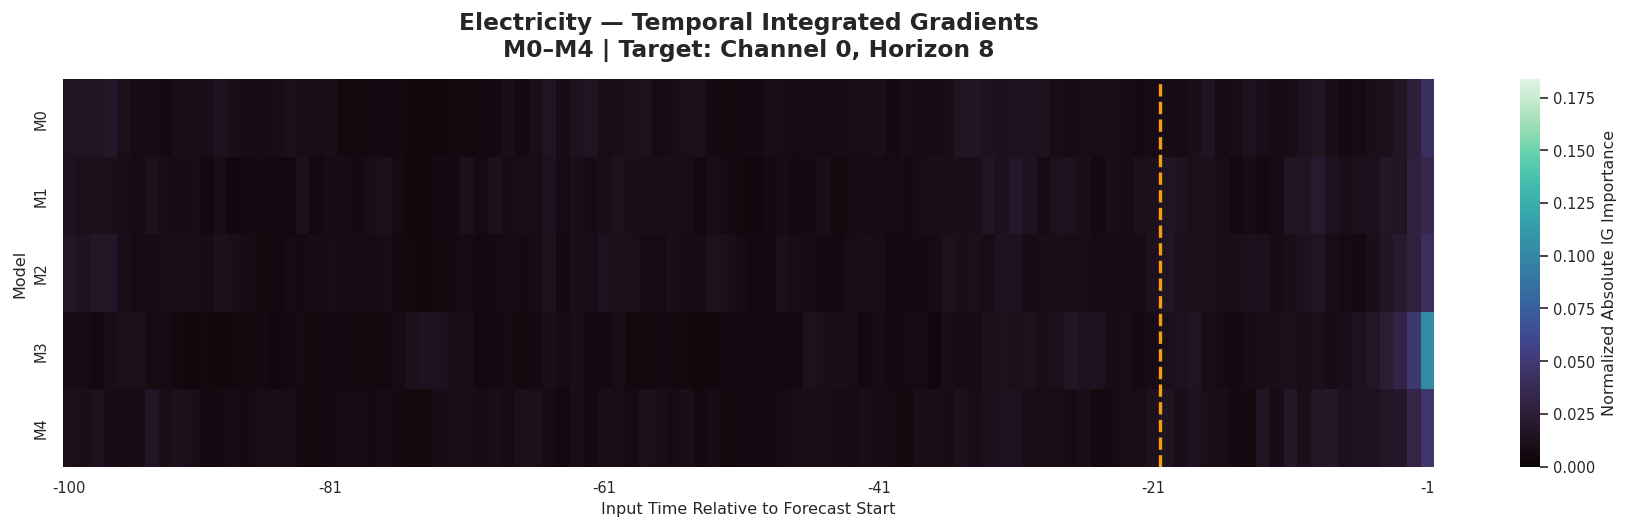

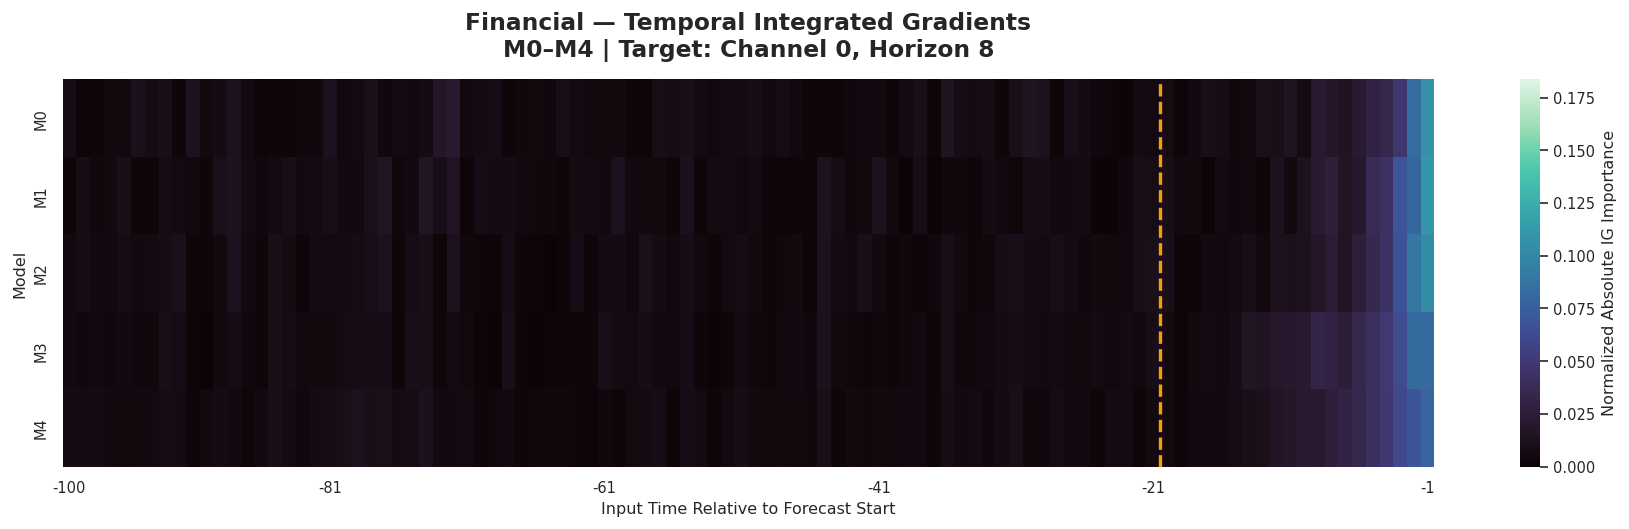

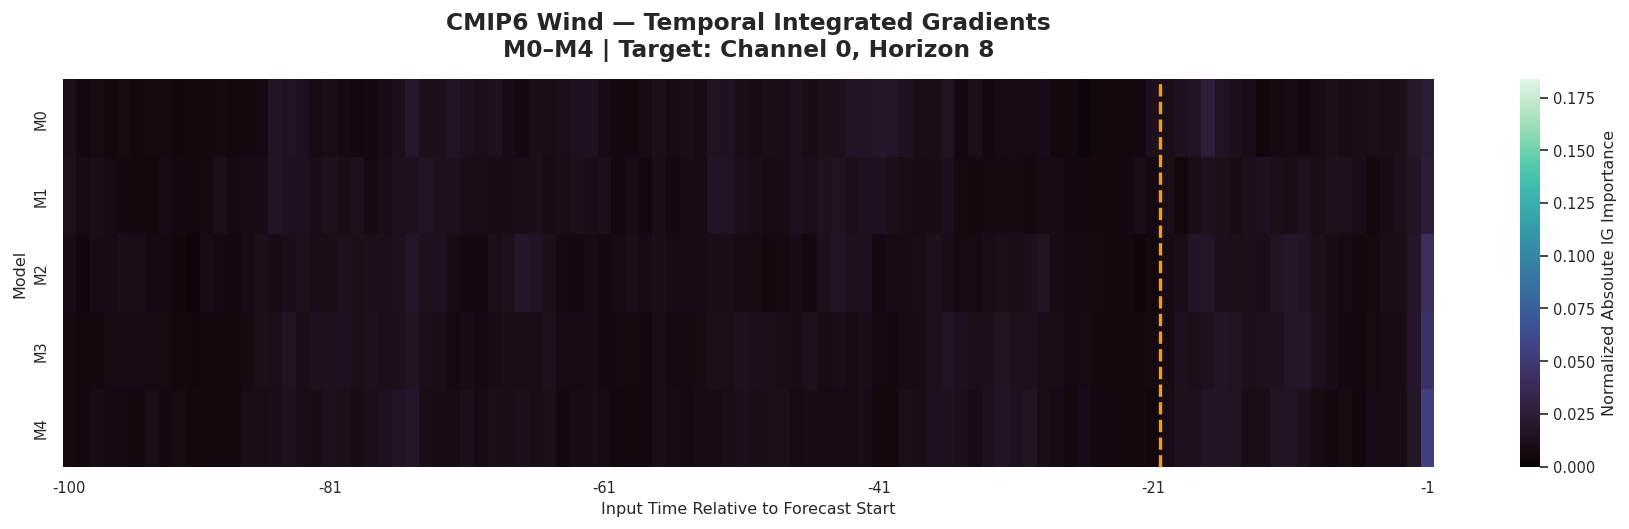

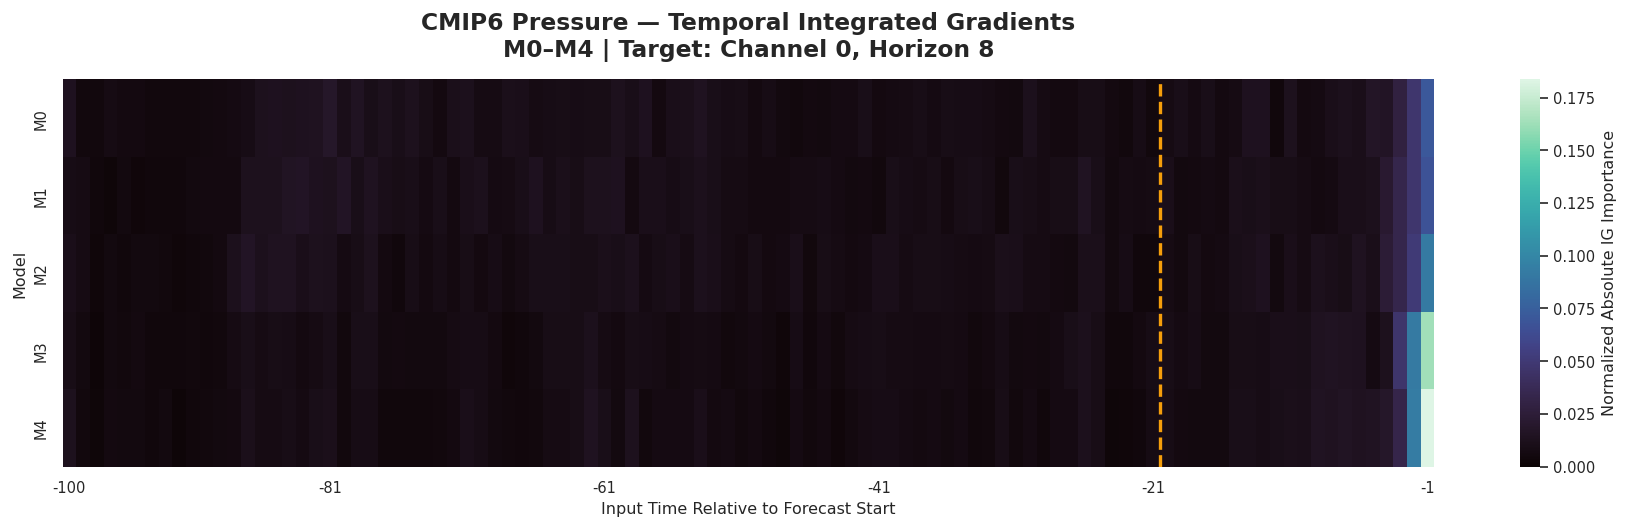

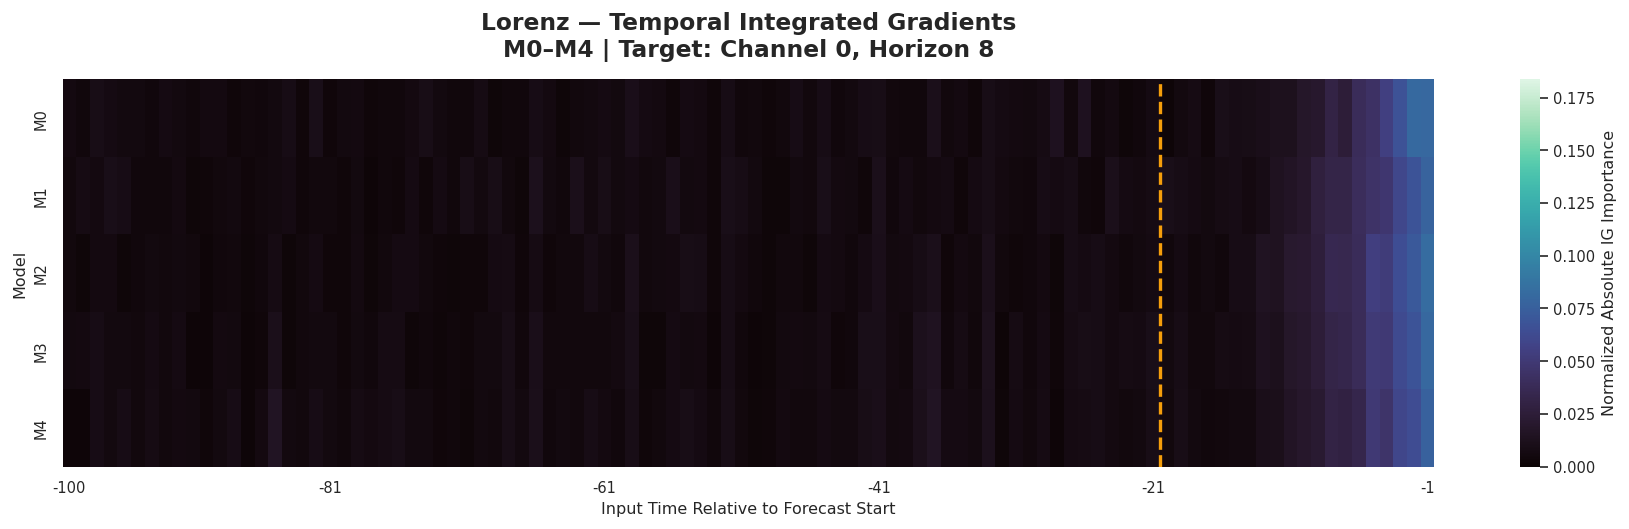

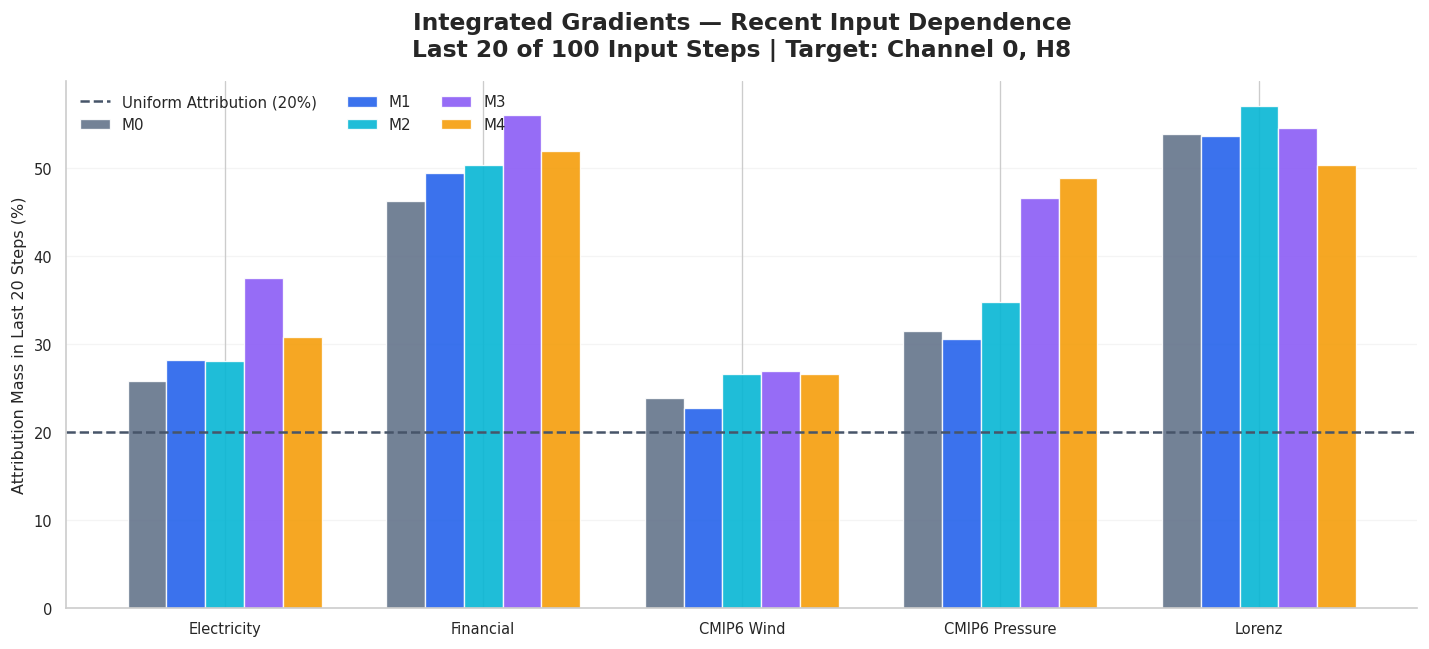

IG TEMPORAL ATTRIBUTION — LAST 20 STEPS


model,M0,M1,M2,M3,M4
dataset,,,,,
Electricity,25.85%,28.26%,28.07%,37.51%,30.87%
Financial,46.24%,49.45%,50.37%,56.09%,52.03%
CMIP6 Wind,23.93%,22.78%,26.61%,26.94%,26.61%
CMIP6 Pressure,31.46%,30.60%,34.76%,46.64%,48.90%
Lorenz,53.96%,53.66%,57.07%,54.55%,50.43%



RECENCY ENRICHMENT VS UNIFORM ATTRIBUTION


model,M0,M1,M2,M3,M4
dataset,,,,,
Electricity,1.29x,1.41x,1.40x,1.88x,1.54x
Financial,2.31x,2.47x,2.52x,2.80x,2.60x
CMIP6 Wind,1.20x,1.14x,1.33x,1.35x,1.33x
CMIP6 Pressure,1.57x,1.53x,1.74x,2.33x,2.45x
Lorenz,2.70x,2.68x,2.85x,2.73x,2.52x



PEAK ATTRIBUTION LAG


model,M0,M1,M2,M3,M4
dataset,,,,,
Electricity,1,1,1,1,1
Financial,1,1,1,2,1
CMIP6 Wind,17,1,1,1,1
CMIP6 Pressure,1,1,1,1,1
Lorenz,2,1,1,1,1



[PASS] IG temporal attribution analysis completed


In [2]:
IG_RECENT_STEPS = 20

temporal_records = []
temporal_maps = {}

for dataset, dataset_key in DATASET_MAP.items():
    model_profiles = []

    for model in MODELS:
        ig = xai_data[dataset]["models"][model][
            "arrays"
        ]["ig_attributions"].astype(np.float64)

        assert ig.shape == (
            8,
            LOOKBACK,
            xai_data[dataset]["channels"]
        )

        absolute_ig = np.abs(ig)

        temporal_importance = absolute_ig.mean(
            axis=(0, 2)
        )

        total_importance = temporal_importance.sum()

        assert np.isfinite(total_importance)
        assert total_importance > 0

        normalized = (
            temporal_importance / total_importance
        )

        assert np.isclose(normalized.sum(), 1)

        recent_mass = float(
            normalized[-IG_RECENT_STEPS:].sum()
        )

        early_mass = float(
            normalized[:IG_RECENT_STEPS].sum()
        )

        peak_position = int(
            np.argmax(normalized)
        )

        entropy = float(
            -np.sum(
                normalized * np.log(
                    np.clip(normalized, 1e-15, None)
                )
            ) / np.log(LOOKBACK)
        )

        temporal_records.append({
            "dataset": dataset,
            "model": model,
            "recent_20_pct": 100 * recent_mass,
            "early_20_pct": 100 * early_mass,
            "recent_enrichment": (
                recent_mass / (IG_RECENT_STEPS / LOOKBACK)
            ),
            "peak_lag": LOOKBACK - peak_position,
            "normalized_entropy": entropy,
            "mean_abs_ig": float(absolute_ig.mean())
        })

        model_profiles.append(normalized)

    temporal_maps[dataset] = np.stack(
        model_profiles,
        axis=0
    )

temporal_df = pd.DataFrame(temporal_records)

assert len(temporal_df) == 25

assert all(
    matrix.shape == (5, LOOKBACK)
    for matrix in temporal_maps.values()
)

global_max = max(
    matrix.max()
    for matrix in temporal_maps.values()
)

for dataset, dataset_key in DATASET_MAP.items():
    matrix = temporal_maps[dataset]

    fig, ax = plt.subplots(
        figsize=(15, 4.5)
    )

    sns.heatmap(
        matrix,
        cmap="mako",
        vmin=0,
        vmax=global_max,
        xticklabels=False,
        yticklabels=MODELS,
        cbar_kws={
            "label": "Normalized Absolute IG Importance"
        },
        ax=ax
    )

    ax.axvline(
        LOOKBACK - IG_RECENT_STEPS,
        color="#F59E0B",
        linestyle="--",
        linewidth=2
    )

    tick_positions = np.array(
        [0, 19, 39, 59, 79, 99]
    )

    ax.set_xticks(
        tick_positions + 0.5
    )

    ax.set_xticklabels(
        [f"-{LOOKBACK - t}" for t in tick_positions],
        rotation=0
    )

    ax.set_title(
        f"{dataset} — Temporal Integrated Gradients\n"
        "M0–M4 | Target: Channel 0, Horizon 8",
        fontsize=14,
        fontweight="bold",
        pad=14
    )

    ax.set_xlabel(
        "Input Time Relative to Forecast Start"
    )

    ax.set_ylabel("Model")

    fig.tight_layout()

    fig.savefig(
        FIGURES_DIR / f"fig01_ig_temporal_{dataset_key}.png",
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        FIGURES_DIR / f"fig01_ig_temporal_{dataset_key}.pdf",
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

recent_table = temporal_df.pivot(
    index="dataset",
    columns="model",
    values="recent_20_pct"
).reindex(
    index=DATASETS,
    columns=MODELS
)

fig, ax = plt.subplots(
    figsize=(12, 5.5)
)

x = np.arange(len(DATASETS))
width = 0.15

for i, model in enumerate(MODELS):
    offset = (
        i - (len(MODELS) - 1) / 2
    ) * width

    ax.bar(
        x + offset,
        recent_table[model],
        width,
        label=model,
        color=MODEL_COLORS[model],
        alpha=0.9
    )

ax.axhline(
    20,
    color="#475569",
    linestyle="--",
    linewidth=1.5,
    label="Uniform Attribution (20%)"
)

ax.set_xticks(x)
ax.set_xticklabels(DATASETS)

ax.set_ylabel(
    "Attribution Mass in Last 20 Steps (%)"
)

ax.set_title(
    "Integrated Gradients — Recent Input Dependence\n"
    "Last 20 of 100 Input Steps | Target: Channel 0, H8",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.legend(
    ncol=3,
    frameon=False,
    fontsize=9
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "fig02_ig_recent20_comparison.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig02_ig_recent20_comparison.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("IG TEMPORAL ATTRIBUTION — LAST 20 STEPS")

display(
    recent_table.style.format("{:.2f}%")
)

print("\nRECENCY ENRICHMENT VS UNIFORM ATTRIBUTION")

display(
    temporal_df.pivot(
        index="dataset",
        columns="model",
        values="recent_enrichment"
    ).reindex(
        index=DATASETS,
        columns=MODELS
    ).style.format("{:.2f}x")
)

print("\nPEAK ATTRIBUTION LAG")

display(
    temporal_df.pivot(
        index="dataset",
        columns="model",
        values="peak_lag"
    ).reindex(
        index=DATASETS,
        columns=MODELS
    )
)

temporal_df.to_csv(
    FIGURES_DIR / "ig_temporal_summary.csv",
    index=False
)

for dataset, dataset_key in DATASET_MAP.items():
    pd.DataFrame(
        temporal_maps[dataset],
        index=MODELS,
        columns=[
            f"lag_{LOOKBACK - t}"
            for t in range(LOOKBACK)
        ]
    ).to_csv(
        FIGURES_DIR / f"ig_temporal_profile_{dataset_key}.csv"
    )

print("\n[PASS] IG temporal attribution analysis completed")


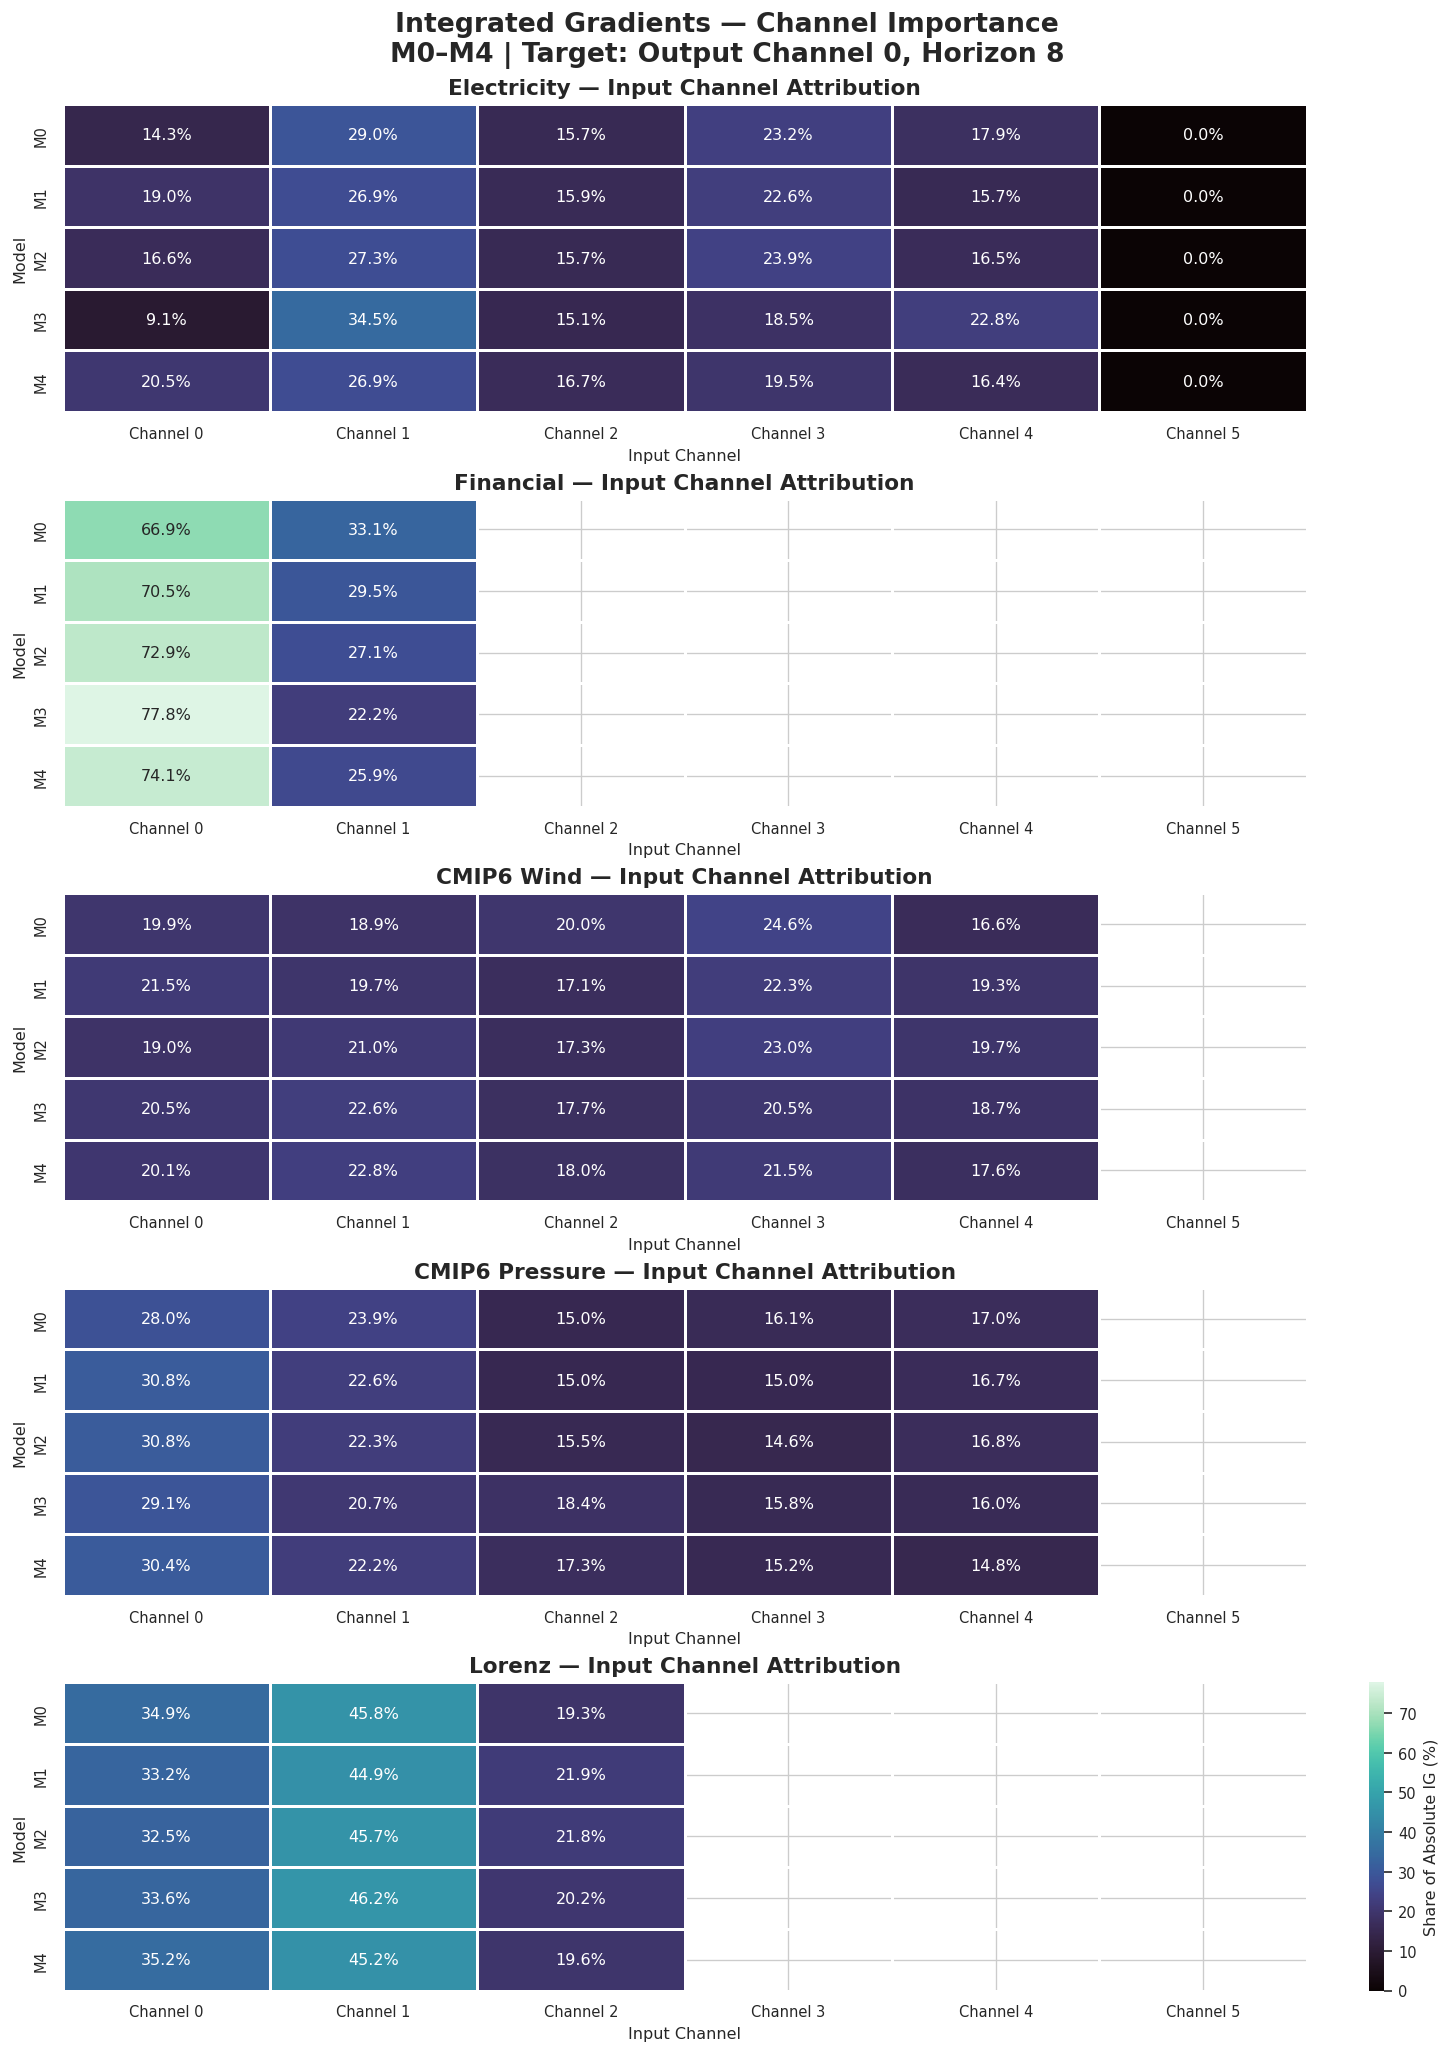

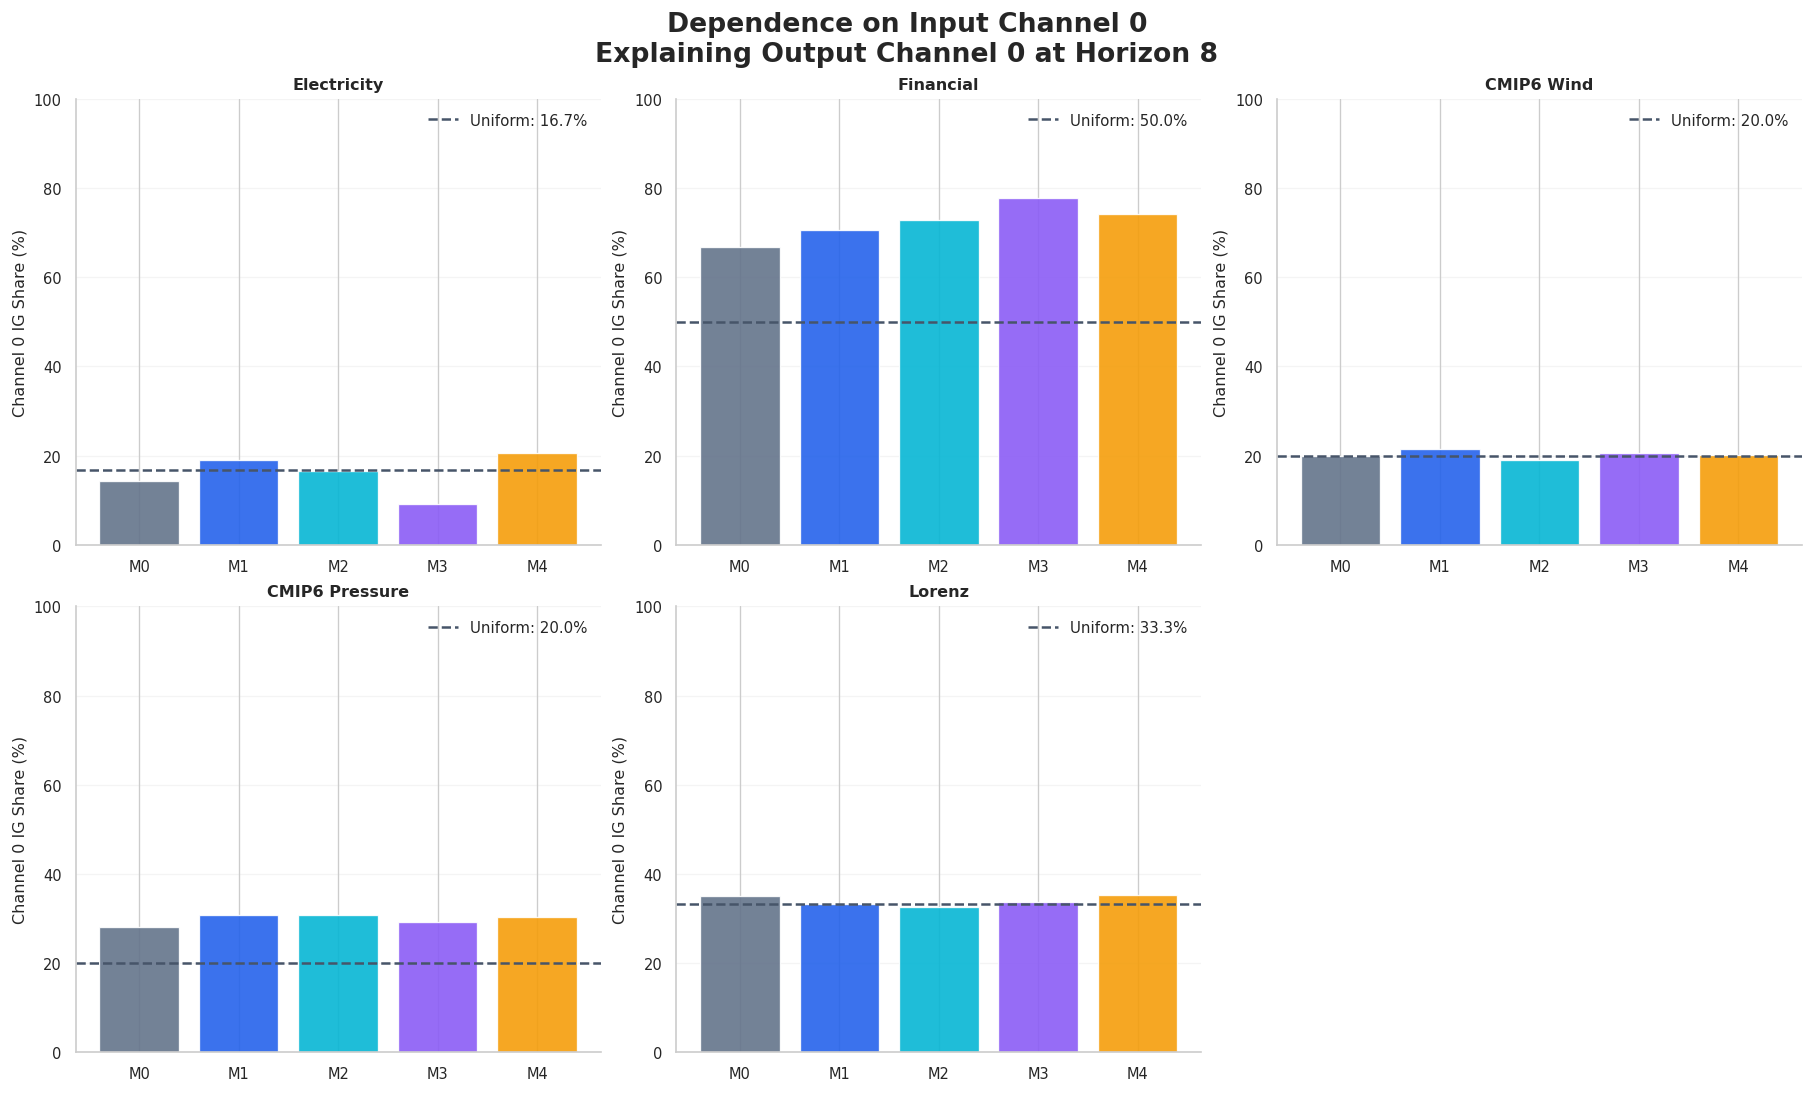

DOMINANT INPUT CHANNEL BY MODEL


model,M0,M1,M2,M3,M4
dataset,,,,,
Electricity,1,1,1,1,1
Financial,0,0,0,0,0
CMIP6 Wind,3,3,3,1,1
CMIP6 Pressure,0,0,0,0,0
Lorenz,1,1,1,1,1



INPUT CHANNEL 0 ATTRIBUTION SHARE


model,M0,M1,M2,M3,M4
dataset,,,,,
Electricity,14.28%,18.99%,16.60%,9.15%,20.50%
Financial,66.86%,70.55%,72.90%,77.79%,74.14%
CMIP6 Wind,19.87%,21.47%,19.02%,20.50%,20.09%
CMIP6 Pressure,28.02%,30.78%,30.78%,29.11%,30.43%
Lorenz,34.94%,33.21%,32.54%,33.62%,35.24%



CHANNEL ATTRIBUTION ENTROPY


model,M0,M1,M2,M3,M4
dataset,,,,,
Electricity,0.878,0.886,0.883,0.848,0.889
Financial,0.916,0.875,0.843,0.764,0.825
CMIP6 Wind,0.995,0.997,0.997,0.998,0.997
CMIP6 Pressure,0.981,0.973,0.974,0.983,0.975
Lorenz,0.949,0.963,0.961,0.953,0.952



[PASS] IG channel attribution analysis completed


In [3]:
channel_records = []
channel_summary_records = []
channel_profiles = {}

for dataset, dataset_key in DATASET_MAP.items():
    channels = xai_data[dataset]["channels"]
    model_profiles = []

    for model in MODELS:
        ig = xai_data[dataset]["models"][model][
            "arrays"
        ]["ig_attributions"].astype(np.float64)

        assert ig.shape == (8, LOOKBACK, channels)
        assert np.isfinite(ig).all()

        channel_importance = np.abs(ig).mean(
            axis=(0, 1)
        )

        total_importance = channel_importance.sum()

        assert total_importance > 0

        normalized = (
            channel_importance / total_importance
        )

        np.testing.assert_allclose(
            normalized.sum(), 1.0, atol=1e-8
        )

        model_profiles.append(normalized)

        dominant_channel = int(
            np.argmax(normalized)
        )

        channel_entropy = float(
            -np.sum(
                normalized * np.log(
                    np.clip(normalized, 1e-15, None)
                )
            ) / np.log(channels)
        )

        for channel in range(channels):
            channel_records.append({
                "dataset": dataset,
                "model": model,
                "input_channel": channel,
                "target_channel": 0,
                "target_horizon": HORIZON,
                "mean_abs_ig": float(
                    channel_importance[channel]
                ),
                "attribution_share_pct": float(
                    normalized[channel] * 100
                )
            })

        channel_summary_records.append({
            "dataset": dataset,
            "model": model,
            "n_channels": channels,
            "dominant_input_channel": dominant_channel,
            "dominant_share_pct": float(
                normalized[dominant_channel] * 100
            ),
            "target_input_share_pct": float(
                normalized[0] * 100
            ),
            "uniform_share_pct": 100 / channels,
            "normalized_channel_entropy": channel_entropy
        })

    channel_profiles[dataset] = np.stack(
        model_profiles, axis=0
    )

channel_attribution_df = pd.DataFrame(channel_records)
channel_summary_df = pd.DataFrame(channel_summary_records)

assert len(channel_summary_df) == 25

max_channels = max(
    xai_data[dataset]["channels"]
    for dataset in DATASETS
)

global_max = max(
    matrix.max()
    for matrix in channel_profiles.values()
) * 100

fig, axes = plt.subplots(
    5, 1,
    figsize=(12, 17),
    constrained_layout=True
)

for i, (dataset, dataset_key) in enumerate(
    DATASET_MAP.items()
):
    matrix = channel_profiles[dataset] * 100

    padded = np.full(
        (len(MODELS), max_channels),
        np.nan
    )

    padded[:, :matrix.shape[1]] = matrix

    labels = np.full(
        padded.shape,
        "",
        dtype=object
    )

    for row in range(len(MODELS)):
        for col in range(matrix.shape[1]):
            labels[row, col] = (
                f"{matrix[row, col]:.1f}%"
            )

    sns.heatmap(
        padded,
        annot=labels,
        fmt="",
        cmap="mako",
        vmin=0,
        vmax=global_max,
        mask=np.isnan(padded),
        xticklabels=[
            f"Channel {j}"
            for j in range(max_channels)
        ],
        yticklabels=MODELS,
        linewidths=0.8,
        linecolor="white",
        cbar=(i == 4),
        cbar_kws={
            "label": "Share of Absolute IG (%)"
        } if i == 4 else None,
        ax=axes[i]
    )

    axes[i].set_title(
        f"{dataset} — Input Channel Attribution",
        fontsize=13,
        fontweight="bold"
    )

    axes[i].set_xlabel("Input Channel")
    axes[i].set_ylabel("Model")

    axes[i].tick_params(
        axis="x", rotation=0
    )

fig.suptitle(
    "Integrated Gradients — Channel Importance\n"
    "M0–M4 | Target: Output Channel 0, Horizon 8",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig03_ig_channel_importance.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig03_ig_channel_importance.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 9),
    constrained_layout=True
)

axes = axes.flatten()

for i, dataset in enumerate(DATASETS):
    subset = (
        channel_summary_df[
            channel_summary_df["dataset"] == dataset
        ]
        .set_index("model")
        .reindex(MODELS)
    )

    ax = axes[i]

    ax.bar(
        MODELS,
        subset["target_input_share_pct"],
        color=[
            MODEL_COLORS[model]
            for model in MODELS
        ],
        alpha=0.9
    )

    uniform_share = float(
        subset["uniform_share_pct"].iloc[0]
    )

    ax.axhline(
        uniform_share,
        color="#475569",
        linestyle="--",
        linewidth=1.5,
        label=f"Uniform: {uniform_share:.1f}%"
    )

    ax.set_title(dataset, fontweight="bold")
    ax.set_ylabel("Channel 0 IG Share (%)")
    ax.set_ylim(
        0,
        max(
            100,
            subset["target_input_share_pct"].max() * 1.1
        )
    )
    ax.grid(axis="y", alpha=0.2)
    ax.legend(frameon=False, fontsize=9)

axes[-1].axis("off")

fig.suptitle(
    "Dependence on Input Channel 0\n"
    "Explaining Output Channel 0 at Horizon 8",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig04_ig_target_channel_share.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig04_ig_target_channel_share.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("DOMINANT INPUT CHANNEL BY MODEL")

display(
    channel_summary_df.pivot(
        index="dataset",
        columns="model",
        values="dominant_input_channel"
    ).reindex(
        index=DATASETS,
        columns=MODELS
    )
)

print("\nINPUT CHANNEL 0 ATTRIBUTION SHARE")

display(
    channel_summary_df.pivot(
        index="dataset",
        columns="model",
        values="target_input_share_pct"
    ).reindex(
        index=DATASETS,
        columns=MODELS
    ).style.format("{:.2f}%")
)

print("\nCHANNEL ATTRIBUTION ENTROPY")

display(
    channel_summary_df.pivot(
        index="dataset",
        columns="model",
        values="normalized_channel_entropy"
    ).reindex(
        index=DATASETS,
        columns=MODELS
    ).style.format("{:.3f}")
)

channel_attribution_df.to_csv(
    FIGURES_DIR / "ig_channel_attribution.csv",
    index=False
)

channel_summary_df.to_csv(
    FIGURES_DIR / "ig_channel_summary.csv",
    index=False
)

print("\n[PASS] IG channel attribution analysis completed")


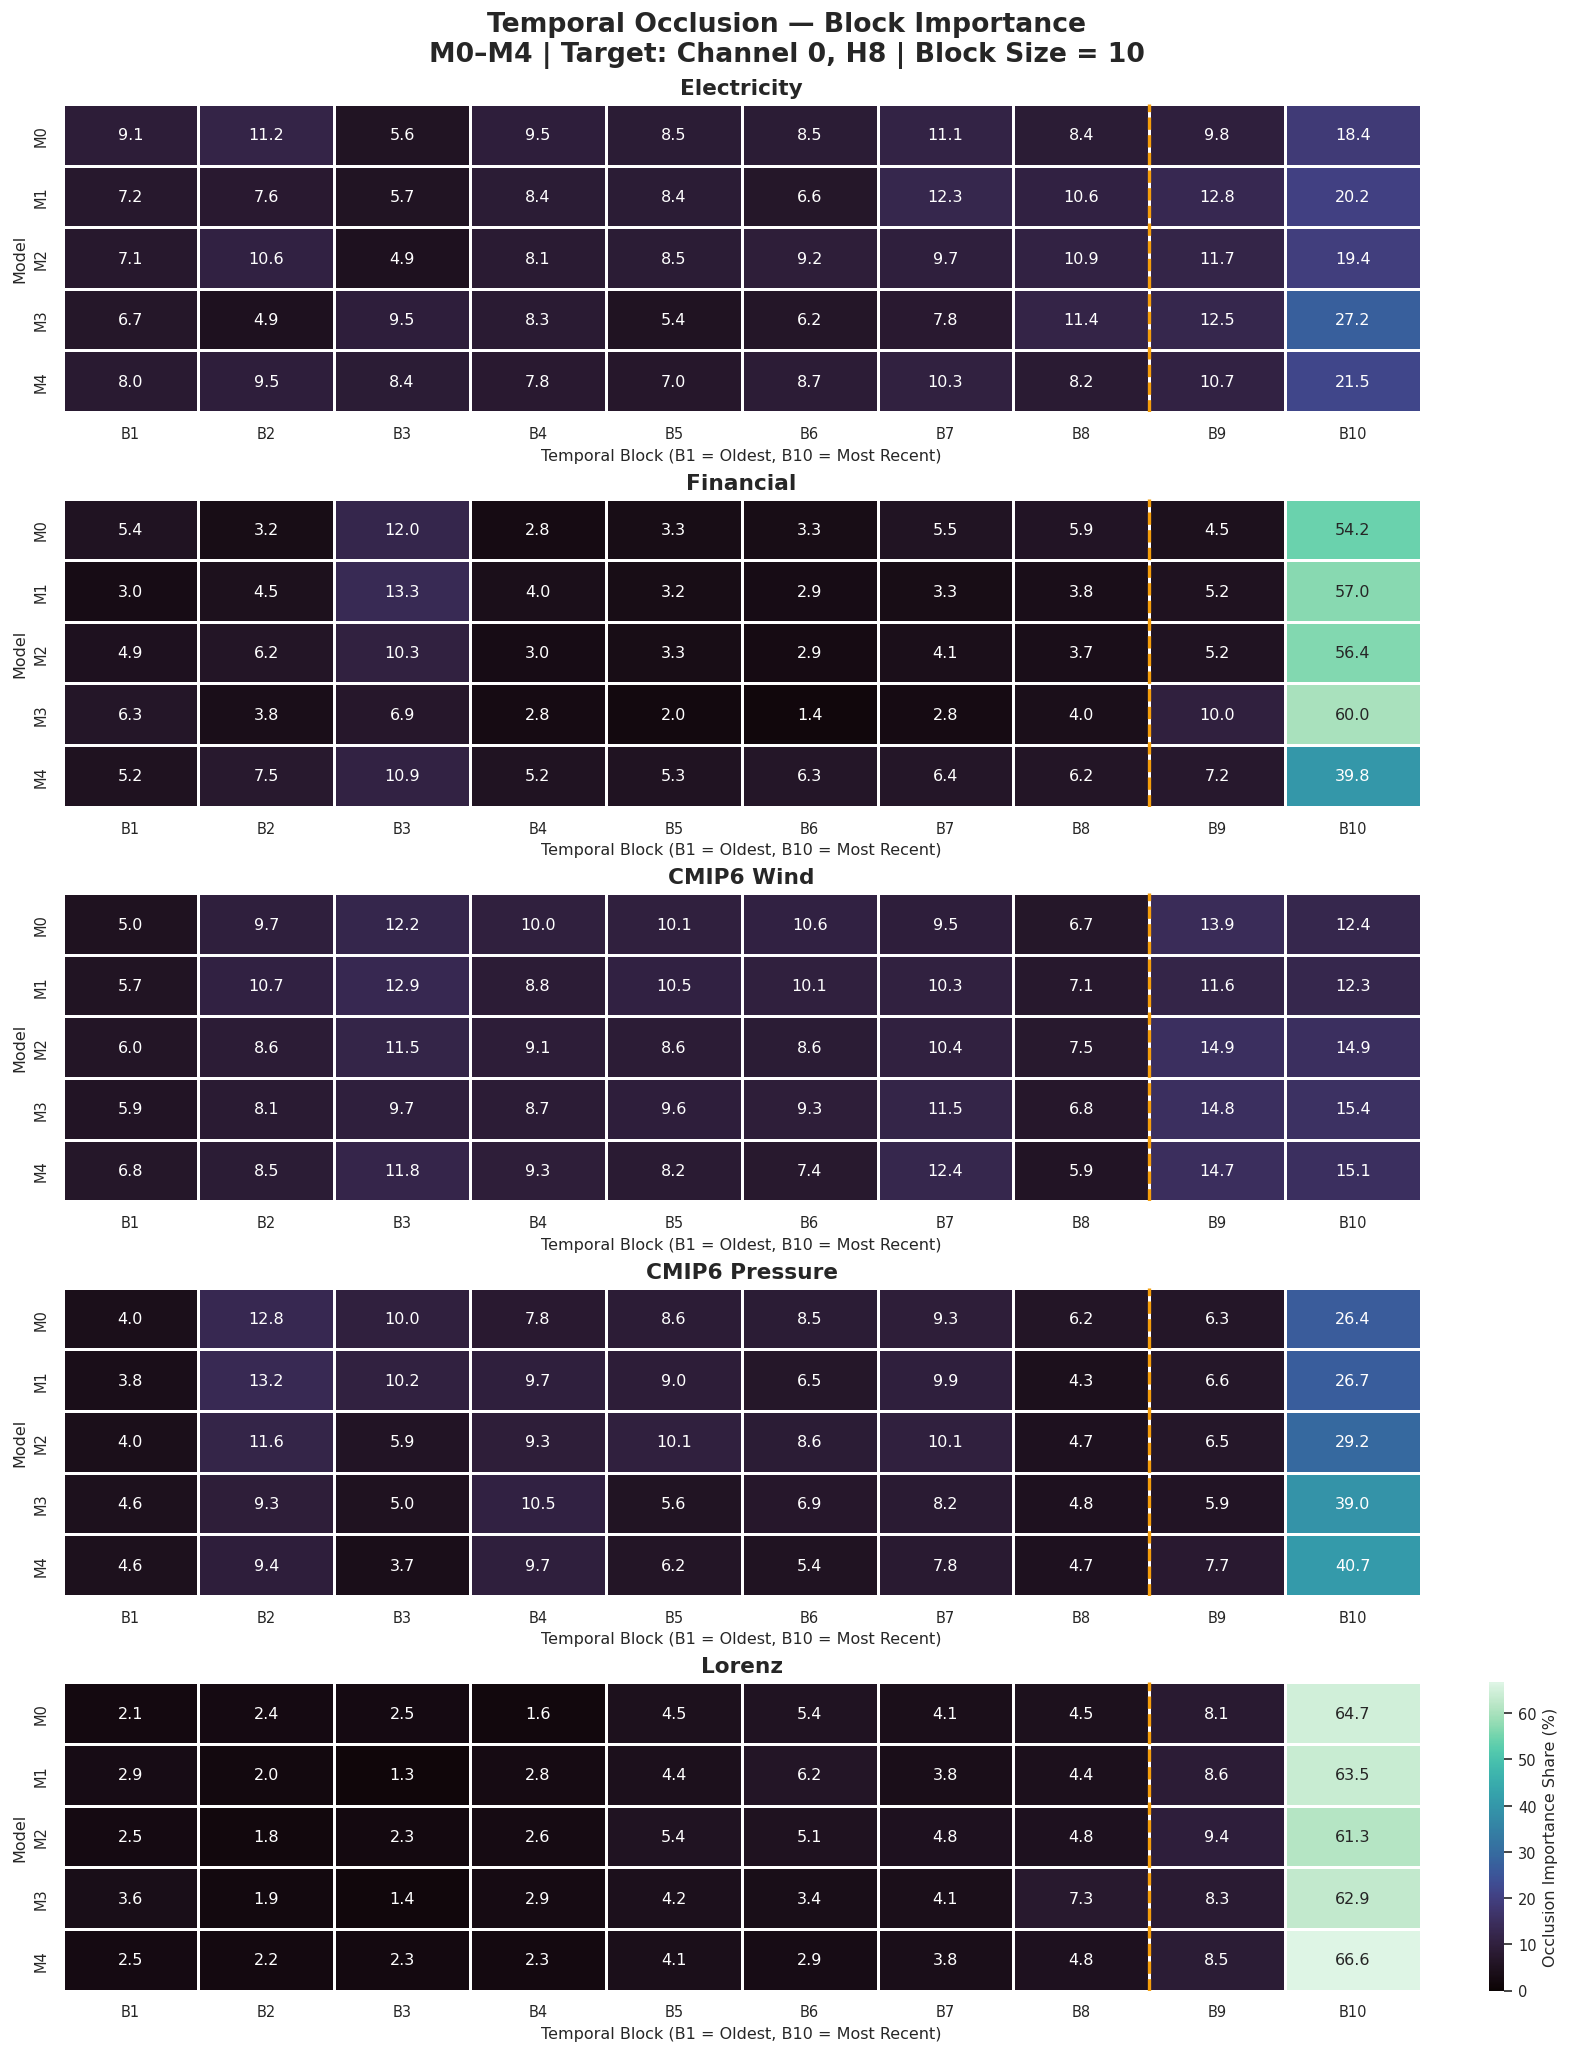

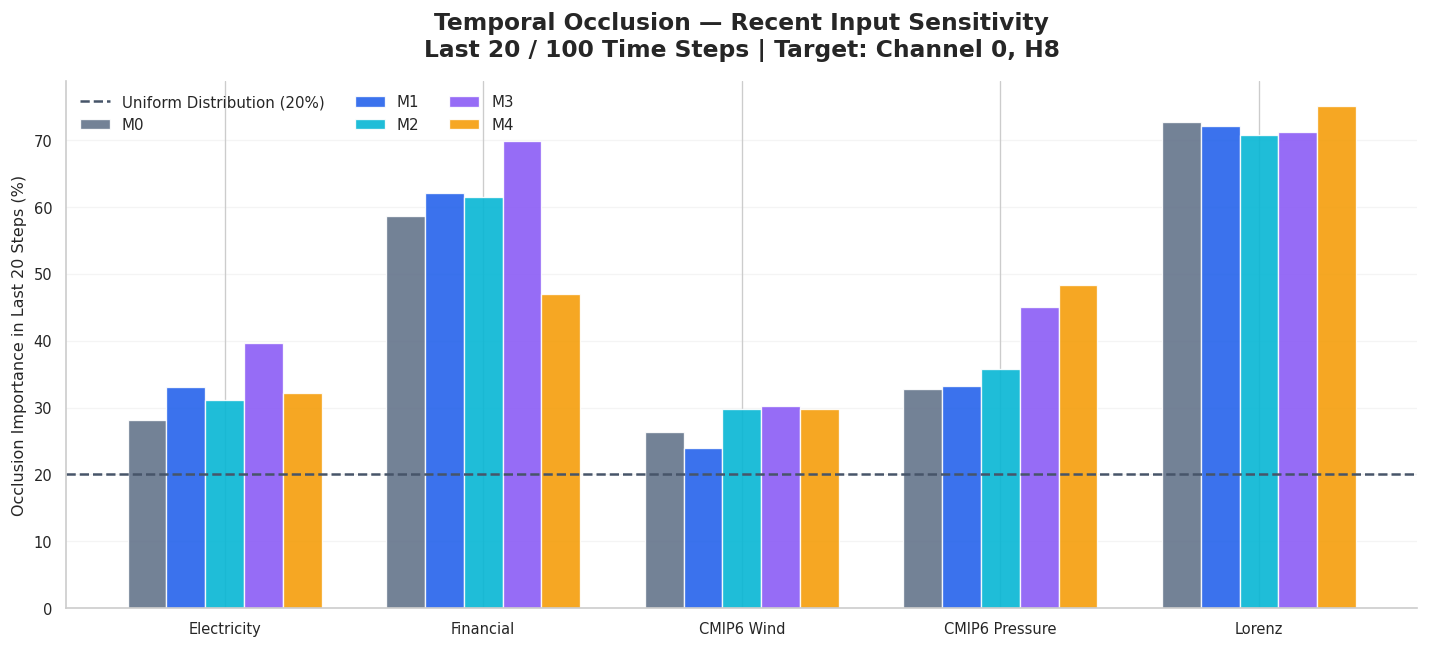

OCCLUSION — LAST 20 STEPS


model,M0,M1,M2,M3,M4
dataset,,,,,
Electricity,28.12%,33.05%,31.09%,39.74%,32.23%
Financial,58.68%,62.13%,61.59%,69.91%,47.05%
CMIP6 Wind,26.36%,23.93%,29.79%,30.28%,29.75%
CMIP6 Pressure,32.76%,33.30%,35.77%,44.99%,48.37%
Lorenz,72.75%,72.13%,70.78%,71.19%,75.10%



MOST SENSITIVE TEMPORAL BLOCK


model,M0,M1,M2,M3,M4
dataset,,,,,
Electricity,10,10,10,10,10
Financial,10,10,10,10,10
CMIP6 Wind,9,3,9,10,10
CMIP6 Pressure,10,10,10,10,10
Lorenz,10,10,10,10,10



OCCLUSION ENTROPY


model,M0,M1,M2,M3,M4
dataset,,,,,
Electricity,0.980,0.968,0.974,0.934,0.972
Financial,0.713,0.678,0.697,0.646,0.859
CMIP6 Wind,0.985,0.989,0.983,0.981,0.979
CMIP6 Pressure,0.939,0.930,0.921,0.861,0.847
Lorenz,0.601,0.612,0.638,0.619,0.579



[PASS] Temporal occlusion analysis completed


In [4]:
BLOCK_SIZE = 10
N_BLOCKS = LOOKBACK // BLOCK_SIZE

assert LOOKBACK % BLOCK_SIZE == 0

occlusion_records = []
occlusion_block_records = []
occlusion_profiles = {}

for dataset, dataset_key in DATASET_MAP.items():
    profiles = []
    channels = xai_data[dataset]["channels"]

    for model in MODELS:
        entry = xai_data[dataset]["models"][model]
        arrays = entry["arrays"]
        metadata = entry["metadata"]

        occ = arrays["occlusion_impacts"].astype(np.float64)

        assert occ.shape == (8, LOOKBACK, channels)
        assert np.isfinite(occ).all()
        assert metadata["occlusion_block_size"] == BLOCK_SIZE

        block_importance = []
        block_signed_effect = []

        for block in range(N_BLOCKS):
            start = block * BLOCK_SIZE
            end = start + BLOCK_SIZE

            values = occ[:, start:end, :]

            np.testing.assert_allclose(
                values,
                np.broadcast_to(
                    values[:, :1, :],
                    values.shape
                ),
                rtol=0,
                atol=1e-6
            )

            importance = float(
                np.abs(values).mean()
            )

            signed_effect = float(
                values.mean()
            )

            block_importance.append(importance)
            block_signed_effect.append(signed_effect)

        block_importance = np.asarray(
            block_importance
        )

        block_signed_effect = np.asarray(
            block_signed_effect
        )

        total = block_importance.sum()
        assert total > 0

        normalized = block_importance / total

        np.testing.assert_allclose(
            normalized.sum(),
            1.0,
            atol=1e-8
        )

        profiles.append(normalized)

        recent_share = float(
            normalized[-2:].sum()
        )

        early_share = float(
            normalized[:2].sum()
        )

        entropy = float(
            -np.sum(
                normalized * np.log(
                    np.clip(normalized, 1e-15, None)
                )
            ) / np.log(N_BLOCKS)
        )

        occlusion_records.append({
            "dataset": dataset,
            "model": model,
            "recent_20_pct": recent_share * 100,
            "early_20_pct": early_share * 100,
            "recent_enrichment": recent_share / 0.2,
            "peak_block": int(np.argmax(normalized)) + 1,
            "normalized_entropy": entropy,
            "mean_abs_occlusion": float(
                np.abs(occ).mean()
            )
        })

        for block in range(N_BLOCKS):
            occlusion_block_records.append({
                "dataset": dataset,
                "model": model,
                "block": block + 1,
                "start_step": block * BLOCK_SIZE + 1,
                "end_step": (block + 1) * BLOCK_SIZE,
                "mean_abs_impact": block_importance[block],
                "mean_signed_impact": block_signed_effect[block],
                "importance_share_pct": normalized[block] * 100
            })

    occlusion_profiles[dataset] = np.stack(
        profiles,
        axis=0
    )

occlusion_df = pd.DataFrame(occlusion_records)
occlusion_block_df = pd.DataFrame(
    occlusion_block_records
)

assert len(occlusion_df) == 25
assert len(occlusion_block_df) == 250

fig, axes = plt.subplots(
    5, 1,
    figsize=(13, 17),
    constrained_layout=True
)

global_max = max(
    matrix.max()
    for matrix in occlusion_profiles.values()
) * 100

for i, dataset in enumerate(DATASETS):
    matrix = occlusion_profiles[dataset] * 100

    sns.heatmap(
        matrix,
        annot=True,
        fmt=".1f",
        cmap="mako",
        vmin=0,
        vmax=global_max,
        xticklabels=[
            f"B{b}" for b in range(1, N_BLOCKS + 1)
        ],
        yticklabels=MODELS,
        linewidths=0.8,
        linecolor="white",
        cbar=(i == 4),
        cbar_kws={
            "label": "Occlusion Importance Share (%)"
        } if i == 4 else None,
        ax=axes[i]
    )

    axes[i].axvline(
        N_BLOCKS - 2,
        color="#F59E0B",
        linestyle="--",
        linewidth=2
    )

    axes[i].set_title(
        dataset,
        fontsize=13,
        fontweight="bold"
    )

    axes[i].set_xlabel(
        "Temporal Block (B1 = Oldest, B10 = Most Recent)"
    )

    axes[i].set_ylabel("Model")

fig.suptitle(
    "Temporal Occlusion — Block Importance\n"
    "M0–M4 | Target: Channel 0, H8 | Block Size = 10",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig05_occlusion_temporal_heatmap.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig05_occlusion_temporal_heatmap.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

recent_table = occlusion_df.pivot(
    index="dataset",
    columns="model",
    values="recent_20_pct"
).reindex(
    index=DATASETS,
    columns=MODELS
)

fig, ax = plt.subplots(
    figsize=(12, 5.5)
)

x = np.arange(len(DATASETS))
width = 0.15

for i, model in enumerate(MODELS):
    offset = (
        i - (len(MODELS) - 1) / 2
    ) * width

    ax.bar(
        x + offset,
        recent_table[model],
        width,
        color=MODEL_COLORS[model],
        label=model,
        alpha=0.9
    )

ax.axhline(
    20,
    color="#475569",
    linestyle="--",
    linewidth=1.5,
    label="Uniform Distribution (20%)"
)

ax.set_xticks(x)
ax.set_xticklabels(DATASETS)

ax.set_ylabel(
    "Occlusion Importance in Last 20 Steps (%)"
)

ax.set_title(
    "Temporal Occlusion — Recent Input Sensitivity\n"
    "Last 20 / 100 Time Steps | Target: Channel 0, H8",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.legend(
    ncol=3,
    frameon=False,
    fontsize=9
)

ax.grid(
    axis="y",
    alpha=0.2
)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "fig06_occlusion_recent20.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig06_occlusion_recent20.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("OCCLUSION — LAST 20 STEPS")
display(
    recent_table.style.format("{:.2f}%")
)

print("\nMOST SENSITIVE TEMPORAL BLOCK")
display(
    occlusion_df.pivot(
        index="dataset",
        columns="model",
        values="peak_block"
    ).reindex(
        index=DATASETS,
        columns=MODELS
    )
)

print("\nOCCLUSION ENTROPY")
display(
    occlusion_df.pivot(
        index="dataset",
        columns="model",
        values="normalized_entropy"
    ).reindex(
        index=DATASETS,
        columns=MODELS
    ).style.format("{:.3f}")
)

occlusion_df.to_csv(
    FIGURES_DIR / "occlusion_temporal_summary.csv",
    index=False
)

occlusion_block_df.to_csv(
    FIGURES_DIR / "occlusion_block_importance.csv",
    index=False
)

for dataset, dataset_key in DATASET_MAP.items():
    pd.DataFrame(
        occlusion_profiles[dataset],
        index=MODELS,
        columns=[
            f"block_{i+1}"
            for i in range(N_BLOCKS)
        ]
    ).to_csv(
        FIGURES_DIR / f"occlusion_profile_{dataset_key}.csv"
    )

print("\n[PASS] Temporal occlusion analysis completed")


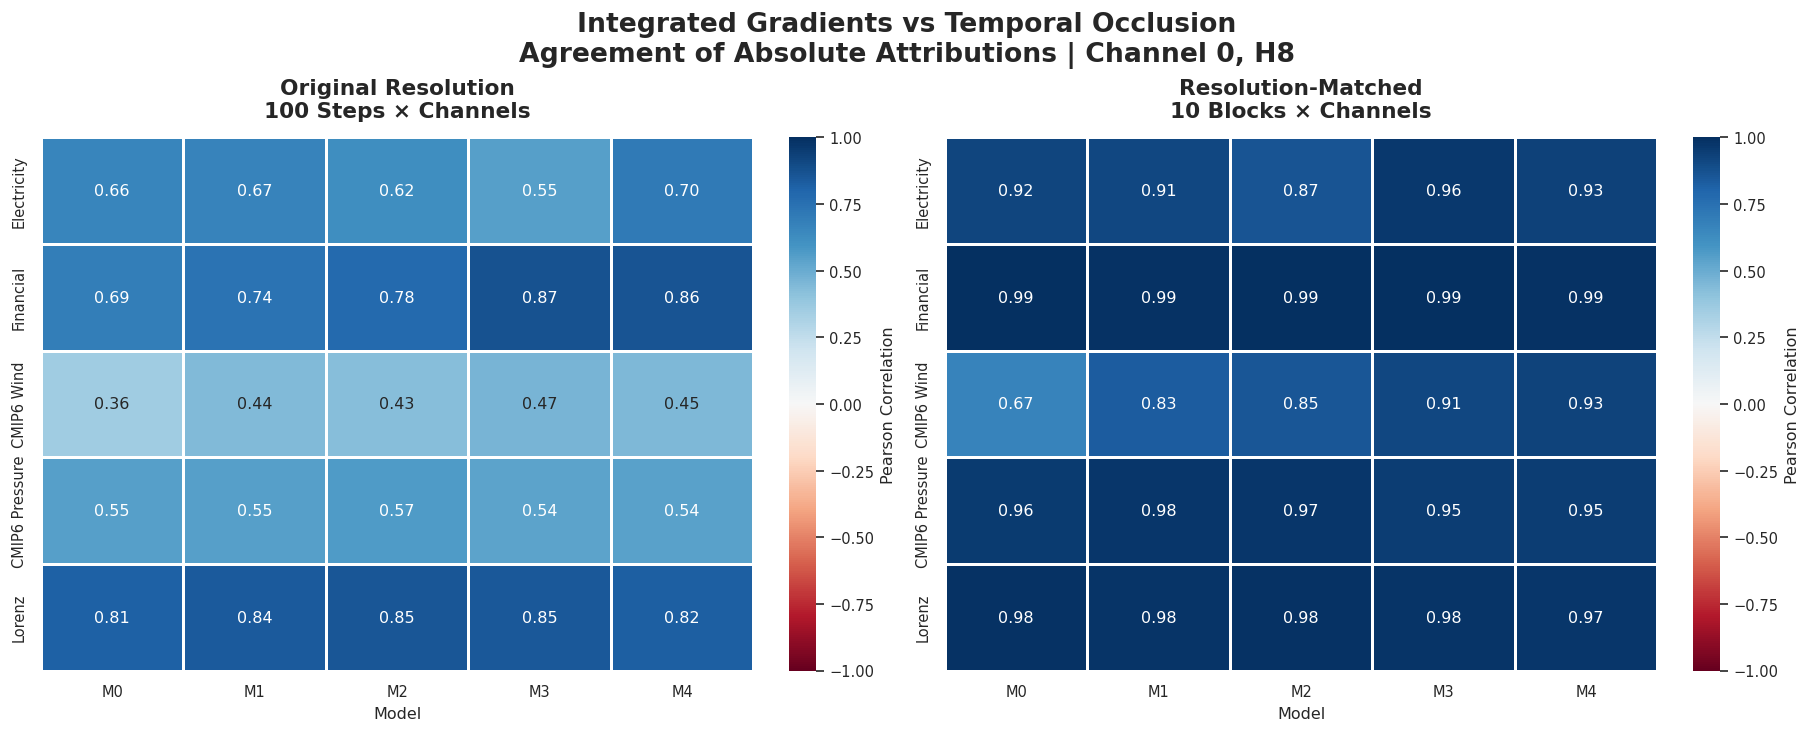

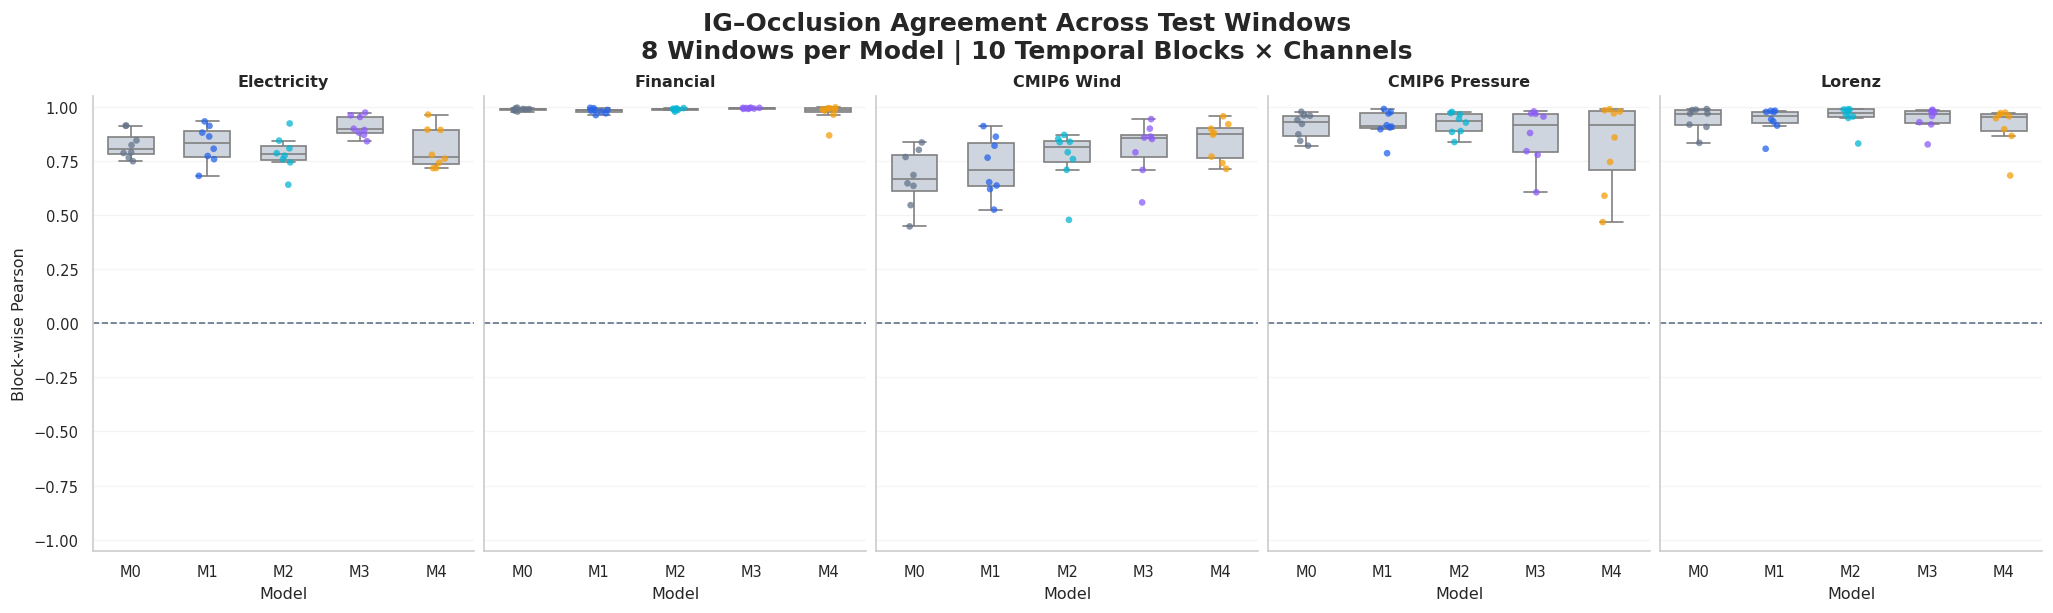

ORIGINAL PEARSON — VERIFIED AGAINST XAI SUMMARY


model,M0,M1,M2,M3,M4
dataset,,,,,
Electricity,0.657,0.667,0.623,0.554,0.704
Financial,0.689,0.741,0.779,0.872,0.863
CMIP6 Wind,0.356,0.443,0.427,0.467,0.450
CMIP6 Pressure,0.550,0.551,0.569,0.536,0.541
Lorenz,0.815,0.843,0.853,0.846,0.822



BLOCK-WISE PEARSON


model,M0,M1,M2,M3,M4
dataset,,,,,
Electricity,0.920,0.913,0.866,0.963,0.931
Financial,0.994,0.990,0.995,0.995,0.991
CMIP6 Wind,0.669,0.831,0.853,0.911,0.929
CMIP6 Pressure,0.956,0.975,0.973,0.946,0.948
Lorenz,0.985,0.978,0.985,0.982,0.971



BLOCK-WISE SPEARMAN


model,M0,M1,M2,M3,M4
dataset,,,,,
Electricity,0.911,0.893,0.856,0.904,0.914
Financial,0.695,0.394,0.776,0.552,0.755
CMIP6 Wind,0.649,0.784,0.754,0.801,0.867
CMIP6 Pressure,0.718,0.825,0.893,0.851,0.812
Lorenz,0.729,0.741,0.747,0.623,0.366



POSITIVE AGREEMENT WINDOWS (OUT OF 8)


model,M0,M1,M2,M3,M4
dataset,,,,,
Electricity,8,8,8,8,8
Financial,8,8,8,8,8
CMIP6 Wind,8,8,8,8,8
CMIP6 Pressure,8,8,8,8,8
Lorenz,8,8,8,8,8



[PASS] IG vs Occlusion agreement analysis completed


In [5]:
BLOCK_SIZE = 10
N_BLOCKS = LOOKBACK // BLOCK_SIZE

def safe_pearson(a, b):
    a = np.asarray(a, dtype=np.float64).reshape(-1)
    b = np.asarray(b, dtype=np.float64).reshape(-1)

    if np.std(a) < 1e-12 or np.std(b) < 1e-12:
        return np.nan

    return float(np.corrcoef(a, b)[0, 1])


def safe_spearman(a, b):
    a = pd.Series(np.asarray(a).reshape(-1))
    b = pd.Series(np.asarray(b).reshape(-1))

    return safe_pearson(
        a.rank(method="average").to_numpy(),
        b.rank(method="average").to_numpy()
    )


agreement_records = []
sample_agreement_records = []

summary_lookup = xai_summary.set_index(
    ["dataset", "model"]
)

for dataset in DATASETS:
    channels = xai_data[dataset]["channels"]

    for model in MODELS:
        arrays = xai_data[dataset]["models"][model]["arrays"]

        ig = np.abs(
            arrays["ig_attributions"].astype(np.float64)
        )

        occ = np.abs(
            arrays["occlusion_impacts"].astype(np.float64)
        )

        assert ig.shape == occ.shape
        assert ig.shape == (8, LOOKBACK, channels)

        ig_blocks = ig.reshape(
            8, N_BLOCKS, BLOCK_SIZE, channels
        ).mean(axis=2)

        occ_blocks = occ.reshape(
            8, N_BLOCKS, BLOCK_SIZE, channels
        ).mean(axis=2)

        ig_global = ig.mean(axis=0)
        occ_global = occ.mean(axis=0)

        raw_pearson = safe_pearson(
            ig_global, occ_global
        )

        ig_global_blocks = ig_blocks.mean(axis=0)
        occ_global_blocks = occ_blocks.mean(axis=0)

        block_pearson = safe_pearson(
            ig_global_blocks,
            occ_global_blocks
        )

        block_spearman = safe_spearman(
            ig_global_blocks,
            occ_global_blocks
        )

        recorded = float(
            summary_lookup.loc[
                (dataset, model),
                "ig_occlusion_pearson_abs"
            ]
        )

        np.testing.assert_allclose(
            raw_pearson,
            recorded,
            rtol=1e-4,
            atol=1e-5,
            err_msg=f"{dataset}/{model}"
        )

        sample_pearsons = []
        sample_spearmans = []

        for sample in range(8):
            pearson = safe_pearson(
                ig_blocks[sample],
                occ_blocks[sample]
            )

            spearman = safe_spearman(
                ig_blocks[sample],
                occ_blocks[sample]
            )

            sample_pearsons.append(pearson)
            sample_spearmans.append(spearman)

            sample_agreement_records.append({
                "dataset": dataset,
                "model": model,
                "sample_position": sample,
                "test_window_index": int(
                    xai_data[dataset]["indices"][sample]
                ),
                "pearson": pearson,
                "spearman": spearman
            })

        agreement_records.append({
            "dataset": dataset,
            "model": model,
            "original_pearson": raw_pearson,
            "block_pearson": block_pearson,
            "block_spearman": block_spearman,
            "mean_sample_pearson": float(
                np.nanmean(sample_pearsons)
            ),
            "mean_sample_spearman": float(
                np.nanmean(sample_spearmans)
            ),
            "positive_pearson_windows": int(
                np.sum(np.asarray(sample_pearsons) > 0)
            )
        })

agreement_df = pd.DataFrame(agreement_records)
sample_agreement_df = pd.DataFrame(
    sample_agreement_records
)

assert len(agreement_df) == 25
assert len(sample_agreement_df) == 200

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6),
    constrained_layout=True
)

heatmap_metrics = [
    (
        "original_pearson",
        "Original Resolution\n100 Steps × Channels"
    ),
    (
        "block_pearson",
        "Resolution-Matched\n10 Blocks × Channels"
    )
]

for ax, (metric, title) in zip(
    axes, heatmap_metrics
):
    matrix = agreement_df.pivot(
        index="dataset",
        columns="model",
        values=metric
    ).reindex(
        index=DATASETS,
        columns=MODELS
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt=".2f",
        cmap="RdBu",
        center=0,
        vmin=-1,
        vmax=1,
        linewidths=0.8,
        linecolor="white",
        cbar=True,
        cbar_kws={
            "label": "Pearson Correlation"
        },
        ax=ax
    )

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel("Model")
    ax.set_ylabel("")

fig.suptitle(
    "Integrated Gradients vs Temporal Occlusion\n"
    "Agreement of Absolute Attributions | Channel 0, H8",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig07_ig_occlusion_agreement.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig07_ig_occlusion_agreement.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

fig, axes = plt.subplots(
    1, 5,
    figsize=(17, 5),
    sharey=True,
    constrained_layout=True
)

for i, dataset in enumerate(DATASETS):
    subset = sample_agreement_df[
        sample_agreement_df["dataset"] == dataset
    ]

    sns.boxplot(
        data=subset,
        x="model",
        y="pearson",
        order=MODELS,
        color="#CBD5E1",
        width=0.6,
        showfliers=False,
        ax=axes[i]
    )

    sns.stripplot(
        data=subset,
        x="model",
        y="pearson",
        order=MODELS,
        hue="model",
        palette=MODEL_COLORS,
        size=4,
        alpha=0.75,
        jitter=0.12,
        legend=False,
        ax=axes[i]
    )

    axes[i].axhline(
        0,
        color="#64748B",
        linestyle="--",
        linewidth=1
    )

    axes[i].set_title(
        dataset,
        fontweight="bold"
    )

    axes[i].set_xlabel("Model")
    axes[i].set_ylim(-1.05, 1.05)
    axes[i].grid(axis="y", alpha=0.2)

    axes[i].set_ylabel(
        "Block-wise Pearson" if i == 0 else ""
    )

fig.suptitle(
    "IG–Occlusion Agreement Across Test Windows\n"
    "8 Windows per Model | 10 Temporal Blocks × Channels",
    fontsize=15,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig08_ig_occlusion_window_agreement.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig08_ig_occlusion_window_agreement.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("ORIGINAL PEARSON — VERIFIED AGAINST XAI SUMMARY")
display(
    agreement_df.pivot(
        index="dataset",
        columns="model",
        values="original_pearson"
    ).reindex(
        index=DATASETS,
        columns=MODELS
    ).style.format("{:.3f}")
)

print("\nBLOCK-WISE PEARSON")
display(
    agreement_df.pivot(
        index="dataset",
        columns="model",
        values="block_pearson"
    ).reindex(
        index=DATASETS,
        columns=MODELS
    ).style.format("{:.3f}")
)

print("\nBLOCK-WISE SPEARMAN")
display(
    agreement_df.pivot(
        index="dataset",
        columns="model",
        values="block_spearman"
    ).reindex(
        index=DATASETS,
        columns=MODELS
    ).style.format("{:.3f}")
)

print("\nPOSITIVE AGREEMENT WINDOWS (OUT OF 8)")
display(
    agreement_df.pivot(
        index="dataset",
        columns="model",
        values="positive_pearson_windows"
    ).reindex(
        index=DATASETS,
        columns=MODELS
    )
)

agreement_df.to_csv(
    FIGURES_DIR / "ig_occlusion_agreement_summary.csv",
    index=False
)

sample_agreement_df.to_csv(
    FIGURES_DIR / "ig_occlusion_window_agreement.csv",
    index=False
)

print("\n[PASS] IG vs Occlusion agreement analysis completed")


[PASS] 32-step IG results match XAI summary


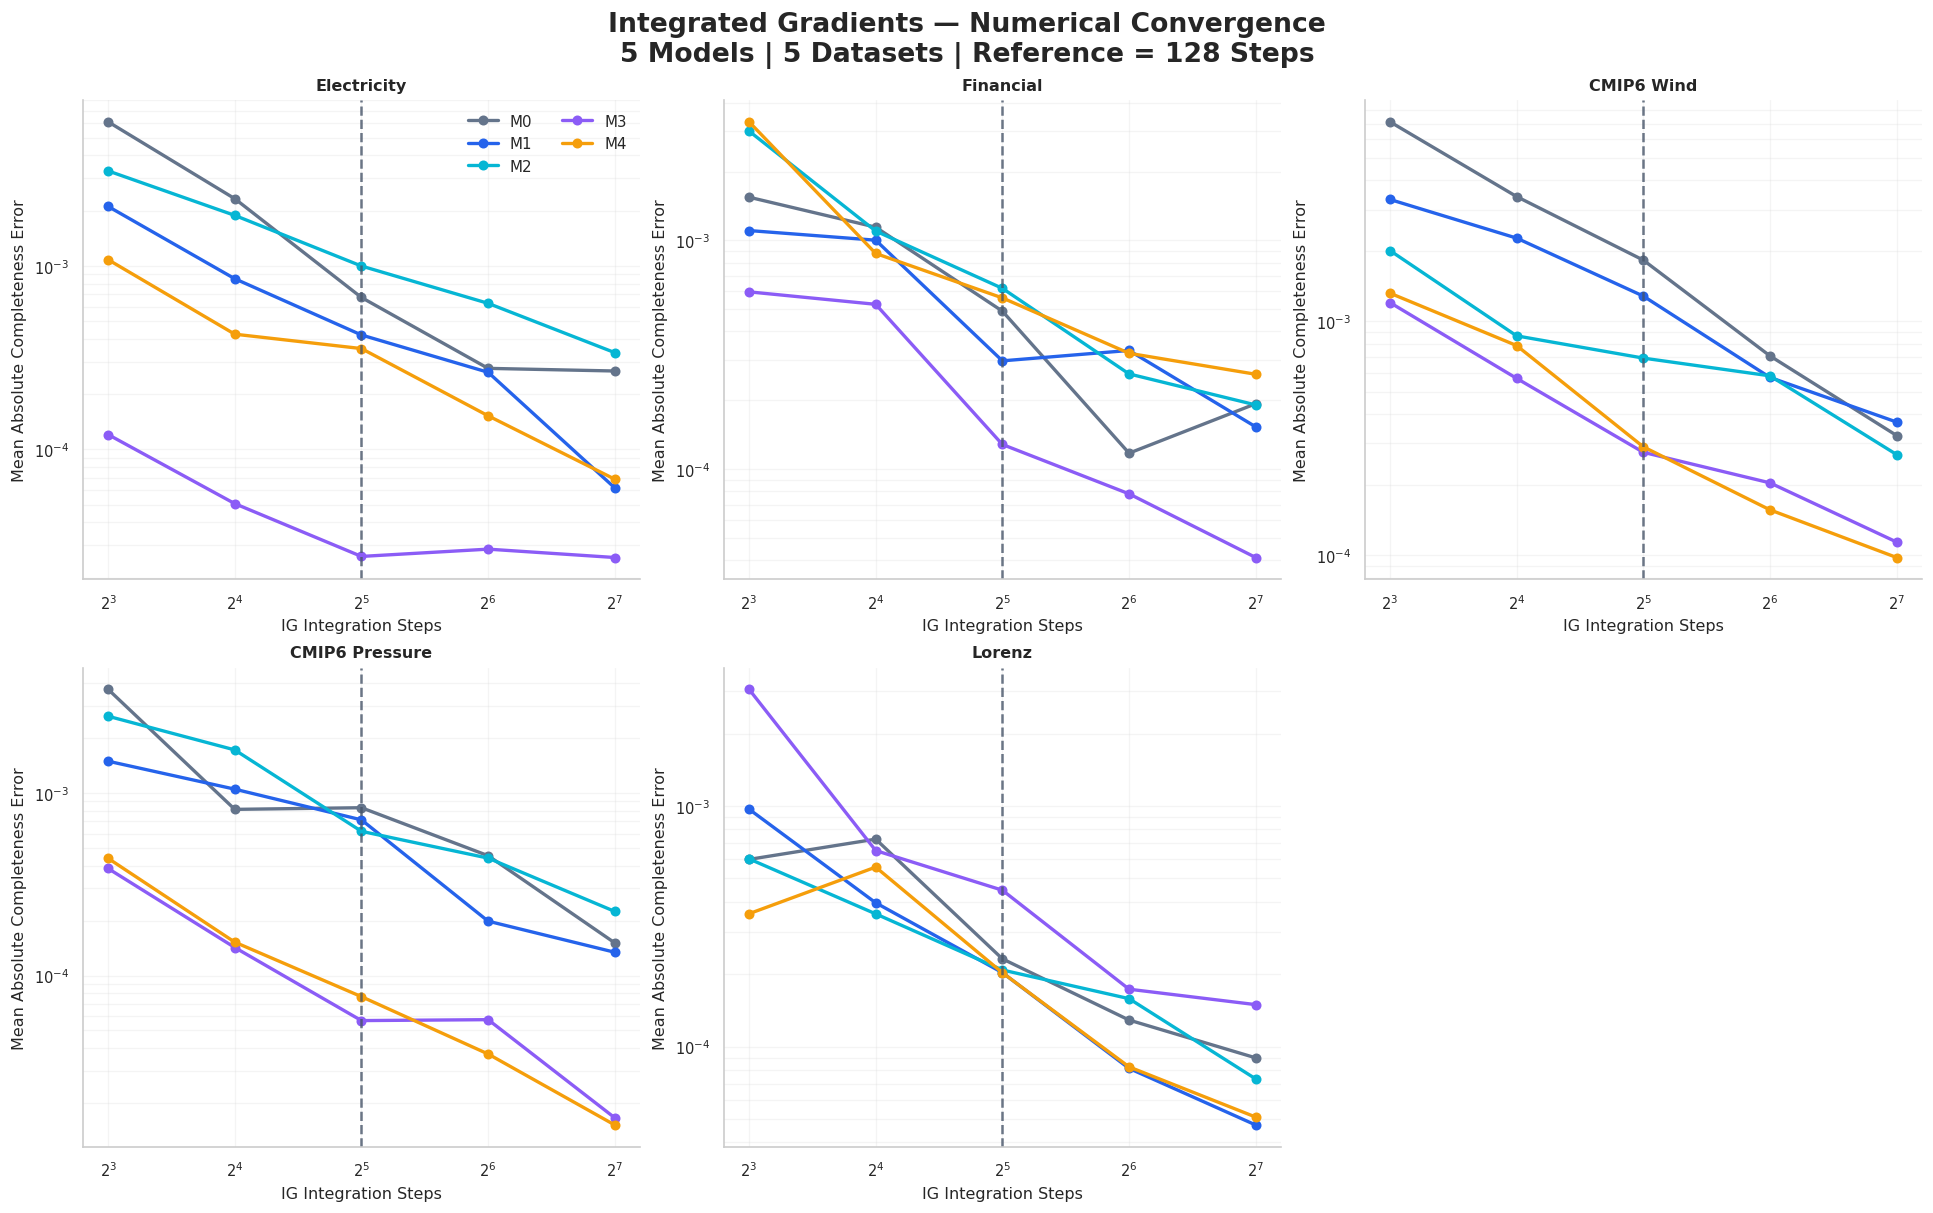

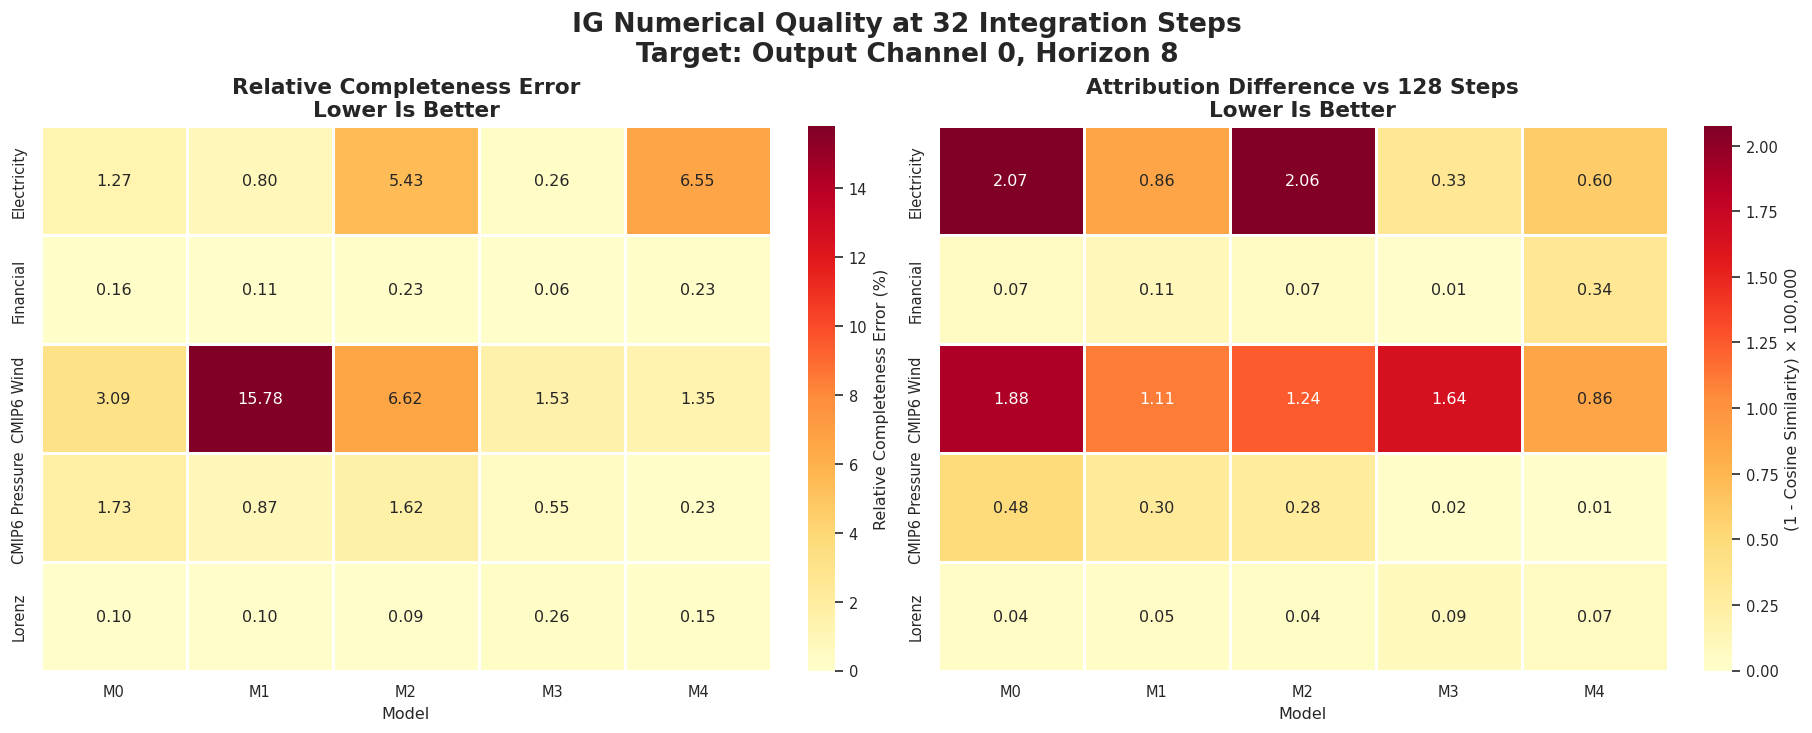

RELATIVE COMPLETENESS ERROR AT 32 STEPS (%)


model,M0,M1,M2,M3,M4
dataset_name,,,,,
Electricity,1.275%,0.803%,5.429%,0.260%,6.551%
Financial,0.161%,0.111%,0.229%,0.063%,0.228%
CMIP6 Wind,3.090%,15.783%,6.624%,1.529%,1.353%
CMIP6 Pressure,1.729%,0.873%,1.623%,0.554%,0.228%
Lorenz,0.099%,0.097%,0.085%,0.264%,0.147%



COSINE SIMILARITY — 32 VS 128 STEPS


model,M0,M1,M2,M3,M4
dataset_name,,,,,
Electricity,0.999979,0.999991,0.999979,0.999997,0.999994
Financial,0.999999,0.999999,0.999999,1.000000,0.999997
CMIP6 Wind,0.999981,0.999989,0.999988,0.999984,0.999991
CMIP6 Pressure,0.999995,0.999997,0.999997,1.000000,1.000000
Lorenz,1.000000,1.000000,1.000000,0.999999,0.999999



ABSOLUTE COMPLETENESS ERROR — 32 VS 128


,dataset_name,model,mean_abs_completeness_error,error_at_128,error_32_to_128_ratio
2,Electricity,M0,0.00067314,0.00026758,2.52x
7,Electricity,M1,0.00042050,0.00006171,6.81x
12,Electricity,M2,0.00099895,0.00033692,2.96x
17,Electricity,M3,0.00002612,0.00002576,1.01x
22,Electricity,M4,0.00035457,0.00006882,5.15x
27,Financial,M0,0.00049084,0.00019331,2.54x
32,Financial,M1,0.00029768,0.00015320,1.94x
37,Financial,M2,0.00061759,0.00019103,3.23x
42,Financial,M3,0.00012831,0.00004112,3.12x
47,Financial,M4,0.00056085,0.00026011,2.16x



NUMERICAL QUALITY SUMMARY
Mean cosine (32 vs 128): 0.999994
Mean relative completeness error (32): 1.968%
Cases where 128 steps has lower absolute error: 25 /25

[PASS] IG convergence and completeness validated


In [6]:
IG_STEPS = [8, 16, 32, 64, 128]
REFERENCE_STEPS = 128
USED_STEPS = 32

convergence_frames = []

for dataset, dataset_key in DATASET_MAP.items():
    frame = validation_tables["ig_convergence"][
        dataset
    ].copy()

    required_columns = {
        "dataset",
        "model",
        "lookback",
        "horizon",
        "samples",
        "ig_steps",
        "reference_steps",
        "mean_abs_completeness_error",
        "mean_relative_completeness_error",
        "cosine_with_reference"
    }

    assert required_columns.issubset(frame.columns)

    assert set(frame["model"]) == set(MODELS)
    assert set(frame["ig_steps"]) == set(IG_STEPS)
    assert (frame["reference_steps"] == REFERENCE_STEPS).all()
    assert (frame["lookback"] == LOOKBACK).all()
    assert (frame["horizon"] == HORIZON).all()
    assert (frame["samples"] == 8).all()
    assert len(frame) == len(MODELS) * len(IG_STEPS)

    assert not frame.duplicated(
        ["model", "ig_steps"]
    ).any()

    frame["dataset_name"] = dataset

    convergence_frames.append(frame)

convergence_df = pd.concat(
    convergence_frames,
    ignore_index=True
)

assert len(convergence_df) == 125

metric_columns = [
    "mean_abs_completeness_error",
    "mean_relative_completeness_error",
    "cosine_with_reference"
]

assert np.isfinite(
    convergence_df[metric_columns].to_numpy()
).all()

assert (
    convergence_df["mean_abs_completeness_error"] >= 0
).all()

assert (
    convergence_df["mean_relative_completeness_error"] >= 0
).all()

assert convergence_df[
    "cosine_with_reference"
].between(-1.00001, 1.00001).all()

used_df = convergence_df[
    convergence_df["ig_steps"] == USED_STEPS
].copy()

reference_df = convergence_df[
    convergence_df["ig_steps"] == REFERENCE_STEPS
].copy()

assert len(used_df) == 25
assert len(reference_df) == 25

recorded_ig = (
    xai_summary
    .set_index(["dataset", "model"])[
        "ig_mean_abs_completeness_error"
    ]
)

for row in used_df.itertuples():
    recorded = recorded_ig.loc[
        (row.dataset_name, row.model)
    ]

    np.testing.assert_allclose(
        row.mean_abs_completeness_error,
        recorded,
        rtol=1e-5,
        atol=1e-8
    )

print("[PASS] 32-step IG results match XAI summary")

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10),
    constrained_layout=True
)

axes = axes.flatten()

for i, dataset in enumerate(DATASETS):
    ax = axes[i]

    subset = convergence_df[
        convergence_df["dataset_name"] == dataset
    ]

    for model in MODELS:
        data = subset[
            subset["model"] == model
        ].sort_values("ig_steps")

        ax.plot(
            data["ig_steps"],
            data["mean_abs_completeness_error"].clip(
                lower=1e-12
            ),
            marker="o",
            linewidth=2,
            markersize=5,
            color=MODEL_COLORS[model],
            label=model
        )

    ax.axvline(
        USED_STEPS,
        color="#475569",
        linestyle="--",
        linewidth=1.5,
        alpha=0.8
    )

    ax.set_title(
        dataset,
        fontweight="bold"
    )

    ax.set_xlabel("IG Integration Steps")
    ax.set_ylabel("Mean Absolute Completeness Error")
    ax.set_xticks(IG_STEPS)
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.grid(alpha=0.2, which="both")

axes[0].legend(
    frameon=False,
    ncol=2,
    fontsize=9
)

axes[-1].axis("off")

fig.suptitle(
    "Integrated Gradients — Numerical Convergence\n"
    "5 Models | 5 Datasets | Reference = 128 Steps",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig09_ig_convergence.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig09_ig_convergence.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

used_df["relative_error_pct"] = (
    100 * used_df["mean_relative_completeness_error"]
)

used_df["cosine_distance_1e5"] = (
    1 - used_df["cosine_with_reference"]
) * 1e5

relative_matrix = used_df.pivot(
    index="dataset_name",
    columns="model",
    values="relative_error_pct"
).reindex(
    index=DATASETS,
    columns=MODELS
)

cosine_matrix = used_df.pivot(
    index="dataset_name",
    columns="model",
    values="cosine_distance_1e5"
).reindex(
    index=DATASETS,
    columns=MODELS
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6),
    constrained_layout=True
)

sns.heatmap(
    relative_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={
        "label": "Relative Completeness Error (%)"
    },
    ax=axes[0]
)

sns.heatmap(
    cosine_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={
        "label": "(1 - Cosine Similarity) × 100,000"
    },
    ax=axes[1]
)

axes[0].set_title(
    "Relative Completeness Error\nLower Is Better",
    fontsize=13,
    fontweight="bold"
)

axes[1].set_title(
    "Attribution Difference vs 128 Steps\nLower Is Better",
    fontsize=13,
    fontweight="bold"
)

for ax in axes:
    ax.set_xlabel("Model")
    ax.set_ylabel("")

fig.suptitle(
    "IG Numerical Quality at 32 Integration Steps\n"
    "Target: Output Channel 0, Horizon 8",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig10_ig_quality_32steps.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig10_ig_quality_32steps.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

reference_errors = reference_df.set_index(
    ["dataset_name", "model"]
)["mean_abs_completeness_error"]

used_df["error_at_128"] = [
    reference_errors.loc[
        (dataset, model)
    ]
    for dataset, model in zip(
        used_df["dataset_name"],
        used_df["model"]
    )
]

used_df["error_32_to_128_ratio"] = (
    used_df["mean_abs_completeness_error"]
    / used_df["error_at_128"].clip(lower=1e-15)
)

print("RELATIVE COMPLETENESS ERROR AT 32 STEPS (%)")

display(
    relative_matrix.style.format("{:.3f}%")
)

print("\nCOSINE SIMILARITY — 32 VS 128 STEPS")

display(
    used_df.pivot(
        index="dataset_name",
        columns="model",
        values="cosine_with_reference"
    ).reindex(
        index=DATASETS,
        columns=MODELS
    ).style.format("{:.6f}")
)

print("\nABSOLUTE COMPLETENESS ERROR — 32 VS 128")

display(
    used_df[
        [
            "dataset_name",
            "model",
            "mean_abs_completeness_error",
            "error_at_128",
            "error_32_to_128_ratio"
        ]
    ].style.format({
        "mean_abs_completeness_error": "{:.8f}",
        "error_at_128": "{:.8f}",
        "error_32_to_128_ratio": "{:.2f}x"
    })
)

print("\nNUMERICAL QUALITY SUMMARY")

print(
    "Mean cosine (32 vs 128):",
    f"{used_df['cosine_with_reference'].mean():.6f}"
)

print(
    "Mean relative completeness error (32):",
    f"{used_df['relative_error_pct'].mean():.3f}%"
)

print(
    "Cases where 128 steps has lower absolute error:",
    int(
        (
            used_df["error_at_128"]
            < used_df["mean_abs_completeness_error"]
        ).sum()
    ),
    "/25"
)

convergence_df.to_csv(
    FIGURES_DIR / "ig_convergence_all_steps.csv",
    index=False
)

used_df.to_csv(
    FIGURES_DIR / "ig_numerical_quality_32steps.csv",
    index=False
)

print("\n[PASS] IG convergence and completeness validated")


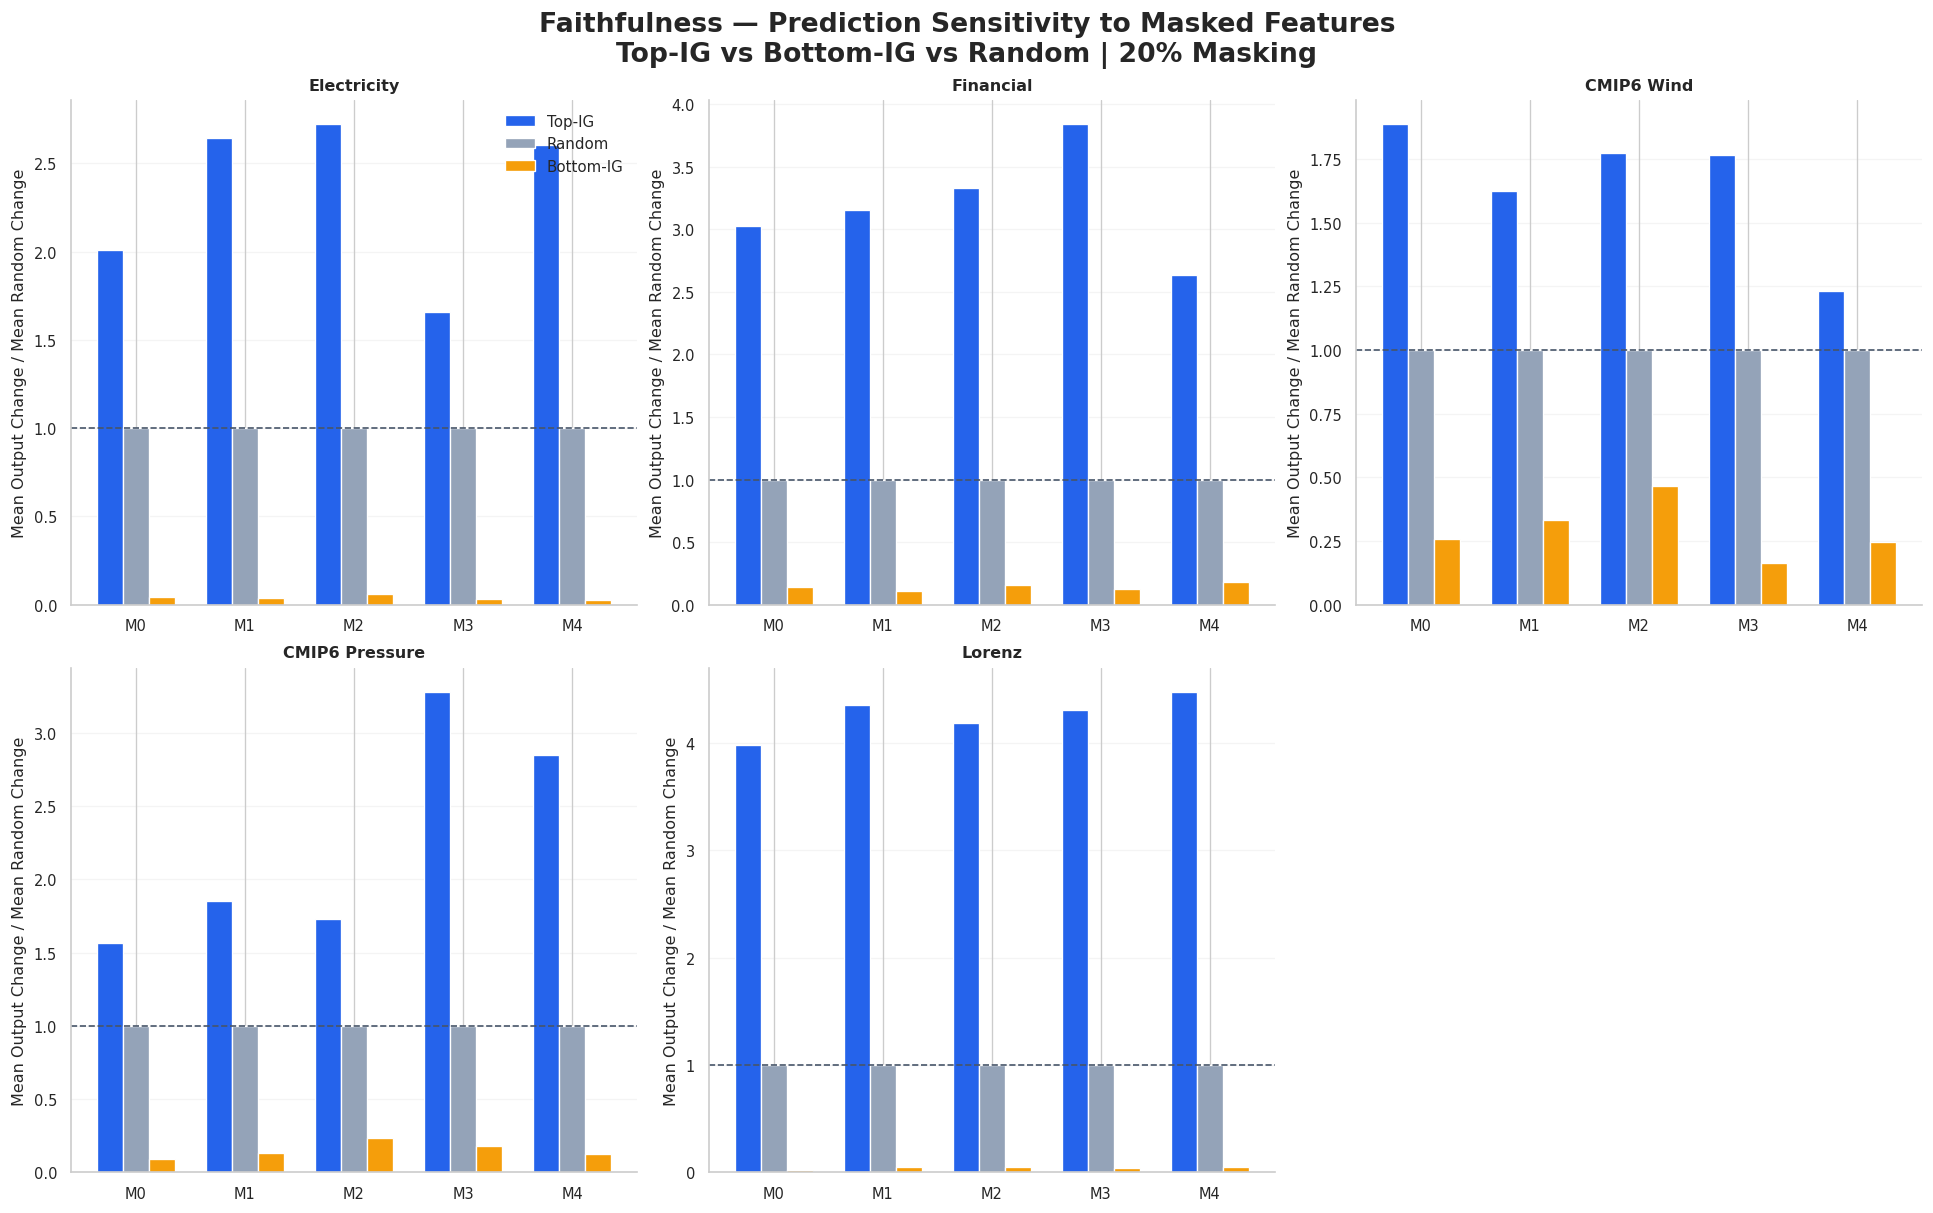

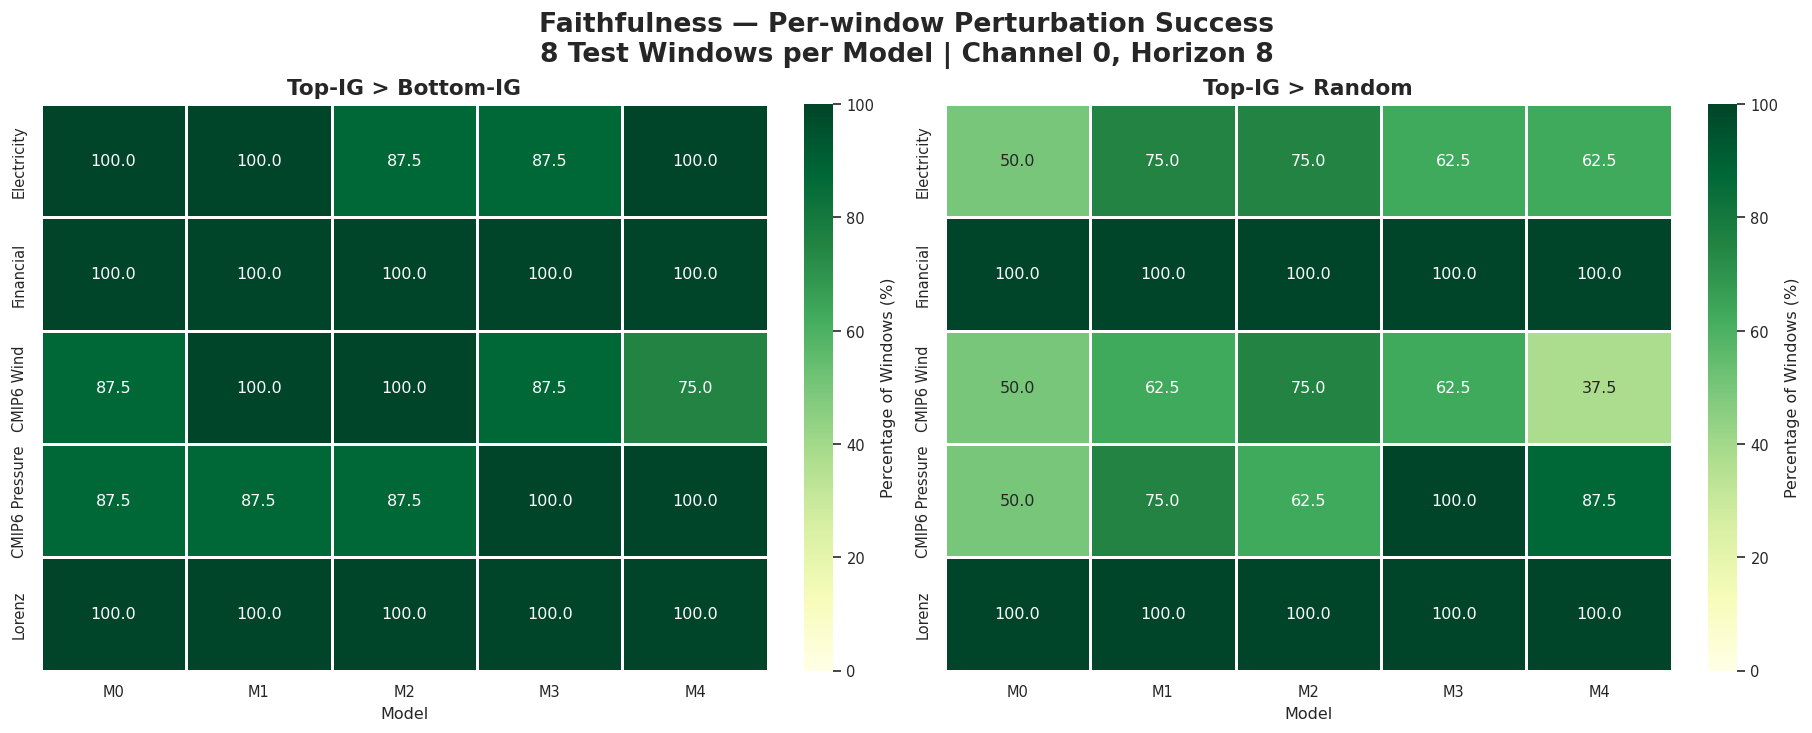

FAITHFULNESS — MEAN PERTURBATION RATIOS


model,M0,M1,M2,M3,M4
dataset_name,,,,,
Electricity,2.01x,2.64x,2.72x,1.66x,2.60x
Financial,3.03x,3.15x,3.33x,3.84x,2.63x
CMIP6 Wind,1.89x,1.62x,1.78x,1.76x,1.23x
CMIP6 Pressure,1.57x,1.85x,1.73x,3.28x,2.85x
Lorenz,3.98x,4.36x,4.19x,4.31x,4.48x



TOP-IG BEATS RANDOM — NUMBER OF WINDOWS (OUT OF 8)


model,M0,M1,M2,M3,M4
dataset_name,,,,,
Electricity,4,6,6,5,5
Financial,8,8,8,8,8
CMIP6 Wind,4,5,6,5,3
CMIP6 Pressure,4,6,5,8,7
Lorenz,8,8,8,8,8



TOP-IG BEATS BOTTOM-IG — NUMBER OF WINDOWS (OUT OF 8)


model,M0,M1,M2,M3,M4
dataset_name,,,,,
Electricity,8,8,7,7,8
Financial,8,8,8,8,8
CMIP6 Wind,7,8,8,7,6
CMIP6 Pressure,7,7,7,8,8
Lorenz,8,8,8,8,8



MEAN TOP-IG MINUS RANDOM


model,M0,M1,M2,M3,M4
dataset_name,,,,,
Electricity,+0.037843,+0.056118,+0.056312,+0.003985,+0.028478
Financial,+0.179970,+0.182953,+0.170348,+0.140501,+0.075801
CMIP6 Wind,+0.066484,+0.047015,+0.023691,+0.014904,+0.006562
CMIP6 Pressure,+0.045403,+0.060960,+0.038095,+0.050036,+0.040614
Lorenz,+0.152314,+0.167882,+0.159866,+0.154596,+0.146683



[PASS] Faithfulness validation completed


In [7]:
faithfulness_frames = []

for dataset, dataset_key in DATASET_MAP.items():
    frame = validation_tables["faithfulness"][
        dataset
    ].copy()

    required_columns = {
        "dataset", "model", "sample_index",
        "lookback", "horizon",
        "target_channel", "target_step",
        "masked_fraction", "units_masked",
        "total_units", "top_delta",
        "bottom_delta", "random_delta",
        "top_minus_bottom", "top_minus_random"
    }

    assert required_columns.issubset(frame.columns)
    assert len(frame) == 8 * len(MODELS)
    assert set(frame["model"]) == set(MODELS)
    assert set(frame["dataset"]) == {dataset_key}

    assert (frame["lookback"] == LOOKBACK).all()
    assert (frame["horizon"] == HORIZON).all()
    assert (frame["target_channel"] == 0).all()
    assert (frame["target_step"] == 7).all()

    np.testing.assert_allclose(
        frame["masked_fraction"],
        0.2,
        atol=1e-8
    )

    expected_units = (
        (LOOKBACK // 10)
        * xai_data[dataset]["channels"]
    )

    assert (frame["total_units"] == expected_units).all()
    assert (
        frame["units_masked"]
        == int(np.ceil(0.2 * expected_units))
    ).all()

    expected_indices = set(
        xai_data[dataset]["indices"].astype(int)
    )

    for model in MODELS:
        subset = frame[frame["model"] == model]

        assert set(subset["sample_index"]) == expected_indices
        assert len(subset) == 8

    np.testing.assert_allclose(
        frame["top_delta"] - frame["bottom_delta"],
        frame["top_minus_bottom"],
        rtol=1e-5,
        atol=1e-6
    )

    np.testing.assert_allclose(
        frame["top_delta"] - frame["random_delta"],
        frame["top_minus_random"],
        rtol=1e-5,
        atol=1e-6
    )

    frame["dataset_name"] = dataset

    frame["top_beats_bottom"] = (
        frame["top_delta"] > frame["bottom_delta"]
    )

    frame["top_beats_random"] = (
        frame["top_delta"] > frame["random_delta"]
    )

    faithfulness_frames.append(frame)

faithfulness_df = pd.concat(
    faithfulness_frames,
    ignore_index=True
)

assert len(faithfulness_df) == 200

faithfulness_summary = (
    faithfulness_df
    .groupby(["dataset_name", "model"], as_index=False)
    .agg(
        n_samples=("sample_index", "size"),
        mean_top=("top_delta", "mean"),
        mean_bottom=("bottom_delta", "mean"),
        mean_random=("random_delta", "mean"),
        mean_top_minus_bottom=("top_minus_bottom", "mean"),
        mean_top_minus_random=("top_minus_random", "mean"),
        top_beats_bottom_count=("top_beats_bottom", "sum"),
        top_beats_random_count=("top_beats_random", "sum")
    )
)

assert len(faithfulness_summary) == 25
assert (faithfulness_summary["n_samples"] == 8).all()

faithfulness_summary["top_vs_random_ratio"] = (
    faithfulness_summary["mean_top"]
    / faithfulness_summary["mean_random"].replace(0, np.nan)
)

faithfulness_summary["bottom_vs_random_ratio"] = (
    faithfulness_summary["mean_bottom"]
    / faithfulness_summary["mean_random"].replace(0, np.nan)
)

faithfulness_summary["top_beats_bottom_pct"] = (
    100 * faithfulness_summary["top_beats_bottom_count"] / 8
)

faithfulness_summary["top_beats_random_pct"] = (
    100 * faithfulness_summary["top_beats_random_count"] / 8
)

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10),
    constrained_layout=True
)

axes = axes.flatten()

x = np.arange(len(MODELS))
width = 0.24

for i, dataset in enumerate(DATASETS):
    ax = axes[i]

    subset = (
        faithfulness_summary[
            faithfulness_summary["dataset_name"] == dataset
        ]
        .set_index("model")
        .reindex(MODELS)
    )

    ax.bar(
        x - width,
        subset["top_vs_random_ratio"],
        width,
        color="#2563EB",
        label="Top-IG"
    )

    ax.bar(
        x,
        np.ones(len(MODELS)),
        width,
        color="#94A3B8",
        label="Random"
    )

    ax.bar(
        x + width,
        subset["bottom_vs_random_ratio"],
        width,
        color="#F59E0B",
        label="Bottom-IG"
    )

    ax.axhline(
        1,
        color="#475569",
        linestyle="--",
        linewidth=1
    )

    ax.set_xticks(x)
    ax.set_xticklabels(MODELS)
    ax.set_title(dataset, fontweight="bold")
    ax.set_ylabel("Mean Output Change / Mean Random Change")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

    if i == 0:
        ax.legend(frameon=False, fontsize=9)

axes[-1].axis("off")

fig.suptitle(
    "Faithfulness — Prediction Sensitivity to Masked Features\n"
    "Top-IG vs Bottom-IG vs Random | 20% Masking",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig11_faithfulness_perturbation.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig11_faithfulness_perturbation.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6),
    constrained_layout=True
)

comparison_metrics = [
    (
        "top_beats_bottom_pct",
        "Top-IG > Bottom-IG"
    ),
    (
        "top_beats_random_pct",
        "Top-IG > Random"
    )
]

for ax, (metric, title) in zip(
    axes,
    comparison_metrics
):
    matrix = faithfulness_summary.pivot(
        index="dataset_name",
        columns="model",
        values=metric
    ).reindex(
        index=DATASETS,
        columns=MODELS
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt=".1f",
        cmap="YlGn",
        vmin=0,
        vmax=100,
        linewidths=0.8,
        linecolor="white",
        cbar=True,
        cbar_kws={
            "label": "Percentage of Windows (%)"
        },
        ax=ax
    )

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Model")
    ax.set_ylabel("")

fig.suptitle(
    "Faithfulness — Per-window Perturbation Success\n"
    "8 Test Windows per Model | Channel 0, Horizon 8",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig12_faithfulness_winrate.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig12_faithfulness_winrate.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("FAITHFULNESS — MEAN PERTURBATION RATIOS")

display(
    faithfulness_summary.pivot(
        index="dataset_name",
        columns="model",
        values="top_vs_random_ratio"
    ).reindex(
        index=DATASETS,
        columns=MODELS
    ).style.format("{:.2f}x")
)

print("\nTOP-IG BEATS RANDOM — NUMBER OF WINDOWS (OUT OF 8)")

display(
    faithfulness_summary.pivot(
        index="dataset_name",
        columns="model",
        values="top_beats_random_count"
    ).reindex(
        index=DATASETS,
        columns=MODELS
    )
)

print("\nTOP-IG BEATS BOTTOM-IG — NUMBER OF WINDOWS (OUT OF 8)")

display(
    faithfulness_summary.pivot(
        index="dataset_name",
        columns="model",
        values="top_beats_bottom_count"
    ).reindex(
        index=DATASETS,
        columns=MODELS
    )
)

print("\nMEAN TOP-IG MINUS RANDOM")

display(
    faithfulness_summary.pivot(
        index="dataset_name",
        columns="model",
        values="mean_top_minus_random"
    ).reindex(
        index=DATASETS,
        columns=MODELS
    ).style.format("{:+.6f}")
)

faithfulness_df.to_csv(
    FIGURES_DIR / "faithfulness_window_results.csv",
    index=False
)

faithfulness_summary.to_csv(
    FIGURES_DIR / "faithfulness_summary.csv",
    index=False
)

print("\n[PASS] Faithfulness validation completed")


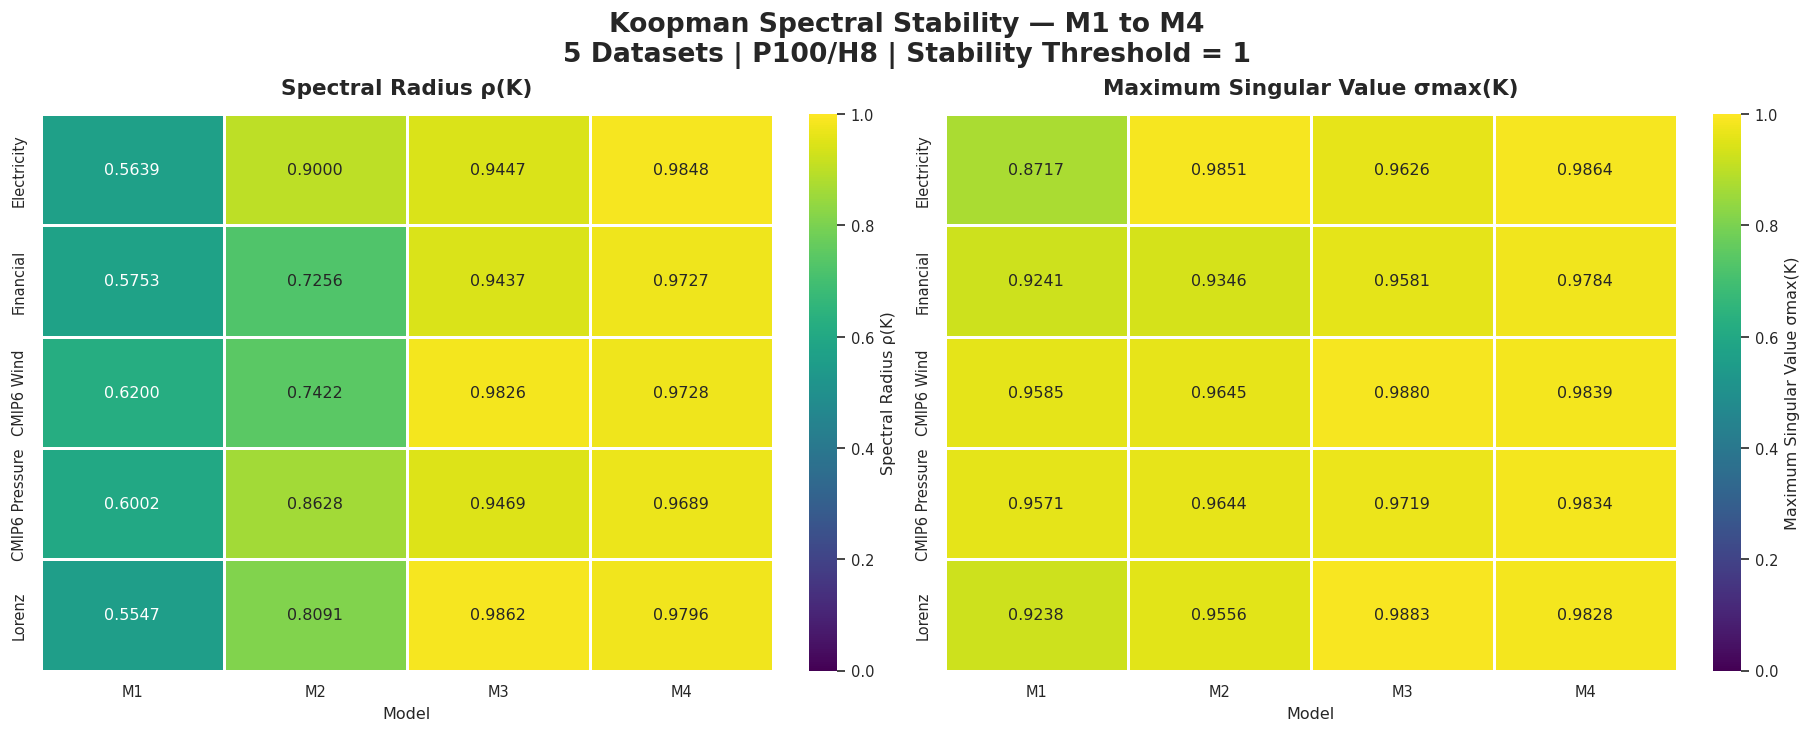

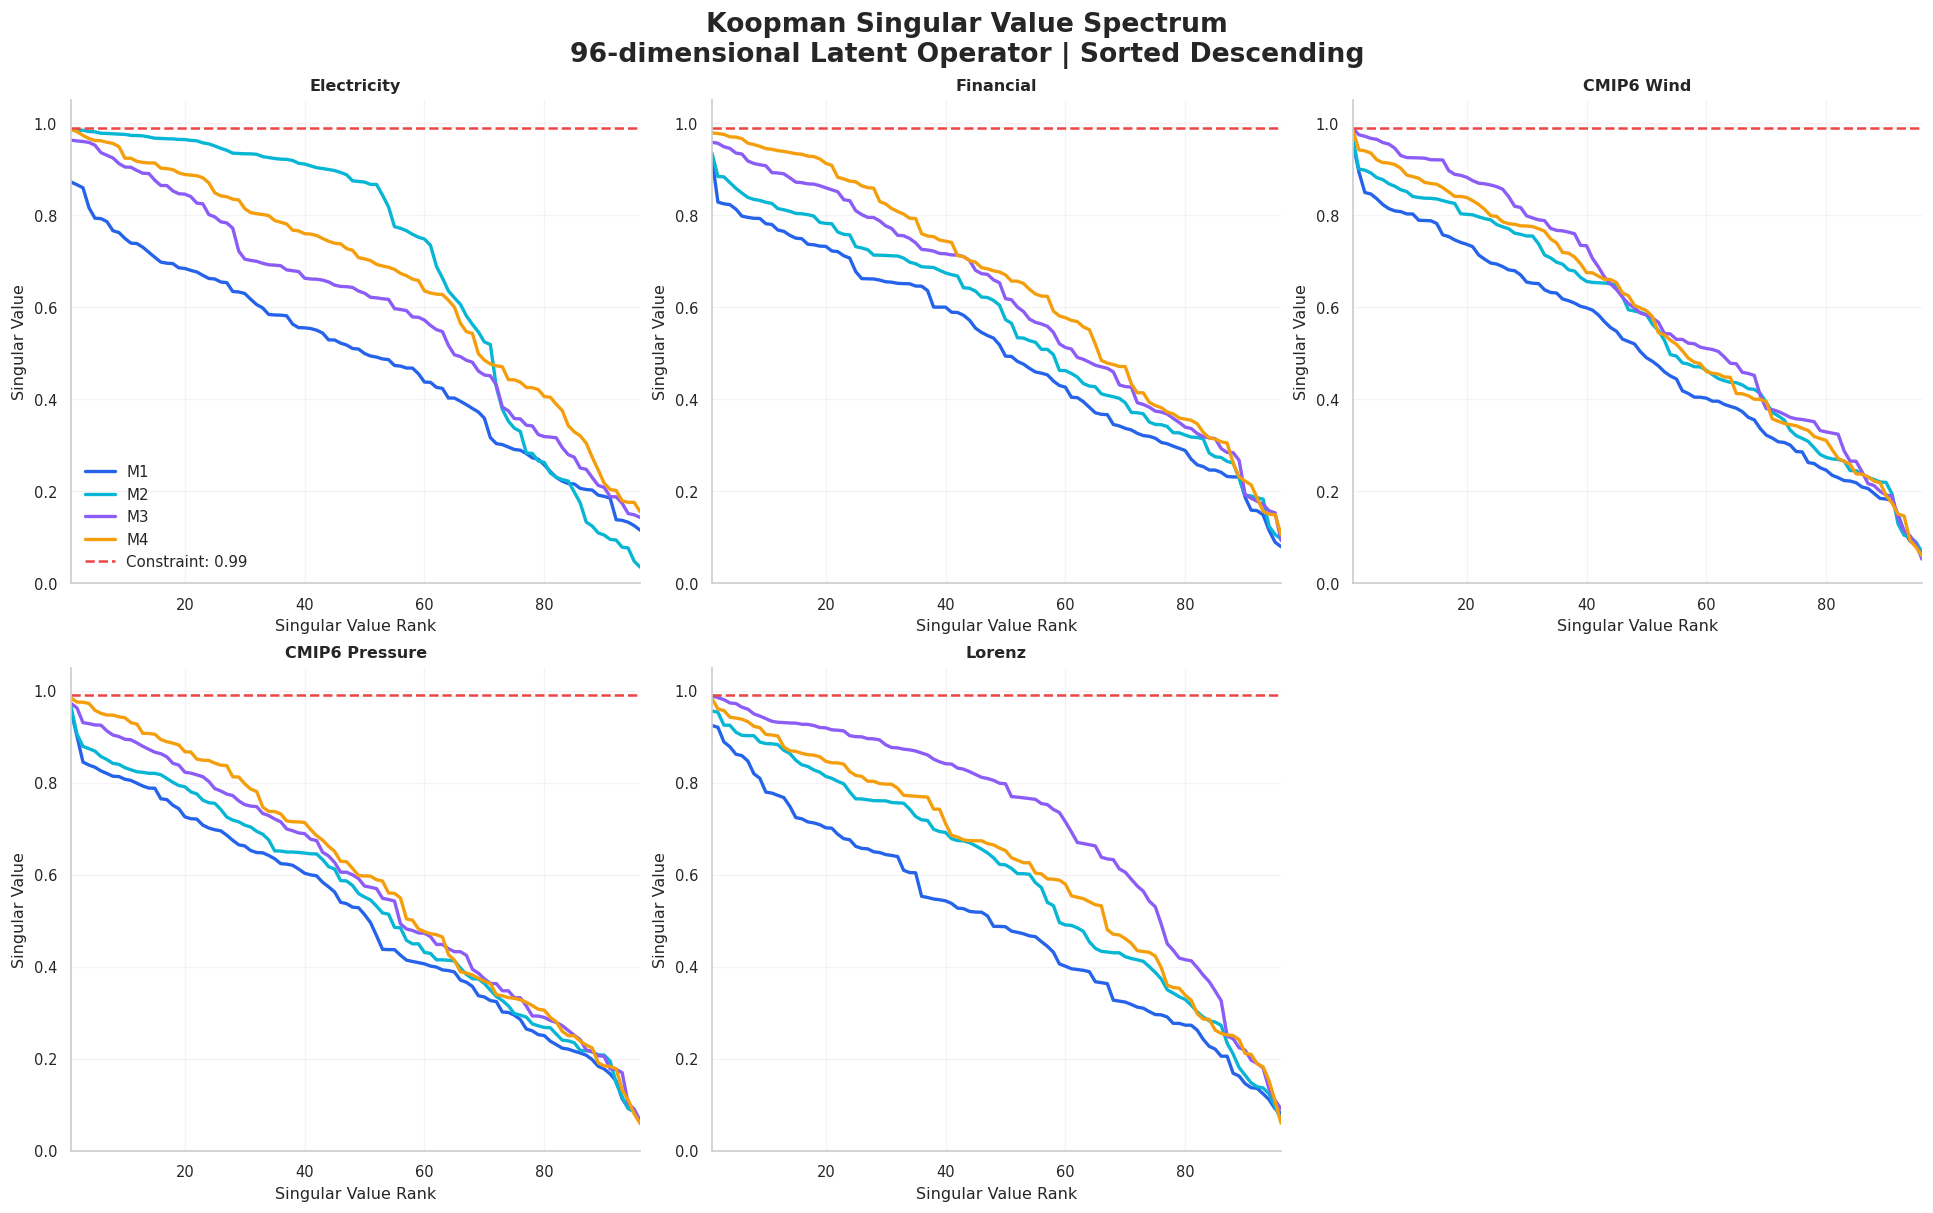

SPECTRAL RADIUS


model,M1,M2,M3,M4
dataset,,,,
Electricity,0.5639,0.9000,0.9447,0.9848
Financial,0.5753,0.7256,0.9437,0.9727
CMIP6 Wind,0.6200,0.7422,0.9826,0.9728
CMIP6 Pressure,0.6002,0.8628,0.9469,0.9689
Lorenz,0.5547,0.8091,0.9862,0.9796



MAXIMUM SINGULAR VALUE


model,M1,M2,M3,M4
dataset,,,,
Electricity,0.8717,0.9851,0.9626,0.9864
Financial,0.9241,0.9346,0.9581,0.9784
CMIP6 Wind,0.9585,0.9645,0.9880,0.9839
CMIP6 Pressure,0.9571,0.9644,0.9719,0.9834
Lorenz,0.9238,0.9556,0.9883,0.9828



TEST MSE RELATIVE TO M1


model,M1,M2,M3,M4
dataset,,,,
Electricity,1.00x,1.07x,0.76x,0.89x
Financial,1.00x,0.93x,1.43x,3.88x
CMIP6 Wind,1.00x,0.86x,0.78x,0.80x
CMIP6 Pressure,1.00x,0.90x,0.75x,0.82x
Lorenz,1.00x,0.71x,6.62x,5.90x



SPECTRAL STABILITY CHECK


,dataset,model,spectral_radius,sigma_max,spectrally_stable,strictly_contracting
0,Electricity,M1,0.563898,0.871697,True,True
1,Electricity,M2,0.900005,0.985099,True,True
2,Electricity,M3,0.944664,0.962649,True,True
3,Electricity,M4,0.984810,0.986378,True,True
4,Financial,M1,0.575297,0.924081,True,True
5,Financial,M2,0.725599,0.934598,True,True
6,Financial,M3,0.943653,0.958127,True,True
7,Financial,M4,0.972675,0.978427,True,True
8,CMIP6 Wind,M1,0.620005,0.958475,True,True
9,CMIP6 Wind,M2,0.742214,0.964533,True,True



Stable operators: 20 /20
Strictly contracting operators: 20 /20

[PASS] Koopman spectral diagnostics completed


In [10]:

KOOPMAN_MODELS = ["M1", "M2", "M3", "M4"]
RHO_MAX = 0.99

spectral_records = []
singular_records = []

summary_lookup = xai_summary.set_index(
    ["dataset", "model"]
)

for dataset in DATASETS:
    for model in KOOPMAN_MODELS:
        entry = xai_data[dataset]["models"][model]
        arrays = entry["arrays"]

        assert "koop_singular_values" in arrays

        singular_values = np.asarray(
            arrays["koop_singular_values"],
            dtype=np.float64
        ).reshape(-1)

        assert len(singular_values) == 96
        assert np.isfinite(singular_values).all()
        assert (singular_values >= 0).all()

        sigma_max = float(
            singular_values.max()
        )

        spectral_radius = float(
            summary_lookup.loc[
                (dataset, model),
                "spectral_radius"
            ]
        )

        recorded_sigma = float(
            summary_lookup.loc[
                (dataset, model),
                "sigma_max"
            ]
        )

        np.testing.assert_allclose(
            sigma_max,
            recorded_sigma,
            rtol=1e-5,
            atol=1e-6
        )

        assert np.isfinite(spectral_radius)
        assert spectral_radius >= 0

        assert sigma_max < RHO_MAX + 1e-6
        assert spectral_radius <= sigma_max + 1e-5

        test_mse = float(
            summary_lookup.loc[
                (dataset, model),
                "full_test_mse_from_training"
            ]
        )

        sorted_singular = np.sort(
            singular_values
        )[::-1]

        spectral_records.append({
            "dataset": dataset,
            "model": model,
            "spectral_radius": spectral_radius,
            "sigma_max": sigma_max,
            "sigma_min": float(
                singular_values.min()
            ),
            "mean_singular_value": float(
                singular_values.mean()
            ),
            "spectral_margin": 1 - spectral_radius,
            "contraction_margin": RHO_MAX - sigma_max,
            "test_mse": test_mse,
            "spectrally_stable": spectral_radius < 1,
            "strictly_contracting": sigma_max < 1
        })

        for rank, value in enumerate(
            sorted_singular,
            start=1
        ):
            singular_records.append({
                "dataset": dataset,
                "model": model,
                "singular_rank": rank,
                "singular_value": float(value)
            })

spectral_df = pd.DataFrame(spectral_records)
singular_df = pd.DataFrame(singular_records)

assert len(spectral_df) == 20
assert len(singular_df) == 20 * 96

assert spectral_df["spectrally_stable"].all()
assert spectral_df["strictly_contracting"].all()

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6),
    constrained_layout=True
)

metrics = [
    (
        "spectral_radius",
        "Spectral Radius ρ(K)"
    ),
    (
        "sigma_max",
        "Maximum Singular Value σmax(K)"
    )
]

for ax, (metric, title) in zip(
    axes,
    metrics
):
    matrix = spectral_df.pivot(
        index="dataset",
        columns="model",
        values=metric
    ).reindex(
        index=DATASETS,
        columns=KOOPMAN_MODELS
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt=".4f",
        cmap="viridis",
        vmin=0,
        vmax=1,
        linewidths=0.8,
        linecolor="white",
        cbar=True,
        cbar_kws={
            "label": title
        },
        ax=ax
    )

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel("Model")
    ax.set_ylabel("")

fig.suptitle(
    "Koopman Spectral Stability — M1 to M4\n"
    "5 Datasets | P100/H8 | Stability Threshold = 1",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig13_koopman_spectral_stability.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig13_koopman_spectral_stability.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10),
    constrained_layout=True
)

axes = axes.flatten()

for i, dataset in enumerate(DATASETS):
    ax = axes[i]

    subset = singular_df[
        singular_df["dataset"] == dataset
    ]

    for model in KOOPMAN_MODELS:
        model_data = subset[
            subset["model"] == model
        ].sort_values("singular_rank")

        ax.plot(
            model_data["singular_rank"],
            model_data["singular_value"],
            color=MODEL_COLORS[model],
            linewidth=2,
            label=model
        )

    ax.axhline(
        RHO_MAX,
        color="#EF4444",
        linestyle="--",
        linewidth=1.5,
        label="Constraint: 0.99"
    )

    ax.set_title(
        dataset,
        fontweight="bold"
    )

    ax.set_xlabel("Singular Value Rank")
    ax.set_ylabel("Singular Value")
    ax.set_xlim(1, 96)
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.2)

    if i == 0:
        ax.legend(
            frameon=False,
            fontsize=9
        )

axes[-1].axis("off")

fig.suptitle(
    "Koopman Singular Value Spectrum\n"
    "96-dimensional Latent Operator | Sorted Descending",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig14_koopman_singular_spectrum.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig14_koopman_singular_spectrum.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

m1_reference = (
    spectral_df[
        spectral_df["model"] == "M1"
    ].set_index("dataset")["test_mse"]
)

spectral_df["mse_ratio_vs_m1"] = [
    mse / m1_reference.loc[dataset]
    for dataset, mse in zip(
        spectral_df["dataset"],
        spectral_df["test_mse"]
    )
]

print("SPECTRAL RADIUS")

display(
    spectral_df.pivot(
        index="dataset",
        columns="model",
        values="spectral_radius"
    ).reindex(
        index=DATASETS,
        columns=KOOPMAN_MODELS
    ).style.format("{:.4f}")
)

print("\nMAXIMUM SINGULAR VALUE")

display(
    spectral_df.pivot(
        index="dataset",
        columns="model",
        values="sigma_max"
    ).reindex(
        index=DATASETS,
        columns=KOOPMAN_MODELS
    ).style.format("{:.4f}")
)

print("\nTEST MSE RELATIVE TO M1")

display(
    spectral_df.pivot(
        index="dataset",
        columns="model",
        values="mse_ratio_vs_m1"
    ).reindex(
        index=DATASETS,
        columns=KOOPMAN_MODELS
    ).style.format("{:.2f}x")
)

print("\nSPECTRAL STABILITY CHECK")

display(
    spectral_df[
        [
            "dataset",
            "model",
            "spectral_radius",
            "sigma_max",
            "spectrally_stable",
            "strictly_contracting"
        ]
    ]
)

print(
    "\nStable operators:",
    int(spectral_df["spectrally_stable"].sum()),
    "/20"
)

print(
    "Strictly contracting operators:",
    int(spectral_df["strictly_contracting"].sum()),
    "/20"
)

spectral_df.to_csv(
    FIGURES_DIR / "koopman_spectral_diagnostics.csv",
    index=False
)

singular_df.to_csv(
    FIGURES_DIR / "koopman_singular_spectra.csv",
    index=False
)

print("\n[PASS] Koopman spectral diagnostics completed")

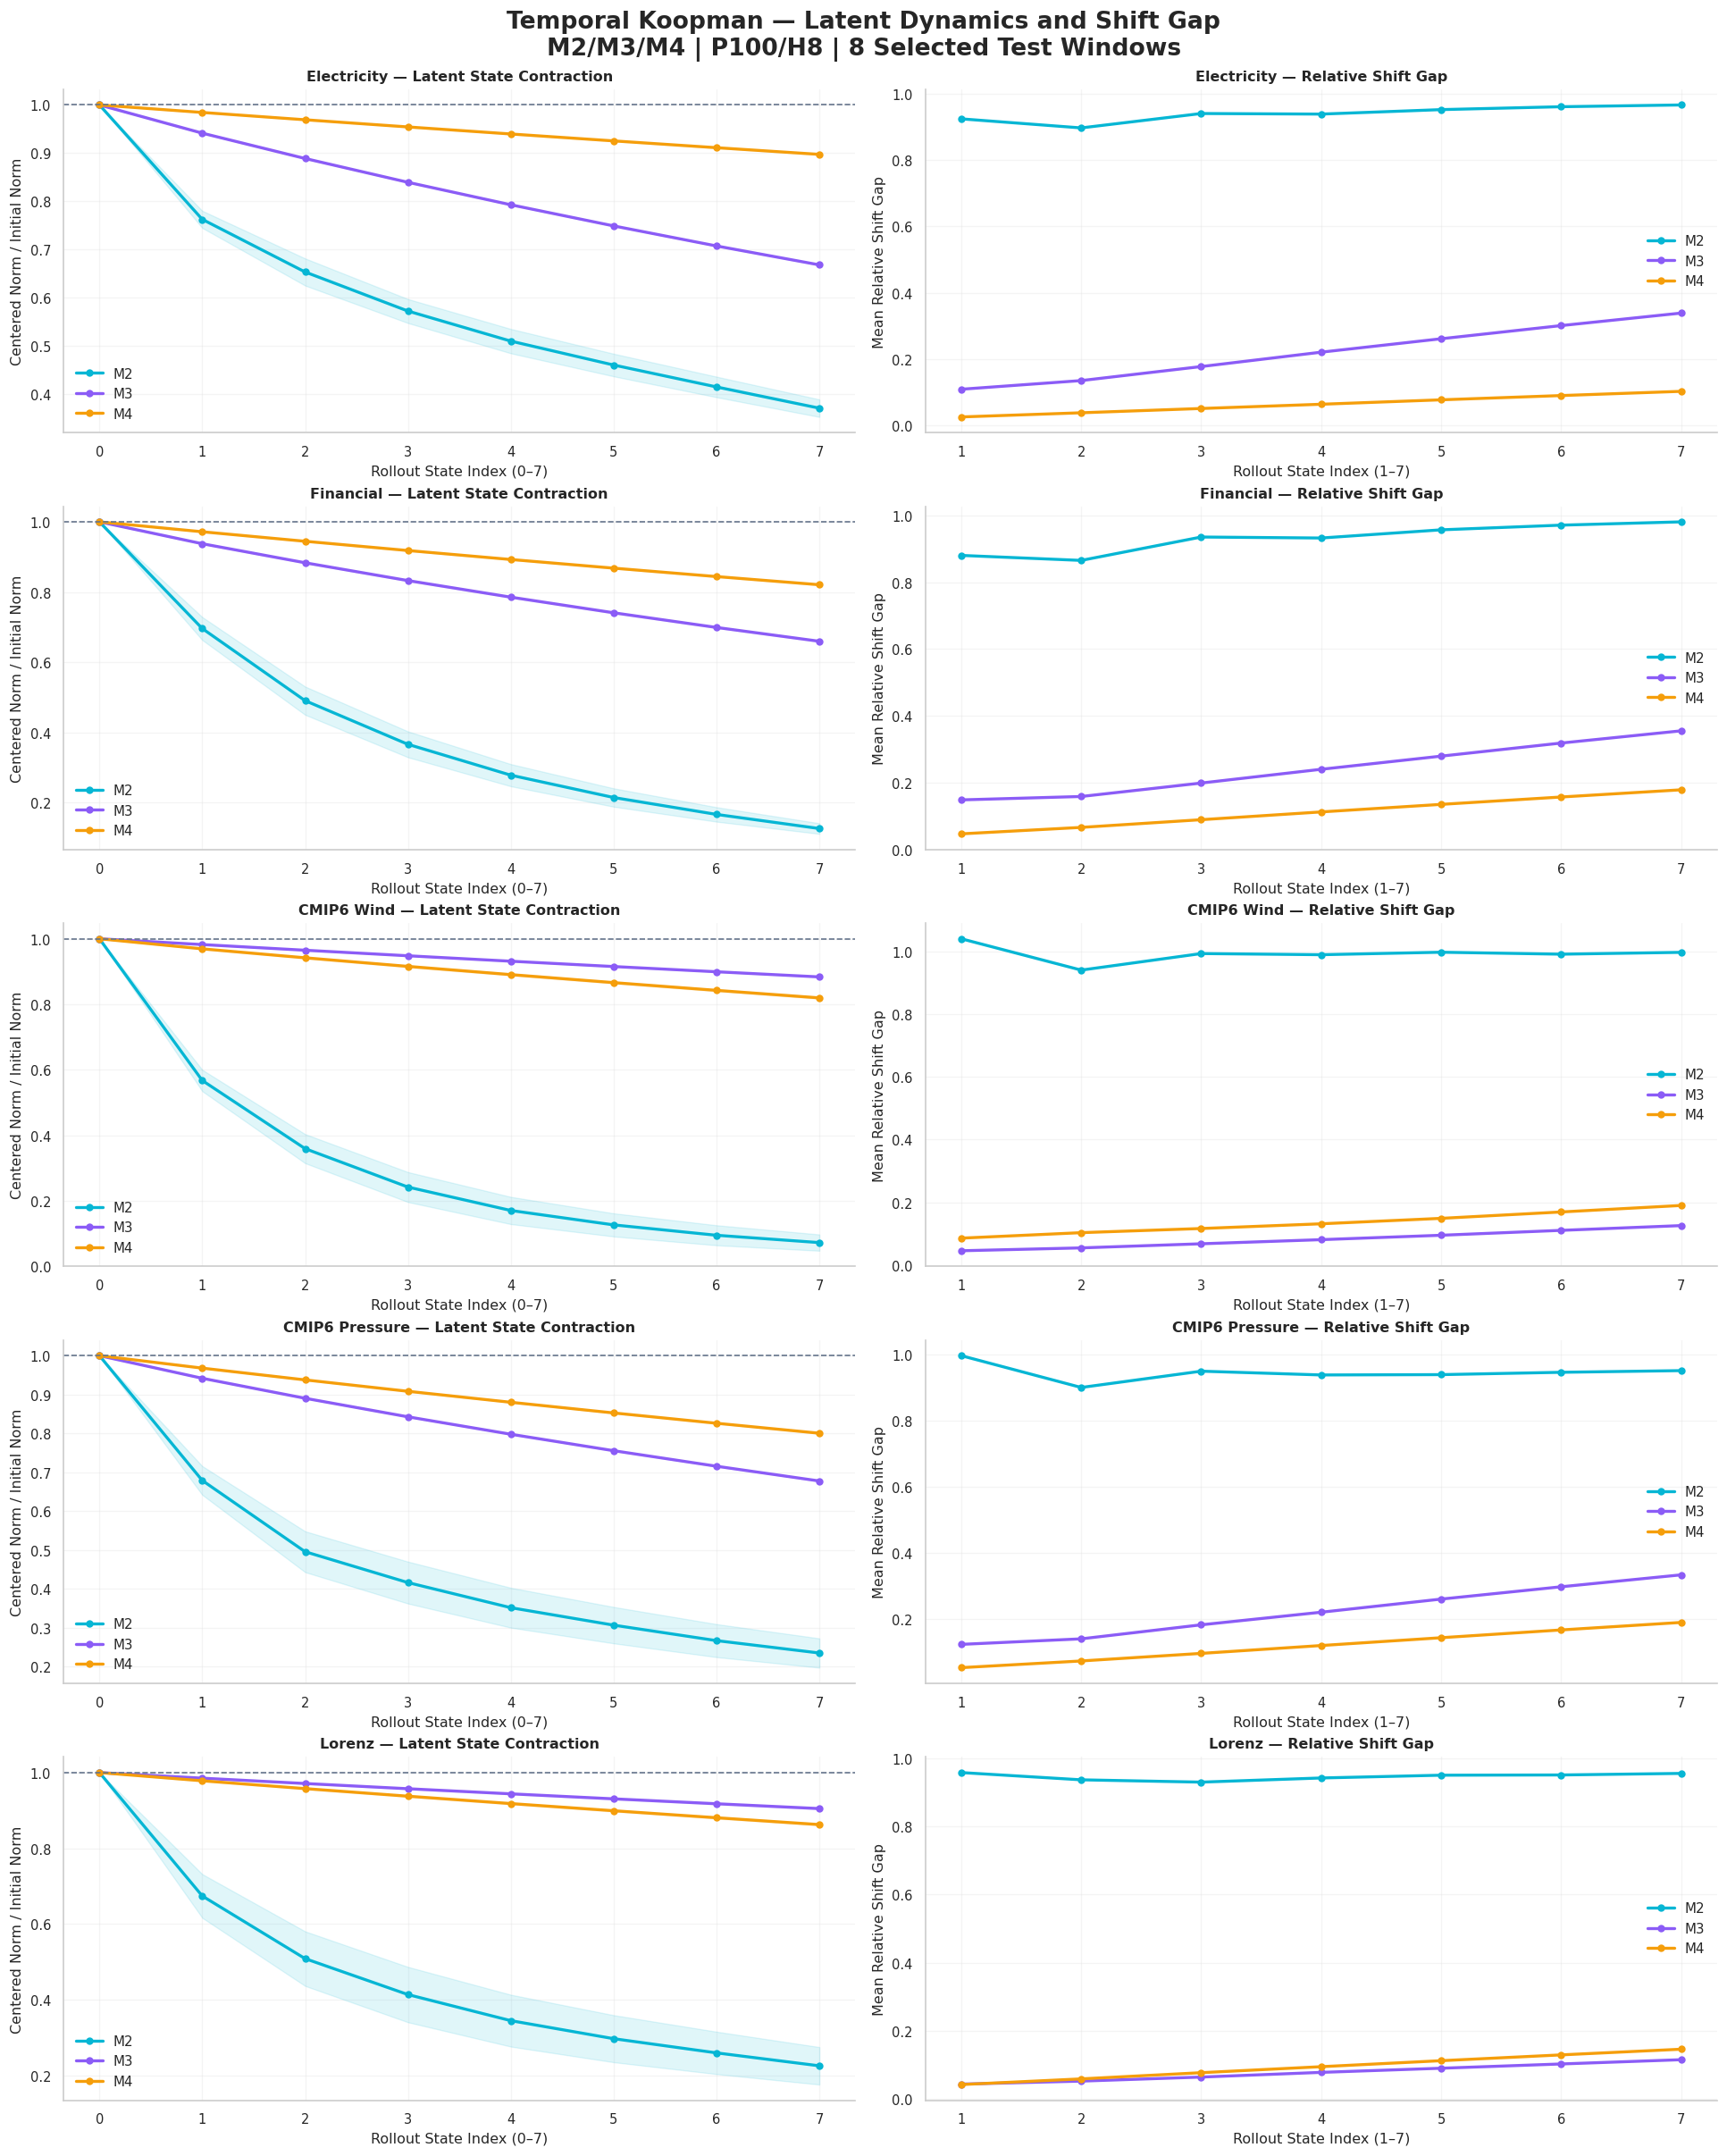

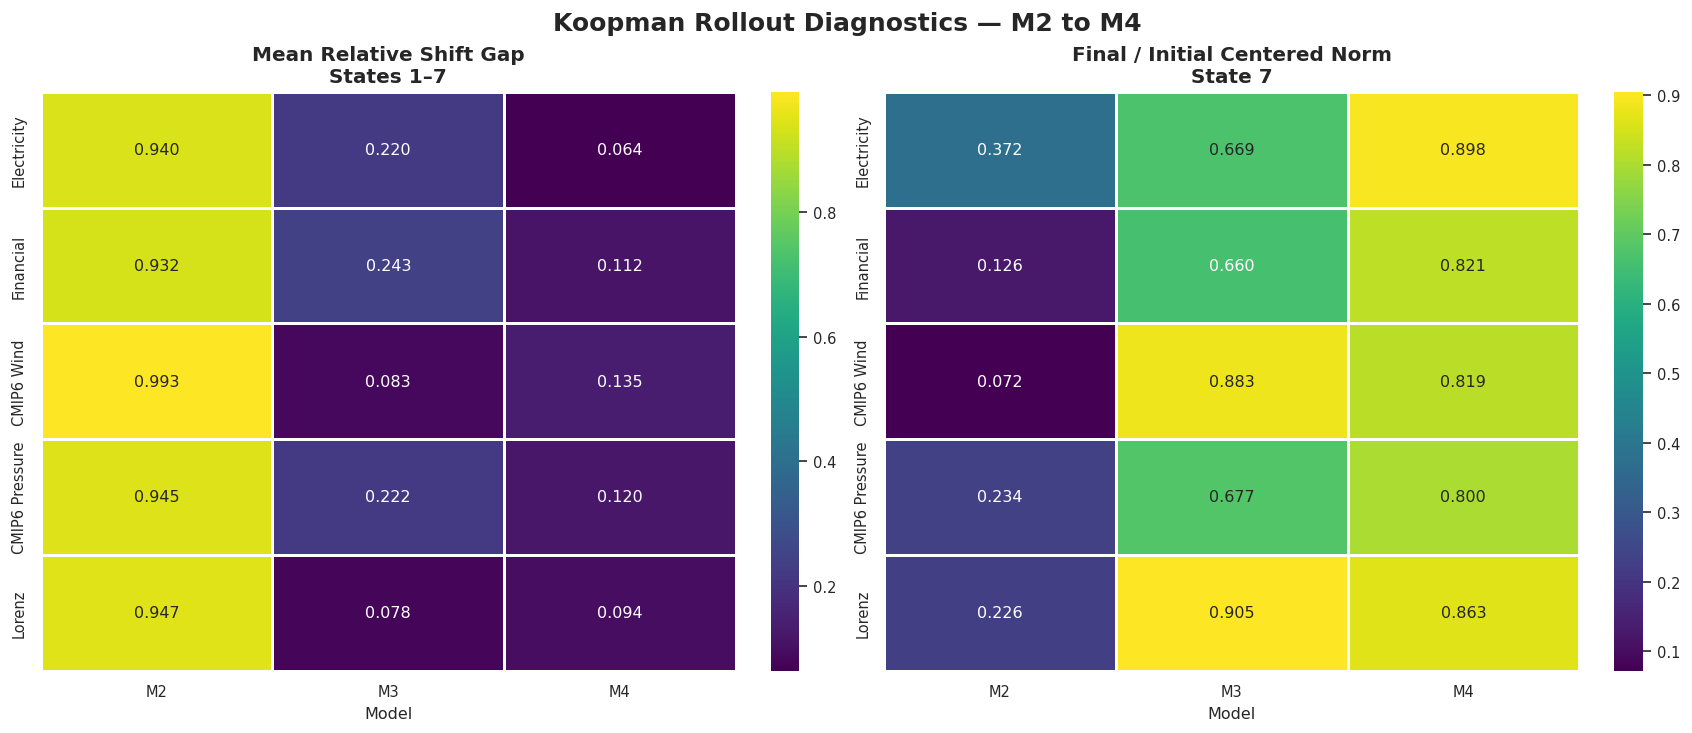

MEAN RELATIVE SHIFT GAP — LOWER IS CLOSER


model,M2,M3,M4
dataset,,,
Electricity,0.9399,0.2201,0.0636
Financial,0.9323,0.2426,0.1118
CMIP6 Wind,0.9927,0.0827,0.1348
CMIP6 Pressure,0.9451,0.2221,0.1199
Lorenz,0.9469,0.0778,0.0941



FINAL RELATIVE LATENT NORM


model,M2,M3,M4
dataset,,,
Electricity,0.3716,0.6685,0.8976
Financial,0.1263,0.6598,0.8209
CMIP6 Wind,0.0721,0.8835,0.8194
CMIP6 Pressure,0.2344,0.6773,0.8003
Lorenz,0.2257,0.9049,0.8627



M1 — SINGLE-STEP LATENT TRANSFORMATION


,dataset,mean_one_step_ratio,max_one_step_ratio,sigma_max
0,Electricity,0.5174,0.5500,0.8717
1,Financial,0.5708,0.5925,0.9241
2,CMIP6 Wind,0.4938,0.5761,0.9585
3,CMIP6 Pressure,0.5475,0.6035,0.9571
4,Lorenz,0.5300,0.5722,0.9238



SHIFT GAP VS FORECAST MSE


,dataset,model,mean_relative_gap,test_mse
0,CMIP6 Pressure,M2,0.9451,0.00902528
1,CMIP6 Pressure,M3,0.2221,0.00751516
2,CMIP6 Pressure,M4,0.1199,0.00817099
3,CMIP6 Wind,M2,0.9927,0.03188637
4,CMIP6 Wind,M3,0.0827,0.02909119
5,CMIP6 Wind,M4,0.1348,0.02996535
6,Electricity,M2,0.9399,0.03071698
7,Electricity,M3,0.2201,0.02194518
8,Electricity,M4,0.0636,0.02570613
9,Financial,M2,0.9323,0.00203047



[PASS] Latent dynamics analysis completed


In [11]:
ROLLOUT_MODELS = ["M2", "M3", "M4"]

latent_records = []
shift_gap_records = []
single_step_records = []

for dataset in DATASETS:
    for model in ["M1", *ROLLOUT_MODELS]:
        arrays = xai_data[dataset]["models"][model][
            "arrays"
        ]

        norms = np.asarray(
            arrays["koop_centered_norm"],
            dtype=np.float64
        )

        states = np.asarray(
            arrays["koop_states"],
            dtype=np.float64
        )

        sigma_max = float(
            spectral_df.loc[
                (spectral_df["dataset"] == dataset)
                & (spectral_df["model"] == model),
                "sigma_max"
            ].iloc[0]
        )

        expected_states = 2 if model == "M1" else HORIZON

        assert norms.shape == (8, expected_states)
        assert states.shape == (8, expected_states, 96)
        assert np.isfinite(norms).all()
        assert (norms >= 0).all()

        if model == "M4":
            assert "koop_equilibrium" in arrays

            equilibrium = np.asarray(
                arrays["koop_equilibrium"],
                dtype=np.float64
            ).reshape(1, 1, -1)

            recomputed_norms = np.linalg.norm(
                states - equilibrium,
                axis=-1
            )
        else:
            recomputed_norms = np.linalg.norm(
                states,
                axis=-1
            )

        np.testing.assert_allclose(
            norms,
            recomputed_norms,
            rtol=1e-4,
            atol=1e-5
        )

        norm_ratios = (
            norms / np.maximum(norms[:, :1], 1e-12)
        )

        if model == "M1":
            single_step_records.append({
                "dataset": dataset,
                "model": model,
                "mean_one_step_ratio": float(
                    norm_ratios[:, 1].mean()
                ),
                "max_one_step_ratio": float(
                    norm_ratios[:, 1].max()
                ),
                "sigma_max": sigma_max
            })
            continue

        assert "koop_shift_gap" in arrays
        assert "koop_relative_shift_gap" in arrays

        shift_gap = np.asarray(
            arrays["koop_shift_gap"],
            dtype=np.float64
        )

        relative_gap = np.asarray(
            arrays["koop_relative_shift_gap"],
            dtype=np.float64
        )

        assert shift_gap.shape == (8, HORIZON)
        assert relative_gap.shape == (8, HORIZON)

        assert np.isnan(shift_gap[:, 0]).all()
        assert np.isnan(relative_gap[:, 0]).all()

        assert np.isfinite(shift_gap[:, 1:]).all()
        assert np.isfinite(relative_gap[:, 1:]).all()

        assert (shift_gap[:, 1:] >= 0).all()
        assert (relative_gap[:, 1:] >= 0).all()

        for step in range(HORIZON):
            latent_records.append({
                "dataset": dataset,
                "model": model,
                "state_step": step,
                "forecast_lead": step + 1,
                "mean_centered_norm": float(
                    norms[:, step].mean()
                ),
                "mean_relative_norm": float(
                    norm_ratios[:, step].mean()
                ),
                "std_relative_norm": float(
                    norm_ratios[:, step].std()
                ),
                "max_relative_norm": float(
                    norm_ratios[:, step].max()
                ),
                "sigma_max": sigma_max
            })

            if step == 0:
                continue

            shift_gap_records.append({
                "dataset": dataset,
                "model": model,
                "state_step": step,
                "forecast_lead": step + 1,
                "mean_absolute_gap": float(
                    shift_gap[:, step].mean()
                ),
                "mean_relative_gap": float(
                    relative_gap[:, step].mean()
                ),
                "median_relative_gap": float(
                    np.median(relative_gap[:, step])
                ),
                "std_relative_gap": float(
                    relative_gap[:, step].std()
                )
            })

latent_df = pd.DataFrame(latent_records)
shift_gap_df = pd.DataFrame(shift_gap_records)
single_step_df = pd.DataFrame(single_step_records)

assert len(latent_df) == 5 * 3 * HORIZON
assert len(shift_gap_df) == 5 * 3 * (HORIZON - 1)
assert len(single_step_df) == 5

fig, axes = plt.subplots(
    5, 2,
    figsize=(16, 20),
    constrained_layout=True
)

for i, dataset in enumerate(DATASETS):
    ax_norm = axes[i, 0]
    ax_gap = axes[i, 1]

    for model in ROLLOUT_MODELS:
        norm_subset = latent_df[
            (latent_df["dataset"] == dataset)
            & (latent_df["model"] == model)
        ].sort_values("state_step")

        gap_subset = shift_gap_df[
            (shift_gap_df["dataset"] == dataset)
            & (shift_gap_df["model"] == model)
        ].sort_values("state_step")

        steps = norm_subset["state_step"].to_numpy()
        mean_norm = norm_subset[
            "mean_relative_norm"
        ].to_numpy()
        std_norm = norm_subset[
            "std_relative_norm"
        ].to_numpy()

        ax_norm.plot(
            steps,
            mean_norm,
            color=MODEL_COLORS[model],
            marker="o",
            markersize=4,
            linewidth=2,
            label=model
        )

        ax_norm.fill_between(
            steps,
            np.maximum(mean_norm - std_norm, 0),
            mean_norm + std_norm,
            color=MODEL_COLORS[model],
            alpha=0.12
        )

        gap_steps = gap_subset[
            "state_step"
        ].to_numpy()

        ax_gap.plot(
            gap_steps,
            gap_subset["mean_relative_gap"],
            color=MODEL_COLORS[model],
            marker="o",
            markersize=4,
            linewidth=2,
            label=model
        )

    ax_norm.axhline(
        1,
        color="#64748B",
        linestyle="--",
        linewidth=1
    )

    ax_norm.set_title(
        f"{dataset} — Latent State Contraction",
        fontweight="bold"
    )

    ax_gap.set_title(
        f"{dataset} — Relative Shift Gap",
        fontweight="bold"
    )

    ax_norm.set_xlabel(
        "Rollout State Index (0–7)"
    )
    ax_gap.set_xlabel(
        "Rollout State Index (1–7)"
    )

    ax_norm.set_ylabel(
        "Centered Norm / Initial Norm"
    )
    ax_gap.set_ylabel(
        "Mean Relative Shift Gap"
    )

    ax_norm.set_xticks(range(HORIZON))
    ax_gap.set_xticks(range(1, HORIZON))

    for ax in [ax_norm, ax_gap]:
        ax.grid(alpha=0.2)
        ax.legend(frameon=False, fontsize=9)

fig.suptitle(
    "Temporal Koopman — Latent Dynamics and Shift Gap\n"
    "M2/M3/M4 | P100/H8 | 8 Selected Test Windows",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig15_latent_dynamics.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig15_latent_dynamics.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

gap_summary = (
    shift_gap_df.groupby(
        ["dataset", "model"],
        as_index=False
    )
    .agg(
        mean_relative_gap=("mean_relative_gap", "mean"),
        final_relative_gap=("mean_relative_gap", "last"),
        mean_absolute_gap=("mean_absolute_gap", "mean")
    )
)

norm_final = latent_df[
    latent_df["state_step"] == HORIZON - 1
][
    ["dataset", "model", "mean_relative_norm"]
].rename(columns={
    "mean_relative_norm": "final_relative_norm"
})

gap_summary = gap_summary.merge(
    norm_final,
    on=["dataset", "model"],
    validate="one_to_one"
)

summary_lookup = xai_summary.set_index(
    ["dataset", "model"]
)

gap_summary["test_mse"] = [
    float(
        summary_lookup.loc[
            (dataset, model),
            "full_test_mse_from_training"
        ]
    )
    for dataset, model in zip(
        gap_summary["dataset"],
        gap_summary["model"]
    )
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    constrained_layout=True
)

metrics = [
    (
        "mean_relative_gap",
        "Mean Relative Shift Gap\nStates 1–7"
    ),
    (
        "final_relative_norm",
        "Final / Initial Centered Norm\nState 7"
    )
]

for ax, (metric, title) in zip(axes, metrics):
    matrix = gap_summary.pivot(
        index="dataset",
        columns="model",
        values=metric
    ).reindex(
        index=DATASETS,
        columns=ROLLOUT_MODELS
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt=".3f",
        cmap="viridis",
        linewidths=0.8,
        linecolor="white",
        cbar=True,
        ax=ax
    )

    ax.set_title(
        title,
        fontweight="bold",
        fontsize=12
    )

    ax.set_xlabel("Model")
    ax.set_ylabel("")

fig.suptitle(
    "Koopman Rollout Diagnostics — M2 to M4",
    fontsize=15,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig16_latent_diagnostics_summary.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("MEAN RELATIVE SHIFT GAP — LOWER IS CLOSER")

display(
    gap_summary.pivot(
        index="dataset",
        columns="model",
        values="mean_relative_gap"
    ).reindex(
        index=DATASETS,
        columns=ROLLOUT_MODELS
    ).style.format("{:.4f}")
)

print("\nFINAL RELATIVE LATENT NORM")

display(
    gap_summary.pivot(
        index="dataset",
        columns="model",
        values="final_relative_norm"
    ).reindex(
        index=DATASETS,
        columns=ROLLOUT_MODELS
    ).style.format("{:.4f}")
)

print("\nM1 — SINGLE-STEP LATENT TRANSFORMATION")

display(
    single_step_df[
        [
            "dataset",
            "mean_one_step_ratio",
            "max_one_step_ratio",
            "sigma_max"
        ]
    ].style.format({
        "mean_one_step_ratio": "{:.4f}",
        "max_one_step_ratio": "{:.4f}",
        "sigma_max": "{:.4f}"
    })
)

print("\nSHIFT GAP VS FORECAST MSE")

display(
    gap_summary[
        [
            "dataset",
            "model",
            "mean_relative_gap",
            "test_mse"
        ]
    ].style.format({
        "mean_relative_gap": "{:.4f}",
        "test_mse": "{:.8f}"
    })
)

latent_df.to_csv(
    FIGURES_DIR / "latent_rollout_norms.csv",
    index=False
)

shift_gap_df.to_csv(
    FIGURES_DIR / "latent_shift_gap_by_step.csv",
    index=False
)

gap_summary.to_csv(
    FIGURES_DIR / "latent_diagnostics_summary.csv",
    index=False
)

single_step_df.to_csv(
    FIGURES_DIR / "m1_single_step_contraction.csv",
    index=False
)

print("\n[PASS] Latent dynamics analysis completed")


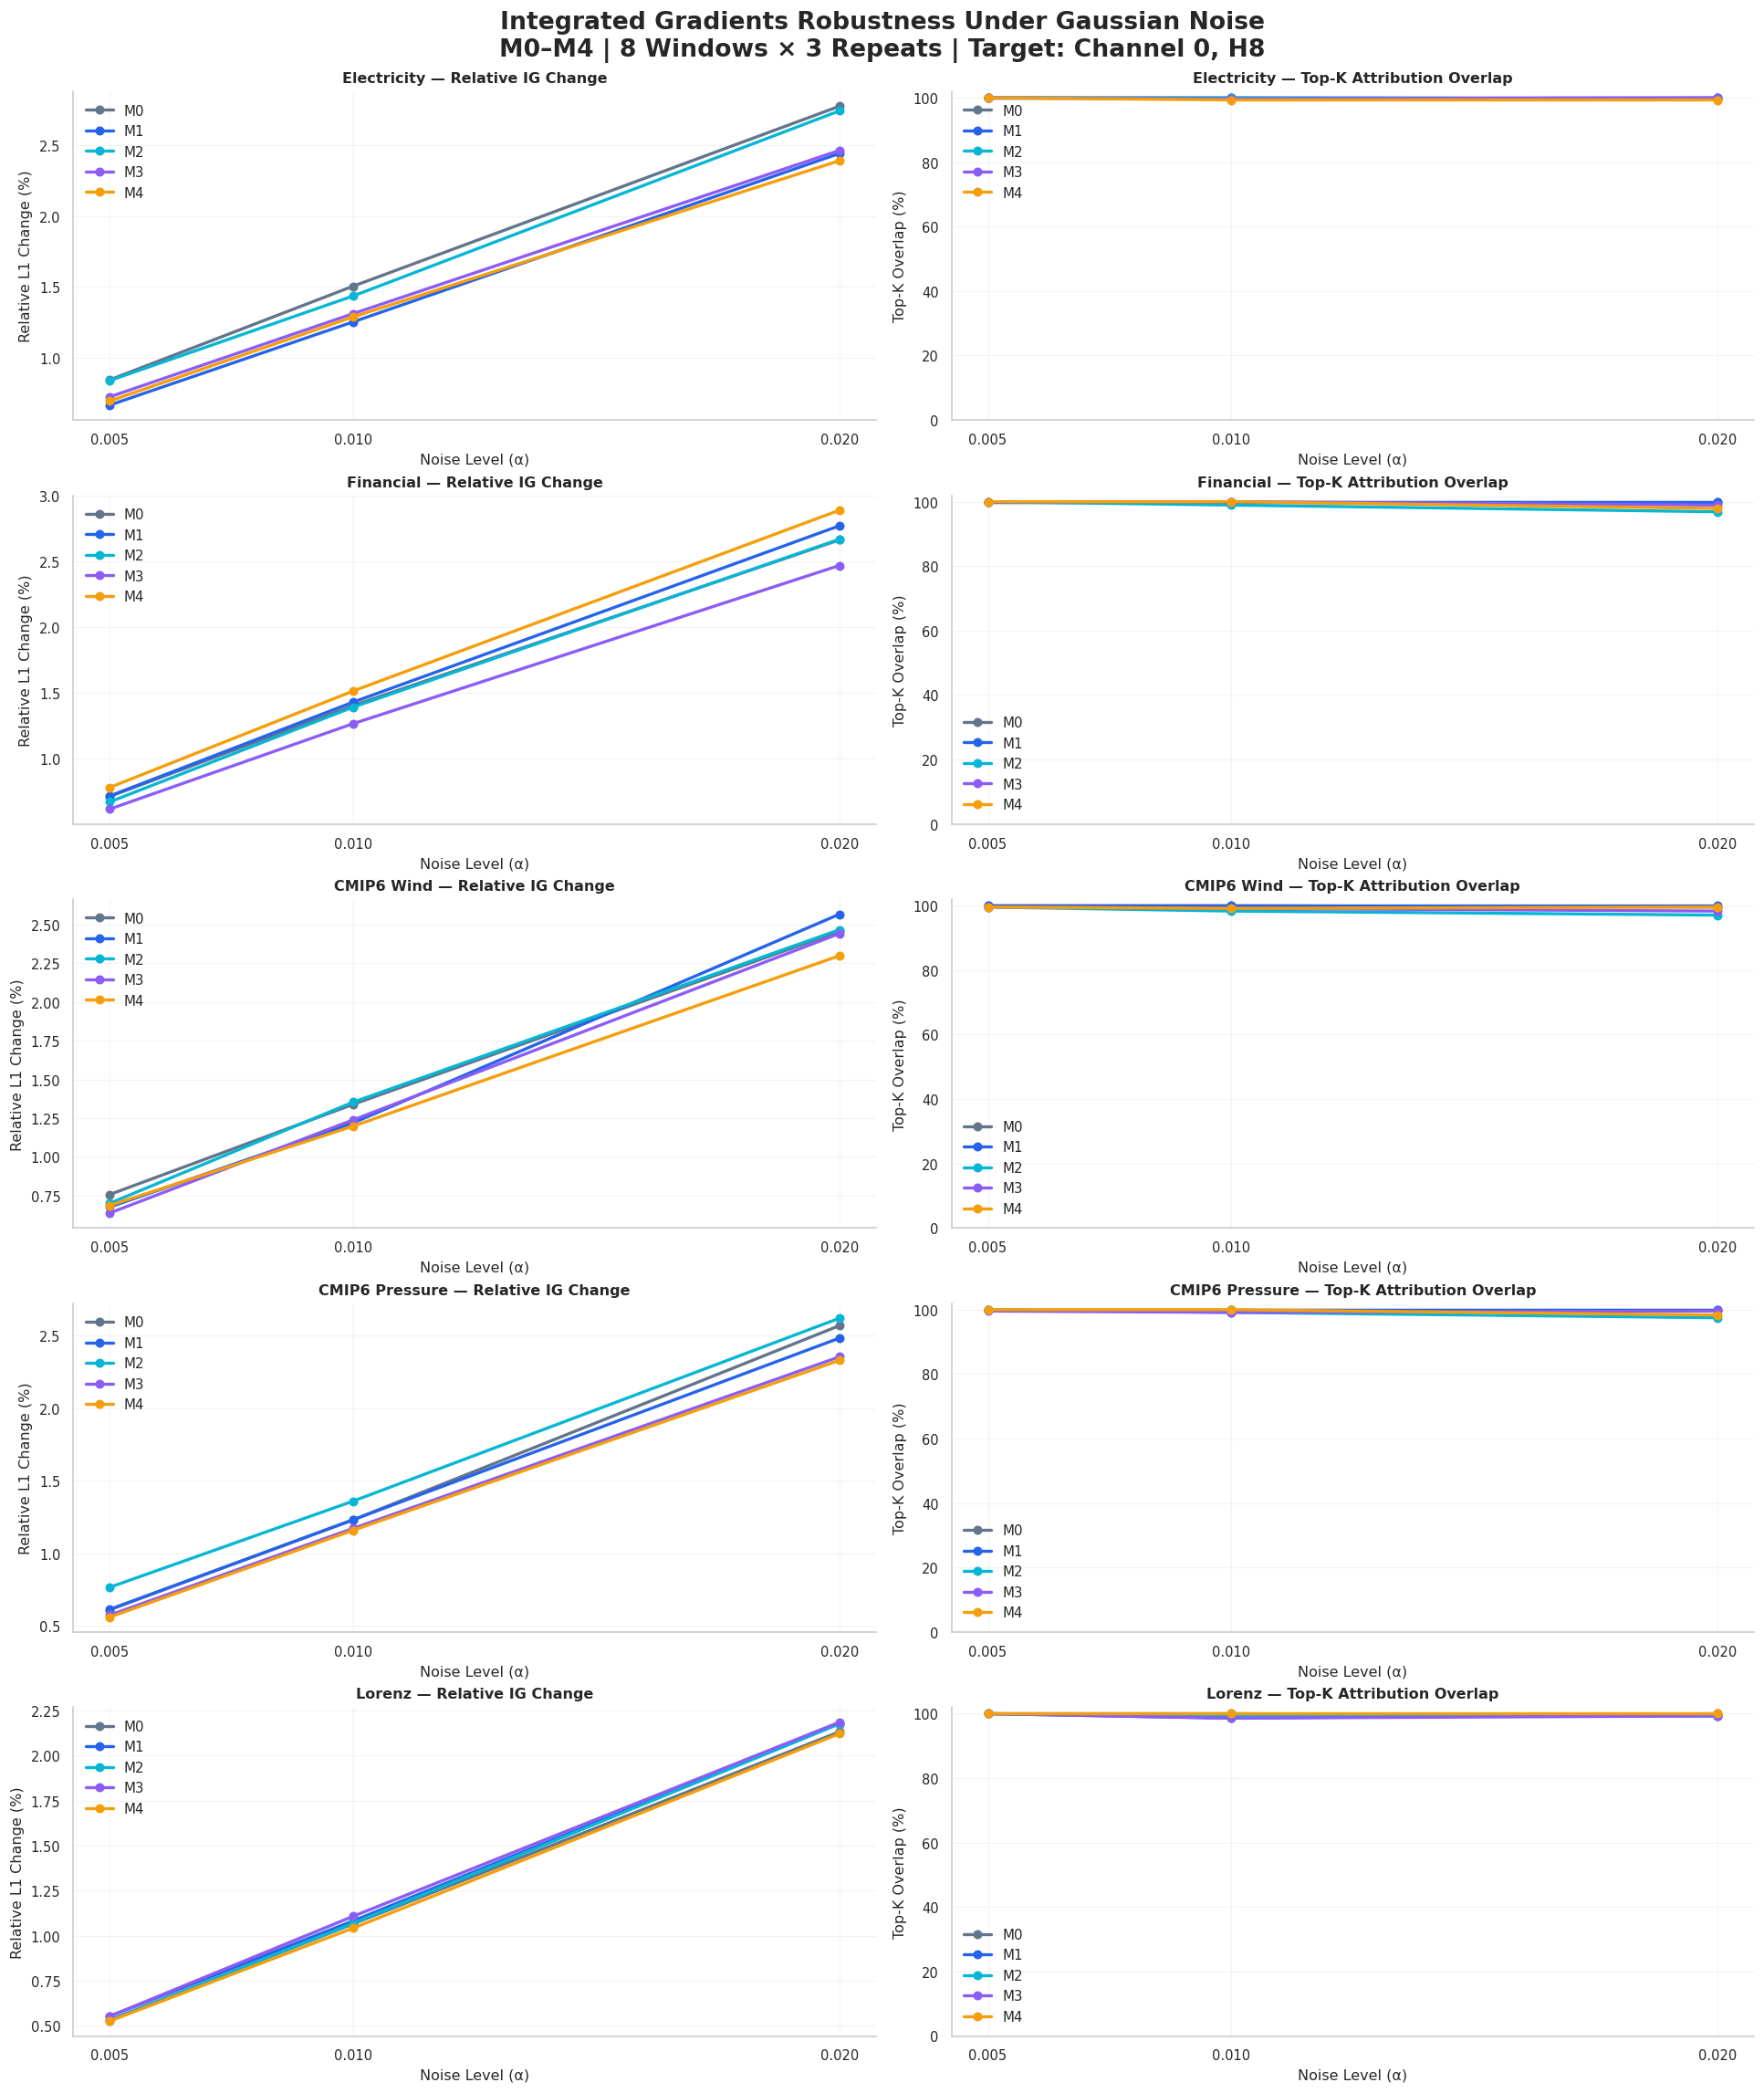

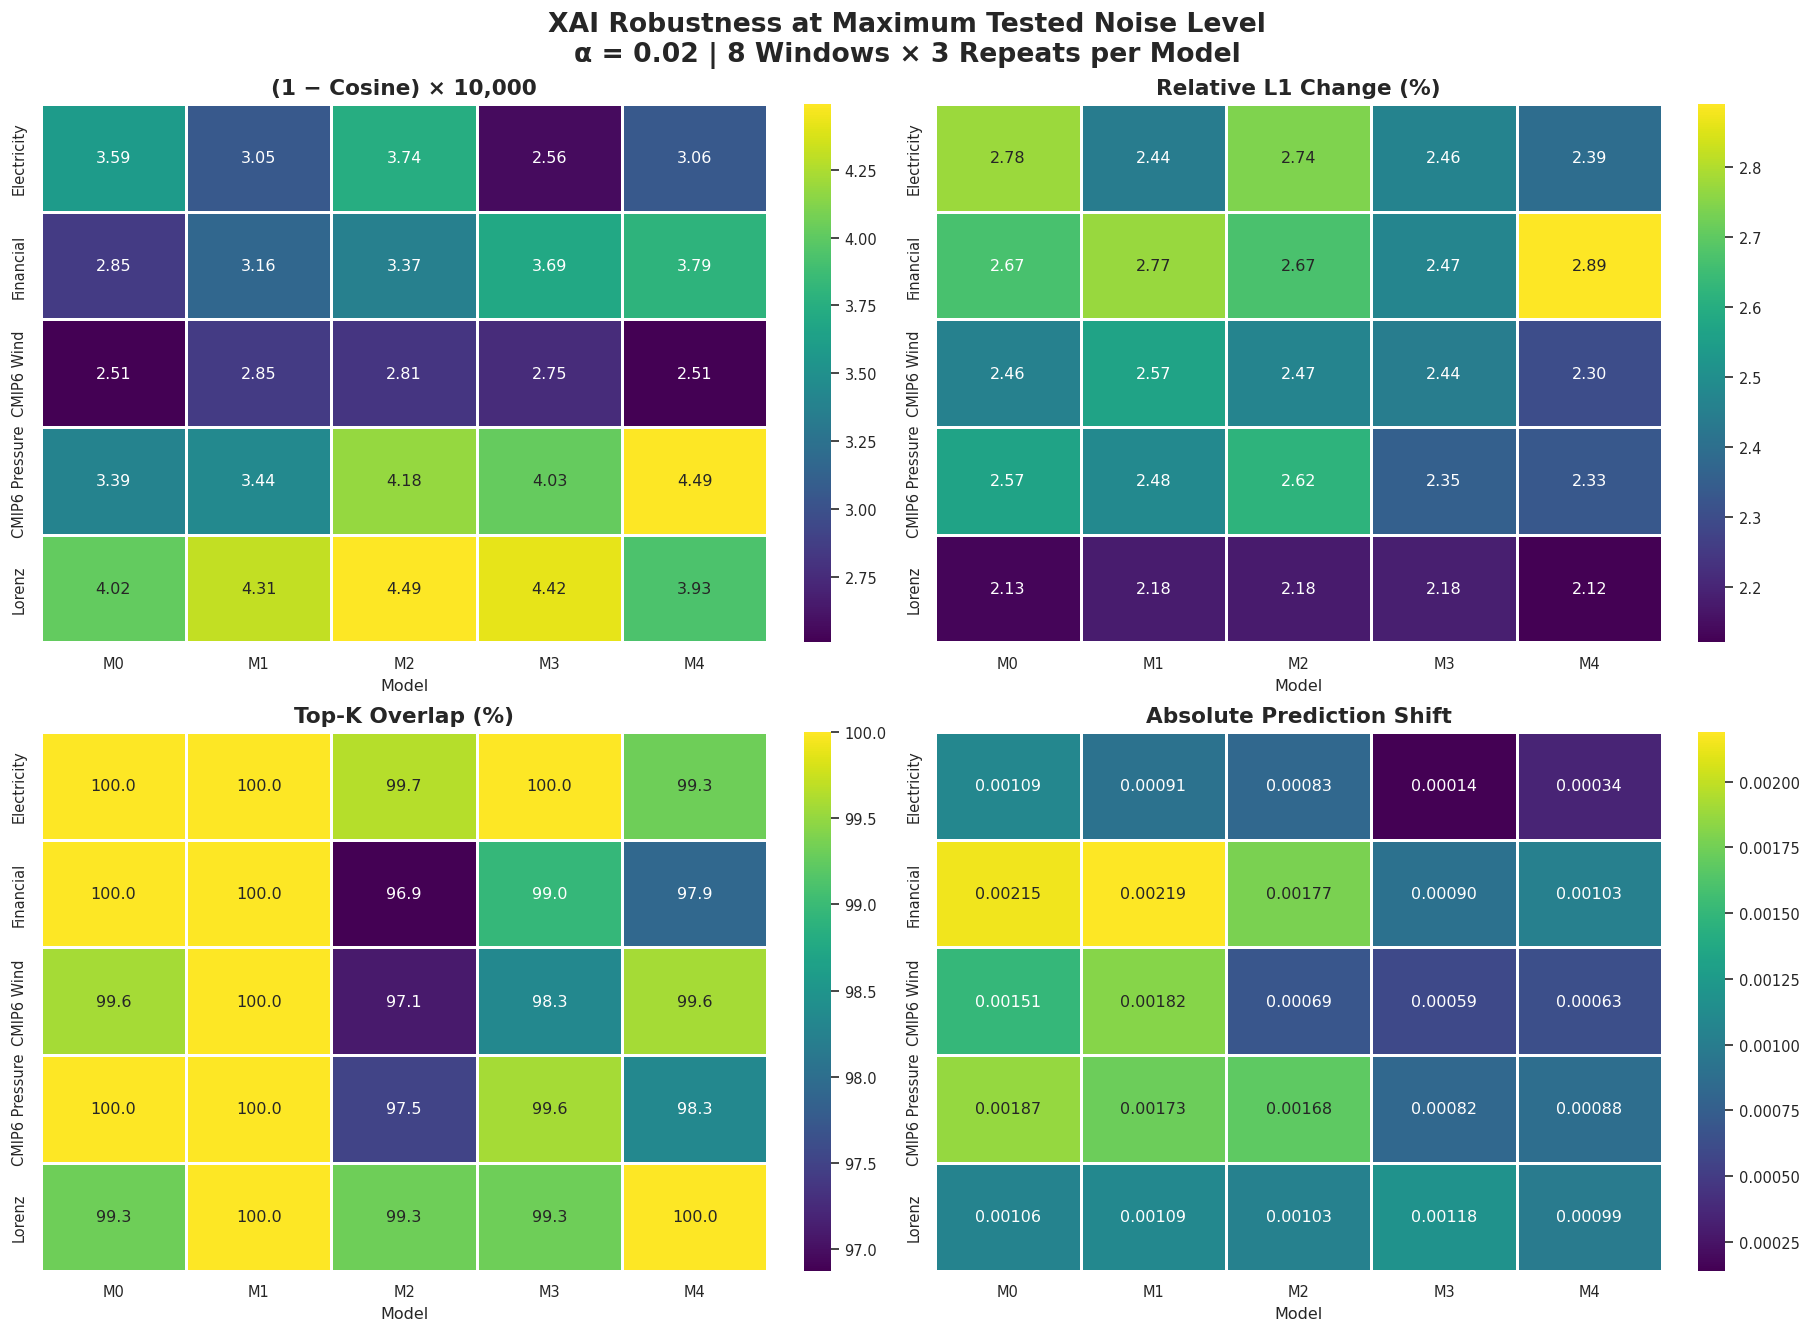

ROBUSTNESS AT ALPHA = 0.02 — RELATIVE L1 CHANGE


model,M0,M1,M2,M3,M4
dataset_name,,,,,
Electricity,2.776%,2.443%,2.743%,2.464%,2.391%
Financial,2.665%,2.772%,2.670%,2.470%,2.891%
CMIP6 Wind,2.458%,2.568%,2.467%,2.443%,2.300%
CMIP6 Pressure,2.567%,2.482%,2.619%,2.353%,2.328%
Lorenz,2.131%,2.178%,2.175%,2.184%,2.121%



TOP-K OVERLAP AT ALPHA = 0.02


model,M0,M1,M2,M3,M4
dataset_name,,,,,
Electricity,100.00%,100.00%,99.65%,100.00%,99.31%
Financial,100.00%,100.00%,96.88%,98.96%,97.92%
CMIP6 Wind,99.58%,100.00%,97.08%,98.33%,99.58%
CMIP6 Pressure,100.00%,100.00%,97.50%,99.58%,98.33%
Lorenz,99.31%,100.00%,99.31%,99.31%,100.00%



COSINE SIMILARITY AT ALPHA = 0.02


model,M0,M1,M2,M3,M4
dataset_name,,,,,
Electricity,0.9996408,0.9996947,0.9996256,0.9997435,0.9996945
Financial,0.9997146,0.9996835,0.9996633,0.9996306,0.9996213
CMIP6 Wind,0.9997491,0.9997146,0.9997186,0.9997249,0.9997490
CMIP6 Pressure,0.9996607,0.9996557,0.9995824,0.9995974,0.9995508
Lorenz,0.9995985,0.9995693,0.9995512,0.9995585,0.9996070



ABSOLUTE PREDICTION SHIFT AT ALPHA = 0.02


model,M0,M1,M2,M3,M4
dataset_name,,,,,
Electricity,0.001087,0.000914,0.000826,0.000140,0.000343
Financial,0.002149,0.002189,0.001775,0.000901,0.001026
CMIP6 Wind,0.001505,0.001820,0.000685,0.000588,0.000629
CMIP6 Pressure,0.001868,0.001730,0.001678,0.000821,0.000875
Lorenz,0.001059,0.001093,0.001032,0.001183,0.000985



Robustness observations: 1800
Aggregated conditions: 75
Alpha=0.02 conditions: 25

[PASS] IG robustness analysis completed


In [12]:
NOISE_LEVELS = [0.005, 0.01, 0.02]
N_REPEATS = 3
MAX_NOISE = 0.02

robustness_frames = []

required_columns = {
    "dataset",
    "model",
    "sample_index",
    "lookback",
    "horizon",
    "ig_steps",
    "noise_alpha",
    "repeat",
    "noise_seed",
    "block_size",
    "top_fraction",
    "cosine_similarity",
    "relative_l1_change",
    "topk_overlap",
    "prediction_shift"
}

for dataset, dataset_key in DATASET_MAP.items():
    frame = validation_tables["robustness"][dataset].copy()

    assert required_columns.issubset(frame.columns)
    assert len(frame) == 5 * 8 * 3 * 3
    assert set(frame["dataset"]) == {dataset_key}
    assert set(frame["model"]) == set(MODELS)

    assert (frame["lookback"] == LOOKBACK).all()
    assert (frame["horizon"] == HORIZON).all()
    assert (frame["ig_steps"] == 32).all()
    assert (frame["block_size"] == 10).all()

    np.testing.assert_allclose(
        frame["top_fraction"],
        0.2,
        atol=1e-8
    )

    np.testing.assert_allclose(
        sorted(frame["noise_alpha"].unique()),
        NOISE_LEVELS,
        atol=1e-8
    )

    assert set(frame["repeat"]) == set(range(N_REPEATS))

    assert not frame.duplicated(
        ["model", "sample_index", "noise_alpha", "repeat"]
    ).any()

    expected_indices = set(
        xai_data[dataset]["indices"].astype(int)
    )

    for (model, alpha, repeat), subset in frame.groupby(
        ["model", "noise_alpha", "repeat"]
    ):
        assert len(subset) == 8
        assert set(subset["sample_index"]) == expected_indices

    seed_counts = frame.groupby(
        ["noise_alpha", "repeat"]
    )["noise_seed"].nunique()

    assert (seed_counts == 1).all()

    metric_columns = [
        "cosine_similarity",
        "relative_l1_change",
        "topk_overlap",
        "prediction_shift"
    ]

    assert np.isfinite(
        frame[metric_columns].to_numpy()
    ).all()

    assert frame["cosine_similarity"].between(
        -1.00001, 1.00001
    ).all()

    assert frame["topk_overlap"].between(
        -1e-6, 1.00001
    ).all()

    assert (
        frame[[
            "relative_l1_change",
            "prediction_shift"
        ]] >= 0
    ).all().all()

    frame["dataset_name"] = dataset

    robustness_frames.append(frame)

robustness_df = pd.concat(
    robustness_frames,
    ignore_index=True
)

assert len(robustness_df) == 1800

robustness_df["cosine_distance"] = (
    1 - robustness_df["cosine_similarity"]
).clip(lower=0)

robustness_df["relative_l1_pct"] = (
    100 * robustness_df["relative_l1_change"]
)

robustness_df["topk_overlap_pct"] = (
    100 * robustness_df["topk_overlap"]
)

robustness_df["topk_change_pct"] = (
    100 - robustness_df["topk_overlap_pct"]
)

robustness_summary = (
    robustness_df
    .groupby(
        ["dataset_name", "model", "noise_alpha"],
        as_index=False
    )
    .agg(
        n_observations=("sample_index", "size"),
        mean_cosine=("cosine_similarity", "mean"),
        mean_cosine_distance=("cosine_distance", "mean"),
        mean_relative_l1_pct=("relative_l1_pct", "mean"),
        mean_topk_overlap_pct=("topk_overlap_pct", "mean"),
        mean_topk_change_pct=("topk_change_pct", "mean"),
        mean_prediction_shift=("prediction_shift", "mean")
    )
)

assert len(robustness_summary) == 75
assert (robustness_summary["n_observations"] == 24).all()

fig, axes = plt.subplots(
    5, 2,
    figsize=(16, 19),
    constrained_layout=True
)

for i, dataset in enumerate(DATASETS):
    subset = robustness_summary[
        robustness_summary["dataset_name"] == dataset
    ]

    ax_l1 = axes[i, 0]
    ax_overlap = axes[i, 1]

    for model in MODELS:
        model_data = subset[
            subset["model"] == model
        ].sort_values("noise_alpha")

        ax_l1.plot(
            model_data["noise_alpha"],
            model_data["mean_relative_l1_pct"],
            color=MODEL_COLORS[model],
            marker="o",
            linewidth=2,
            markersize=5,
            label=model
        )

        ax_overlap.plot(
            model_data["noise_alpha"],
            model_data["mean_topk_overlap_pct"],
            color=MODEL_COLORS[model],
            marker="o",
            linewidth=2,
            markersize=5,
            label=model
        )

    ax_l1.set_title(
        f"{dataset} — Relative IG Change",
        fontweight="bold"
    )

    ax_overlap.set_title(
        f"{dataset} — Top-K Attribution Overlap",
        fontweight="bold"
    )

    ax_l1.set_ylabel(
        "Relative L1 Change (%)"
    )

    ax_overlap.set_ylabel(
        "Top-K Overlap (%)"
    )

    ax_overlap.set_ylim(0, 102)

    for ax in [ax_l1, ax_overlap]:
        ax.set_xlabel("Noise Level (α)")
        ax.set_xticks(NOISE_LEVELS)
        ax.grid(alpha=0.2)
        ax.legend(frameon=False, fontsize=9)

fig.suptitle(
    "Integrated Gradients Robustness Under Gaussian Noise\n"
    "M0–M4 | 8 Windows × 3 Repeats | Target: Channel 0, H8",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig17_ig_robustness_noise.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig17_ig_robustness_noise.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

strongest_noise = robustness_summary[
    np.isclose(
        robustness_summary["noise_alpha"],
        MAX_NOISE
    )
].copy()

assert len(strongest_noise) == 25

strongest_noise["cosine_distance_1e4"] = (
    strongest_noise["mean_cosine_distance"] * 1e4
)

heatmap_metrics = [
    (
        "cosine_distance_1e4",
        "(1 − Cosine) × 10,000",
        "{:.2f}"
    ),
    (
        "mean_relative_l1_pct",
        "Relative L1 Change (%)",
        "{:.2f}"
    ),
    (
        "mean_topk_overlap_pct",
        "Top-K Overlap (%)",
        "{:.1f}"
    ),
    (
        "mean_prediction_shift",
        "Absolute Prediction Shift",
        "{:.5f}"
    )
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 11),
    constrained_layout=True
)

for ax, (metric, title, label_format) in zip(
    axes.flatten(),
    heatmap_metrics
):
    matrix = strongest_noise.pivot(
        index="dataset_name",
        columns="model",
        values=metric
    ).reindex(
        index=DATASETS,
        columns=MODELS
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt=label_format.replace("{:", "").replace("}", ""),
        cmap="viridis",
        linewidths=0.8,
        linecolor="white",
        cbar=True,
        ax=ax
    )

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Model")
    ax.set_ylabel("")

fig.suptitle(
    "XAI Robustness at Maximum Tested Noise Level\n"
    "α = 0.02 | 8 Windows × 3 Repeats per Model",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig18_ig_robustness_summary.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig18_ig_robustness_summary.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("ROBUSTNESS AT ALPHA = 0.02 — RELATIVE L1 CHANGE")

display(
    strongest_noise.pivot(
        index="dataset_name",
        columns="model",
        values="mean_relative_l1_pct"
    ).reindex(
        index=DATASETS,
        columns=MODELS
    ).style.format("{:.3f}%")
)

print("\nTOP-K OVERLAP AT ALPHA = 0.02")

display(
    strongest_noise.pivot(
        index="dataset_name",
        columns="model",
        values="mean_topk_overlap_pct"
    ).reindex(
        index=DATASETS,
        columns=MODELS
    ).style.format("{:.2f}%")
)

print("\nCOSINE SIMILARITY AT ALPHA = 0.02")

display(
    strongest_noise.pivot(
        index="dataset_name",
        columns="model",
        values="mean_cosine"
    ).reindex(
        index=DATASETS,
        columns=MODELS
    ).style.format("{:.7f}")
)

print("\nABSOLUTE PREDICTION SHIFT AT ALPHA = 0.02")

display(
    strongest_noise.pivot(
        index="dataset_name",
        columns="model",
        values="mean_prediction_shift"
    ).reindex(
        index=DATASETS,
        columns=MODELS
    ).style.format("{:.6f}")
)

robustness_df.to_csv(
    FIGURES_DIR / "ig_robustness_all_observations.csv",
    index=False
)

robustness_summary.to_csv(
    FIGURES_DIR / "ig_robustness_by_noise.csv",
    index=False
)

strongest_noise.to_csv(
    FIGURES_DIR / "ig_robustness_alpha002.csv",
    index=False
)

print("\nRobustness observations:", len(robustness_df))
print("Aggregated conditions:", len(robustness_summary))
print("Alpha=0.02 conditions:", len(strongest_noise))
print("\n[PASS] IG robustness analysis completed")


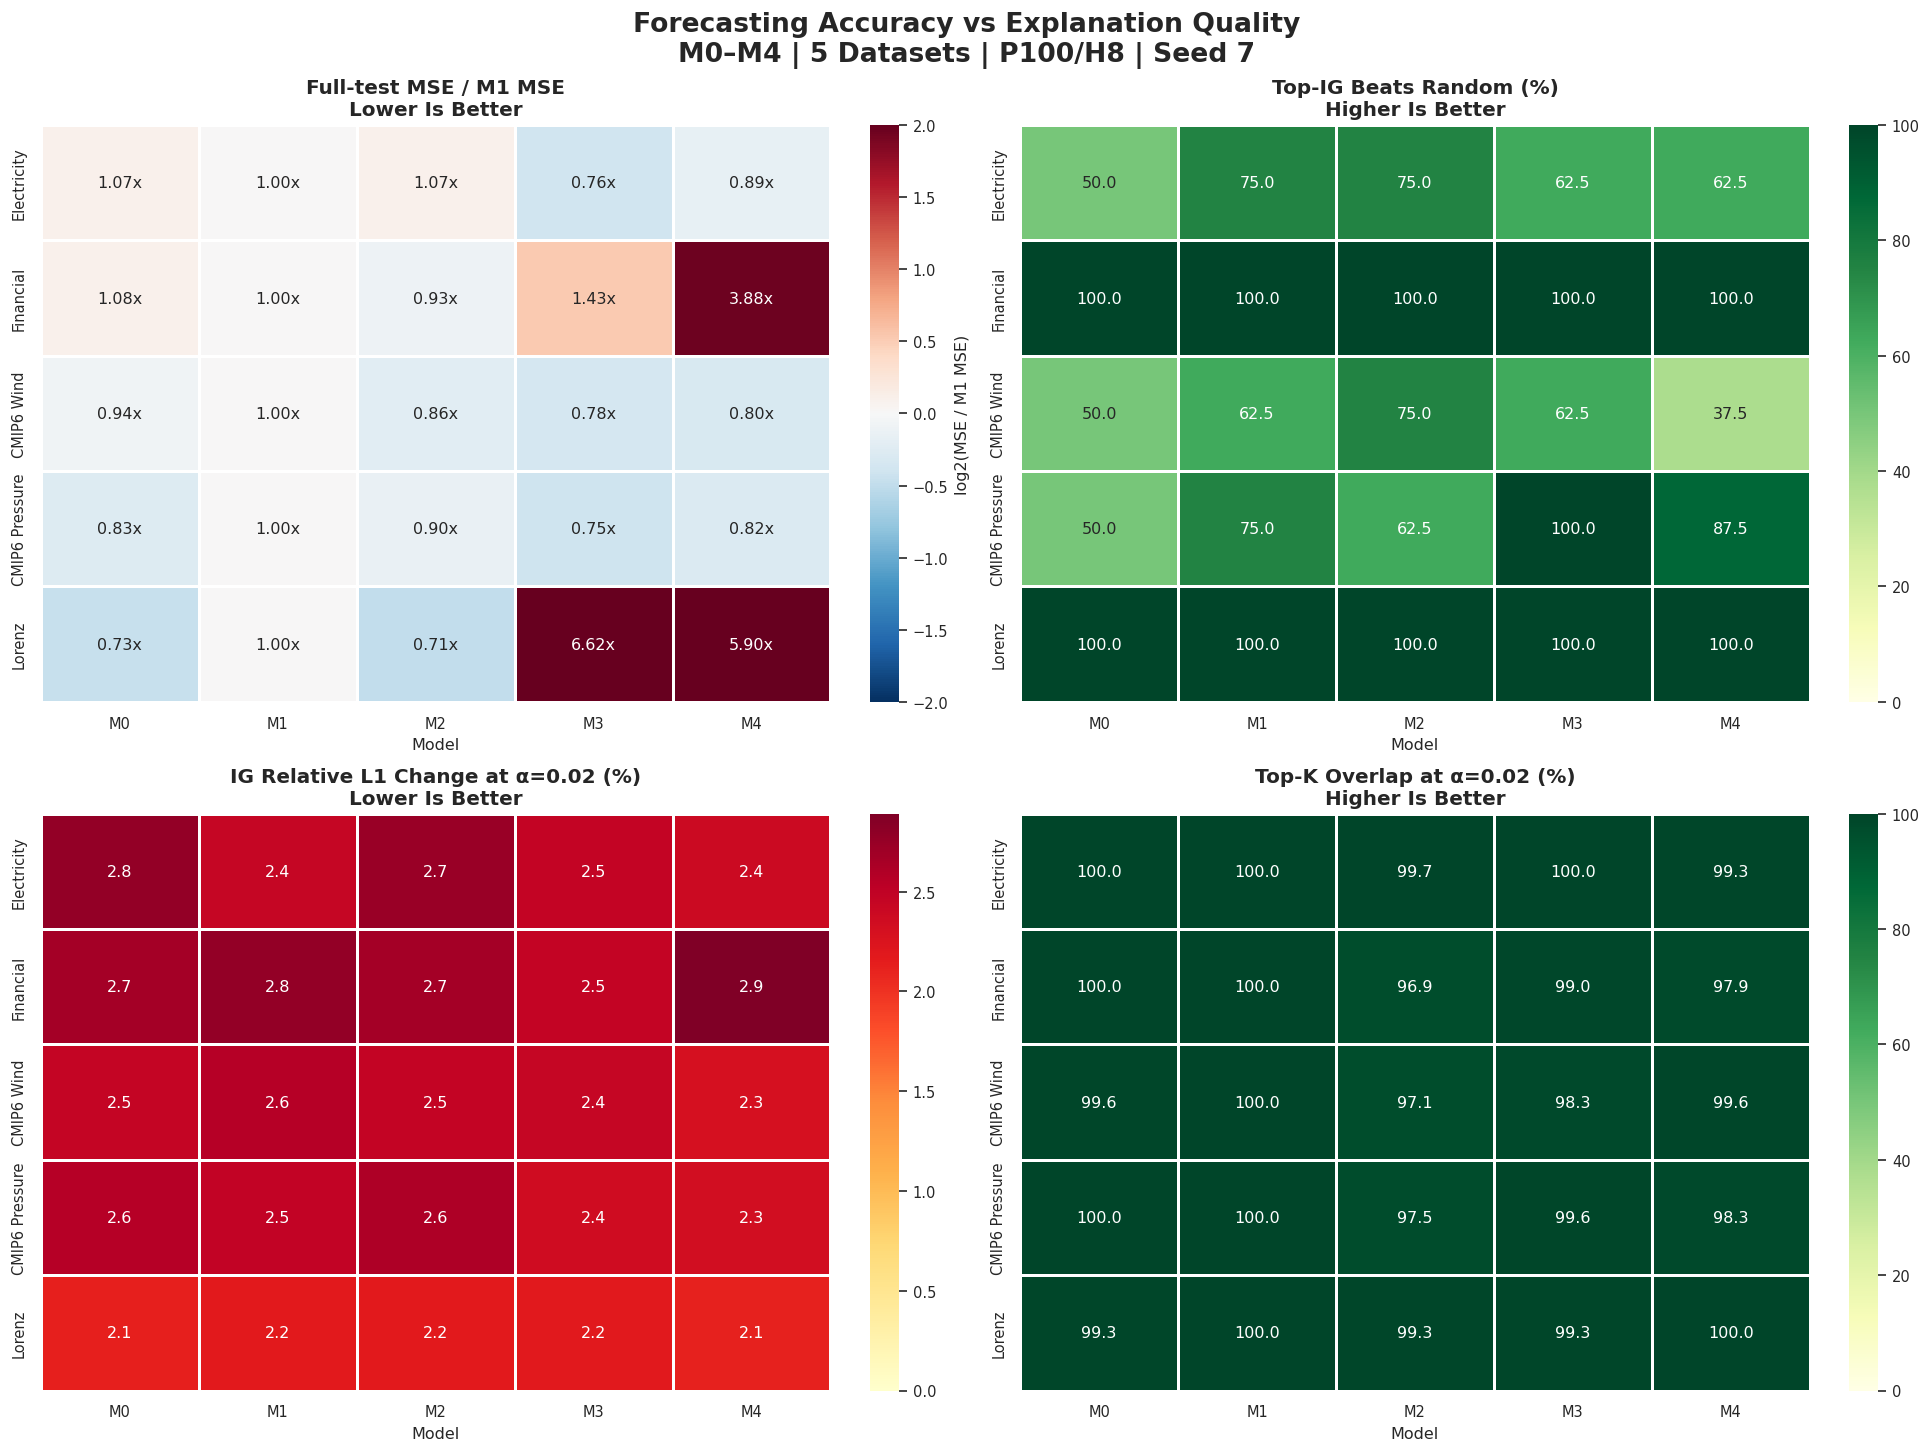

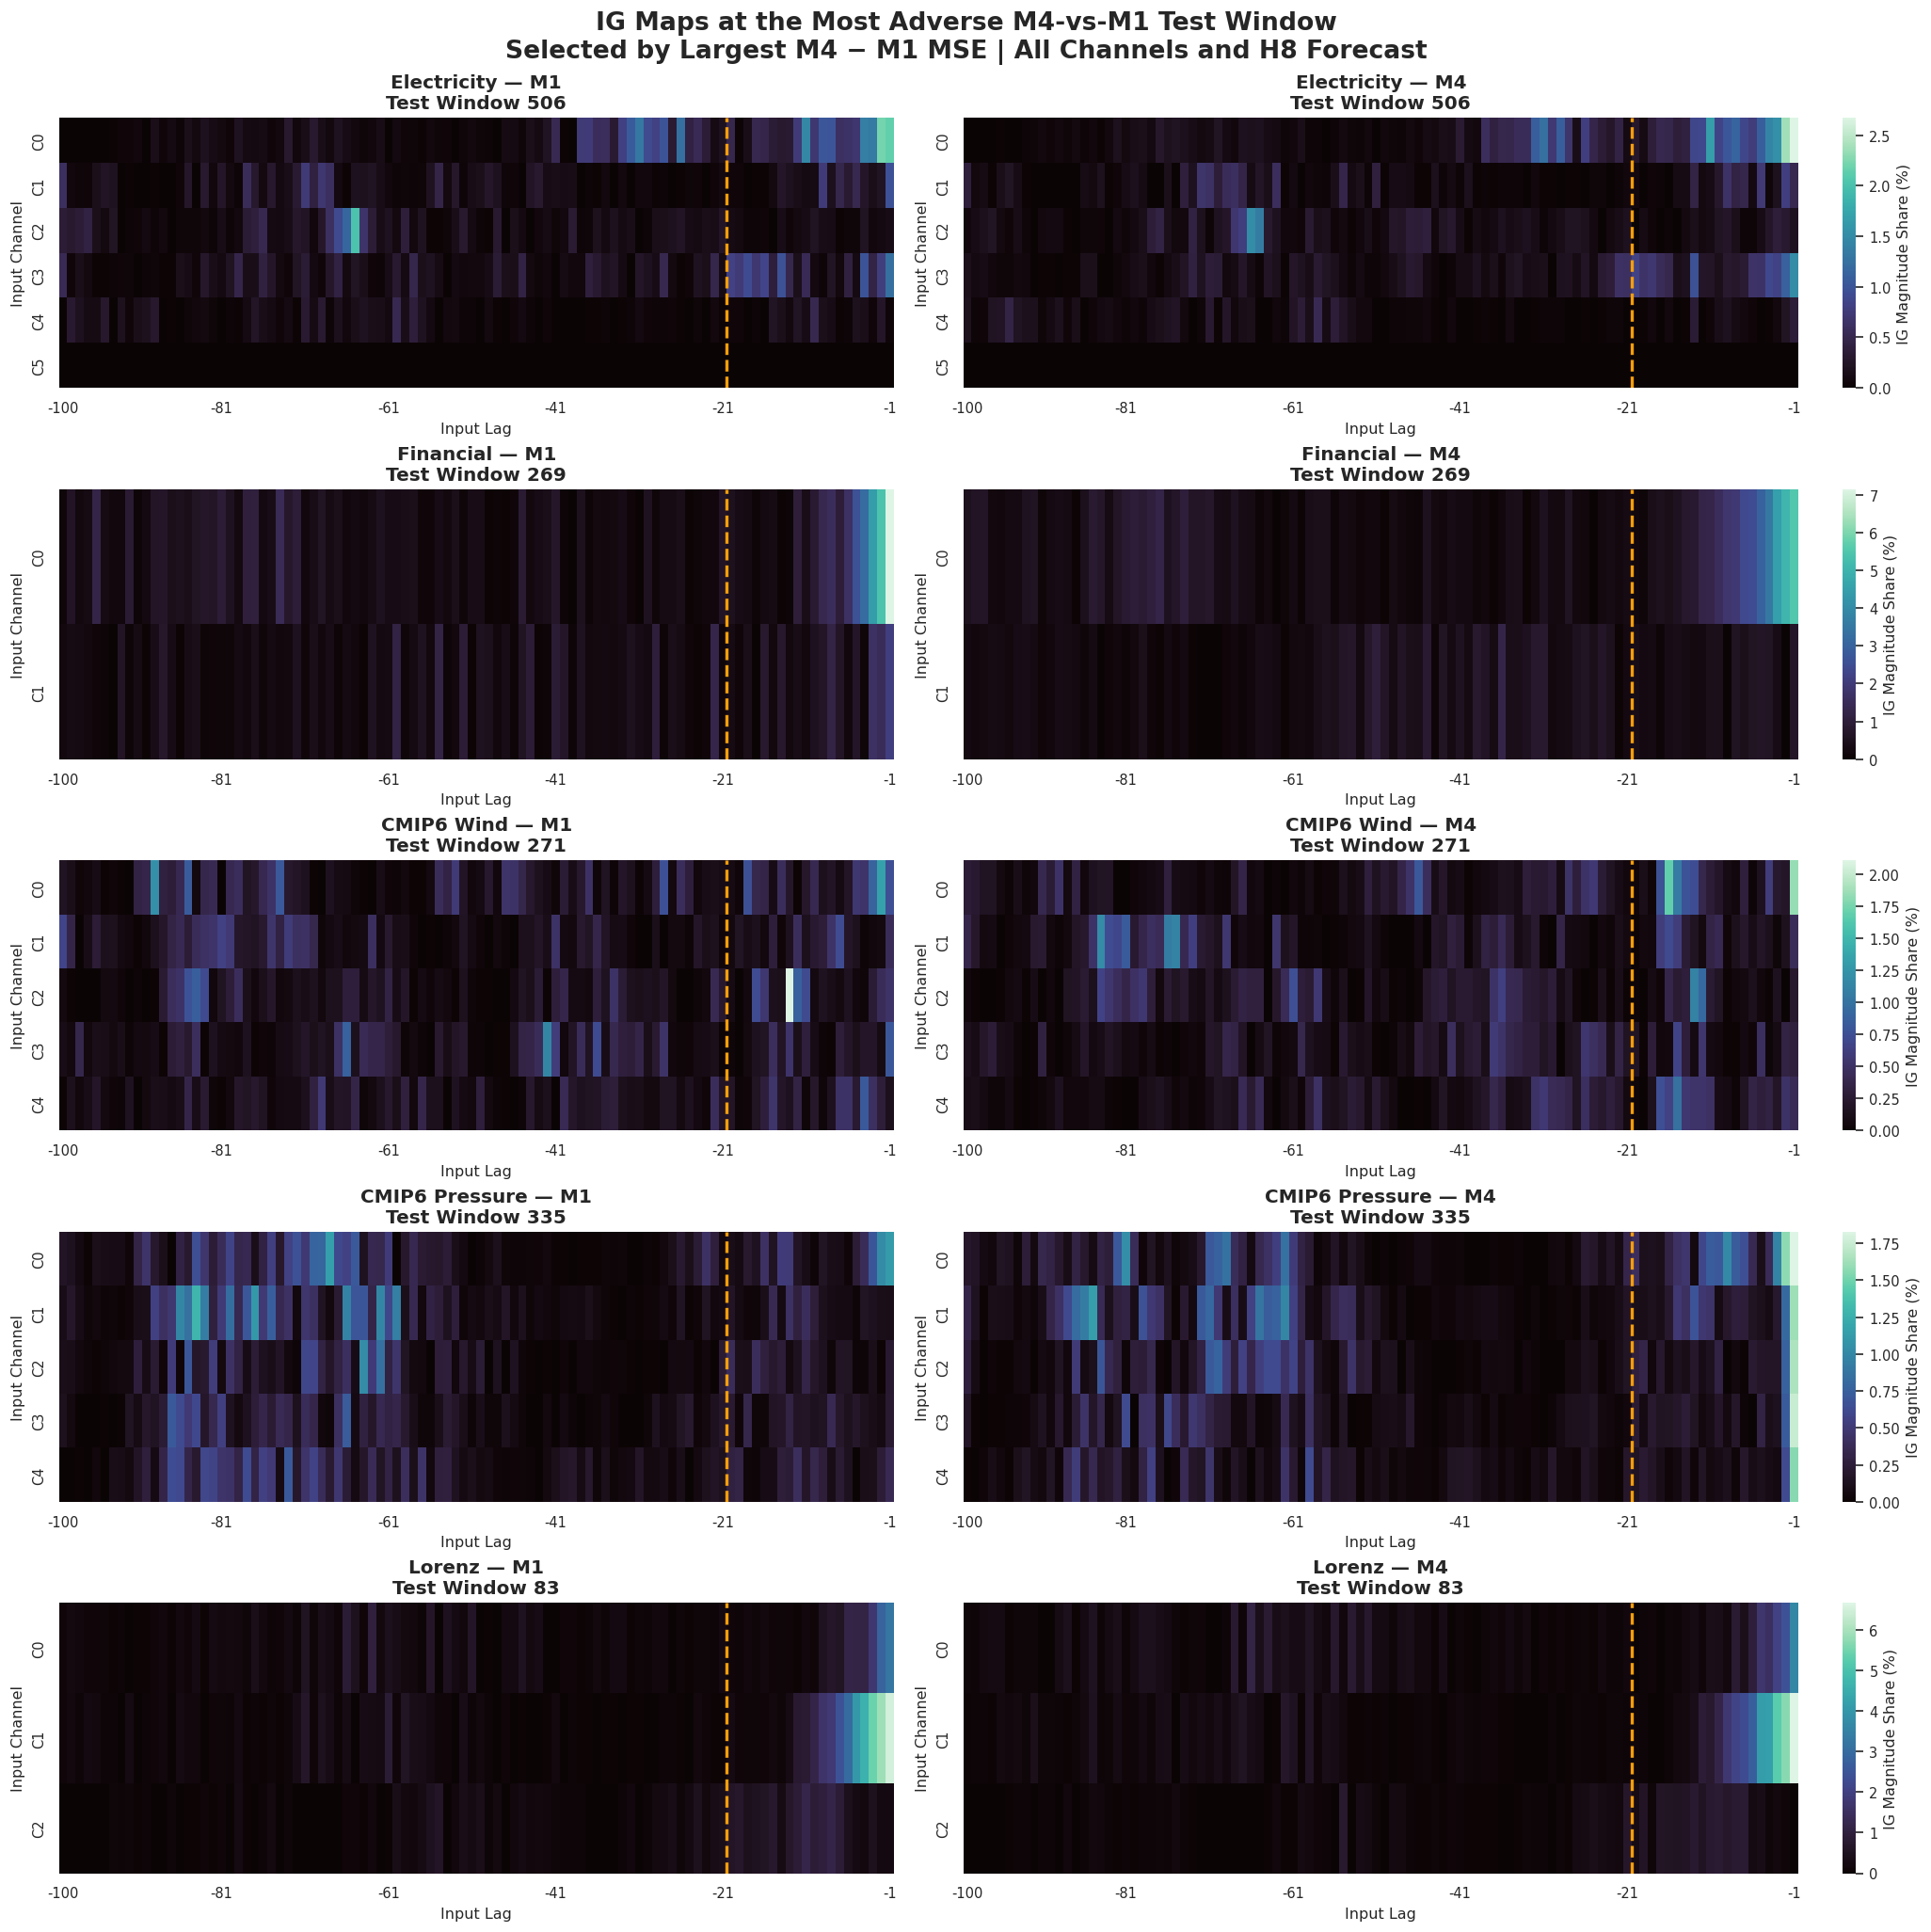

M4 VS M1 — FORECASTING & EXPLANATION QUALITY


,m4_vs_m1_test_mse_pct,m1_faithfulness_win_pct,m4_faithfulness_win_pct,m1_noise_l1_pct,m4_noise_l1_pct,m1_topk_overlap_pct,m4_topk_overlap_pct,m1_spectral_radius,m4_spectral_radius
dataset,,,,,,,,,
Electricity,+10.65%,75.0%,62.5%,2.44%,2.39%,100.0%,99.3%,0.5639,0.9848
Financial,-287.98%,100.0%,100.0%,2.77%,2.89%,100.0%,97.9%,0.5753,0.9727
CMIP6 Wind,+19.53%,62.5%,37.5%,2.57%,2.30%,100.0%,99.6%,0.6200,0.9728
CMIP6 Pressure,+18.08%,75.0%,87.5%,2.48%,2.33%,100.0%,98.3%,0.6002,0.9689
Lorenz,-489.92%,100.0%,100.0%,2.18%,2.12%,100.0%,100.0%,0.5547,0.9796



MOST ADVERSE M4-VS-M1 WINDOWS


,dataset,sample_position,test_window_index,mse_m1,mse_m4,m4_minus_m1_mse,m4_mse_ratio,m4_worse_than_m1
0,Electricity,6,506,0.02596413,0.03114482,+0.00518069,1.20x,True
1,Financial,4,269,0.00148490,0.01613143,+0.01464653,10.86x,True
2,CMIP6 Wind,4,271,0.01082491,0.01595915,+0.00513424,1.47x,True
3,CMIP6 Pressure,6,335,0.00206346,0.00168186,-0.00038160,0.82x,False
4,Lorenz,2,83,0.00016744,0.00126660,+0.00109916,7.56x,True



XAI BEHAVIOR ON SELECTED CASES


,dataset,test_window_index,model,window_mse,ig_recent20_pct,top_minus_random,mean_noise_l1_pct,mean_noise_topk_overlap_pct
0,Electricity,506,M1,0.02596413,36.43%,+0.366409,2.13%,100.0%
1,Electricity,506,M4,0.03114482,40.96%,+0.180860,2.17%,100.0%
2,Financial,269,M1,0.00148490,44.83%,+0.151954,1.72%,100.0%
3,Financial,269,M4,0.01613143,44.94%,+0.052940,1.97%,100.0%
4,CMIP6 Wind,271,M1,0.01082491,28.68%,+0.159070,2.41%,100.0%
5,CMIP6 Wind,271,M4,0.01595915,29.34%,-0.008690,1.99%,100.0%
6,CMIP6 Pressure,335,M1,0.00206346,19.37%,-0.022873,2.14%,100.0%
7,CMIP6 Pressure,335,M4,0.00168186,32.51%,+0.030436,2.51%,93.3%
8,Lorenz,83,M1,0.00016744,65.54%,+0.299654,1.89%,100.0%
9,Lorenz,83,M4,0.00126660,63.20%,+0.242912,1.90%,100.0%



[PASS] Cross-model XAI and failure analysis completed


In [13]:
cross_model_df = (
    xai_summary[
        [
            "dataset",
            "model",
            "full_test_mse_from_training",
            "ig_occlusion_pearson_abs"
        ]
    ]
    .merge(
        faithfulness_summary[
            [
                "dataset_name",
                "model",
                "top_vs_random_ratio",
                "top_beats_random_pct",
                "top_beats_bottom_pct"
            ]
        ].rename(columns={"dataset_name": "dataset"}),
        on=["dataset", "model"],
        validate="one_to_one"
    )
    .merge(
        strongest_noise[
            [
                "dataset_name",
                "model",
                "mean_relative_l1_pct",
                "mean_topk_overlap_pct",
                "mean_cosine"
            ]
        ].rename(columns={"dataset_name": "dataset"}),
        on=["dataset", "model"],
        validate="one_to_one"
    )
    .merge(
        agreement_df[
            ["dataset", "model", "block_pearson"]
        ],
        on=["dataset", "model"],
        validate="one_to_one"
    )
)

cross_model_df = cross_model_df.merge(
    spectral_df[
        ["dataset", "model", "spectral_radius", "sigma_max"]
    ],
    on=["dataset", "model"],
    how="left",
    validate="one_to_one"
)

cross_model_df = cross_model_df.merge(
    gap_summary[
        ["dataset", "model", "mean_relative_gap"]
    ],
    on=["dataset", "model"],
    how="left",
    validate="one_to_one"
)

assert len(cross_model_df) == 25
assert not cross_model_df.duplicated(
    ["dataset", "model"]
).any()

m1_reference = (
    cross_model_df[cross_model_df["model"] == "M1"]
    .set_index("dataset")["full_test_mse_from_training"]
)

cross_model_df["mse_ratio_vs_m1"] = [
    mse / m1_reference.loc[dataset]
    for dataset, mse in zip(
        cross_model_df["dataset"],
        cross_model_df["full_test_mse_from_training"]
    )
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 12),
    constrained_layout=True
)

heatmap_configs = [
    (
        "mse_ratio_vs_m1",
        "Full-test MSE / M1 MSE\nLower Is Better",
        "RdBu_r",
        "ratio"
    ),
    (
        "top_beats_random_pct",
        "Top-IG Beats Random (%)\nHigher Is Better",
        "YlGn",
        "percent"
    ),
    (
        "mean_relative_l1_pct",
        "IG Relative L1 Change at α=0.02 (%)\nLower Is Better",
        "YlOrRd",
        "percent"
    ),
    (
        "mean_topk_overlap_pct",
        "Top-K Overlap at α=0.02 (%)\nHigher Is Better",
        "YlGn",
        "percent"
    )
]

for ax, (metric, title, cmap, kind) in zip(
    axes.flatten(),
    heatmap_configs
):
    matrix = cross_model_df.pivot(
        index="dataset",
        columns="model",
        values=metric
    ).reindex(
        index=DATASETS,
        columns=MODELS
    )

    if kind == "ratio":
        values = np.log2(matrix)

        annotations = matrix.apply(
            lambda col: col.map(
                lambda v: f"{v:.2f}x"
            )
        )

        sns.heatmap(
            values,
            annot=annotations,
            fmt="",
            cmap=cmap,
            center=0,
            vmin=-2,
            vmax=2,
            linewidths=0.7,
            linecolor="white",
            cbar_kws={
                "label": "log2(MSE / M1 MSE)"
            },
            ax=ax
        )
    else:
        sns.heatmap(
            matrix,
            annot=True,
            fmt=".1f",
            cmap=cmap,
            vmin=0,
            vmax=100 if metric != "mean_relative_l1_pct" else None,
            linewidths=0.7,
            linecolor="white",
            ax=ax
        )

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Model")
    ax.set_ylabel("")

fig.suptitle(
    "Forecasting Accuracy vs Explanation Quality\n"
    "M0–M4 | 5 Datasets | P100/H8 | Seed 7",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig19_cross_model_xai_tradeoffs.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig19_cross_model_xai_tradeoffs.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

case_records = []
case_explanation_records = []
case_ig_maps = {}

for dataset in DATASETS:
    bundle = xai_data[dataset]

    actual = bundle["y"].astype(np.float64)
    indices = bundle["indices"]

    pred_m1 = bundle["models"]["M1"]["arrays"][
        "prediction"
    ].astype(np.float64)

    pred_m4 = bundle["models"]["M4"]["arrays"][
        "prediction"
    ].astype(np.float64)

    mse_m1 = np.mean(
        (pred_m1 - actual) ** 2,
        axis=(1, 2)
    )

    mse_m4 = np.mean(
        (pred_m4 - actual) ** 2,
        axis=(1, 2)
    )

    difference = mse_m4 - mse_m1

    position = int(np.argmax(difference))
    sample_index = int(indices[position])

    case_records.append({
        "dataset": dataset,
        "sample_position": position,
        "test_window_index": sample_index,
        "mse_m1": float(mse_m1[position]),
        "mse_m4": float(mse_m4[position]),
        "m4_minus_m1_mse": float(difference[position]),
        "m4_mse_ratio": float(
            mse_m4[position] / max(mse_m1[position], 1e-15)
        ),
        "m4_worse_than_m1": bool(
            mse_m4[position] > mse_m1[position]
        )
    })

    for model in ["M1", "M4"]:
        arrays = bundle["models"][model]["arrays"]

        ig = np.abs(
            arrays["ig_attributions"][position]
        ).astype(np.float64)

        normalized_ig = ig / max(ig.sum(), 1e-15)

        case_ig_maps[(dataset, model)] = (
            normalized_ig.T * 100
        )

        recent_share = float(
            100 * normalized_ig[-20:].sum()
        )

        faith_row = faithfulness_df.loc[
            (faithfulness_df["dataset_name"] == dataset)
            & (faithfulness_df["model"] == model)
            & (
                faithfulness_df["sample_index"]
                == sample_index
            )
        ]

        noise_rows = robustness_df.loc[
            (robustness_df["dataset_name"] == dataset)
            & (robustness_df["model"] == model)
            & (
                robustness_df["sample_index"]
                == sample_index
            )
            & np.isclose(
                robustness_df["noise_alpha"],
                0.02
            )
        ]

        assert len(faith_row) == 1
        assert len(noise_rows) == 3

        case_explanation_records.append({
            "dataset": dataset,
            "test_window_index": sample_index,
            "model": model,
            "window_mse": float(
                mse_m1[position]
                if model == "M1"
                else mse_m4[position]
            ),
            "ig_recent20_pct": recent_share,
            "top_minus_random": float(
                faith_row["top_minus_random"].iloc[0]
            ),
            "mean_noise_l1_pct": float(
                noise_rows["relative_l1_pct"].mean()
            ),
            "mean_noise_topk_overlap_pct": float(
                noise_rows["topk_overlap_pct"].mean()
            )
        })

case_selection_df = pd.DataFrame(case_records)
case_explanation_df = pd.DataFrame(
    case_explanation_records
)

assert len(case_selection_df) == 5
assert len(case_explanation_df) == 10

fig, axes = plt.subplots(
    5, 2,
    figsize=(17, 17),
    constrained_layout=True
)

ticks = [0, 19, 39, 59, 79, 99]

for i, dataset in enumerate(DATASETS):
    selected = case_selection_df[
        case_selection_df["dataset"] == dataset
    ].iloc[0]

    vmax = max(
        case_ig_maps[(dataset, model)].max()
        for model in ["M1", "M4"]
    )

    for j, model in enumerate(["M1", "M4"]):
        ax = axes[i, j]

        matrix = case_ig_maps[
            (dataset, model)
        ]

        sns.heatmap(
            matrix,
            cmap="mako",
            vmin=0,
            vmax=max(vmax, 1e-12),
            xticklabels=False,
            yticklabels=[
                f"C{k}" for k in range(matrix.shape[0])
            ],
            cbar=(j == 1),
            cbar_kws={
                "label": "IG Magnitude Share (%)"
            } if j == 1 else None,
            ax=ax
        )

        ax.axvline(
            80,
            color="#F59E0B",
            linestyle="--",
            linewidth=2
        )

        ax.set_xticks(
            [t + 0.5 for t in ticks]
        )

        ax.set_xticklabels(
            [f"-{LOOKBACK - t}" for t in ticks],
            rotation=0
        )

        ax.set_title(
            f"{dataset} — {model}\n"
            f"Test Window {selected['test_window_index']}",
            fontsize=12,
            fontweight="bold"
        )

        ax.set_xlabel("Input Lag")
        ax.set_ylabel("Input Channel")

fig.suptitle(
    "IG Maps at the Most Adverse M4-vs-M1 Test Window\n"
    "Selected by Largest M4 − M1 MSE | All Channels and H8 Forecast",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig20_m4_m1_adverse_case_ig.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig20_m4_m1_adverse_case_ig.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

m4_comparison = []

for dataset in DATASETS:
    subset = cross_model_df[
        cross_model_df["dataset"] == dataset
    ].set_index("model")

    m1 = subset.loc["M1"]
    m4 = subset.loc["M4"]

    m4_comparison.append({
        "dataset": dataset,
        "m4_vs_m1_test_mse_pct": float(
            100 * (1 - m4["mse_ratio_vs_m1"])
        ),
        "m1_faithfulness_win_pct": float(
            m1["top_beats_random_pct"]
        ),
        "m4_faithfulness_win_pct": float(
            m4["top_beats_random_pct"]
        ),
        "m1_noise_l1_pct": float(
            m1["mean_relative_l1_pct"]
        ),
        "m4_noise_l1_pct": float(
            m4["mean_relative_l1_pct"]
        ),
        "m1_topk_overlap_pct": float(
            m1["mean_topk_overlap_pct"]
        ),
        "m4_topk_overlap_pct": float(
            m4["mean_topk_overlap_pct"]
        ),
        "m1_spectral_radius": float(
            m1["spectral_radius"]
        ),
        "m4_spectral_radius": float(
            m4["spectral_radius"]
        )
    })

m4_comparison_df = pd.DataFrame(m4_comparison)

print("M4 VS M1 — FORECASTING & EXPLANATION QUALITY")

display(
    m4_comparison_df.set_index("dataset").style.format({
        "m4_vs_m1_test_mse_pct": "{:+.2f}%",
        "m1_faithfulness_win_pct": "{:.1f}%",
        "m4_faithfulness_win_pct": "{:.1f}%",
        "m1_noise_l1_pct": "{:.2f}%",
        "m4_noise_l1_pct": "{:.2f}%",
        "m1_topk_overlap_pct": "{:.1f}%",
        "m4_topk_overlap_pct": "{:.1f}%",
        "m1_spectral_radius": "{:.4f}",
        "m4_spectral_radius": "{:.4f}"
    })
)

print("\nMOST ADVERSE M4-VS-M1 WINDOWS")
display(
    case_selection_df.style.format({
        "mse_m1": "{:.8f}",
        "mse_m4": "{:.8f}",
        "m4_minus_m1_mse": "{:+.8f}",
        "m4_mse_ratio": "{:.2f}x"
    })
)

print("\nXAI BEHAVIOR ON SELECTED CASES")
display(
    case_explanation_df.style.format({
        "window_mse": "{:.8f}",
        "ig_recent20_pct": "{:.2f}%",
        "top_minus_random": "{:+.6f}",
        "mean_noise_l1_pct": "{:.2f}%",
        "mean_noise_topk_overlap_pct": "{:.1f}%"
    })
)

cross_model_df.to_csv(
    FIGURES_DIR / "cross_model_xai_metrics.csv",
    index=False
)

m4_comparison_df.to_csv(
    FIGURES_DIR / "m4_vs_m1_xai_comparison.csv",
    index=False
)

case_selection_df.to_csv(
    FIGURES_DIR / "m4_m1_adverse_case_selection.csv",
    index=False
)

case_explanation_df.to_csv(
    FIGURES_DIR / "m4_m1_adverse_case_explanations.csv",
    index=False
)

print("\n[PASS] Cross-model XAI and failure analysis completed")


In [14]:
import shutil
import hashlib
from datetime import datetime, timezone

EXPORT_DIR.mkdir(parents=True, exist_ok=True)

expected_csv_rows = {
    "ig_temporal_summary.csv": 25,
    "ig_channel_attribution.csv": 5 * sum(
        xai_data[d]["channels"] for d in DATASETS
    ),
    "ig_channel_summary.csv": 25,
    "occlusion_temporal_summary.csv": 25,
    "occlusion_block_importance.csv": 250,
    "ig_occlusion_agreement_summary.csv": 25,
    "ig_occlusion_window_agreement.csv": 200,
    "ig_convergence_all_steps.csv": 125,
    "ig_numerical_quality_32steps.csv": 25,
    "faithfulness_window_results.csv": 200,
    "faithfulness_summary.csv": 25,
    "koopman_spectral_diagnostics.csv": 20,
    "koopman_singular_spectra.csv": 1920,
    "latent_rollout_norms.csv": 120,
    "latent_shift_gap_by_step.csv": 105,
    "latent_diagnostics_summary.csv": 15,
    "m1_single_step_contraction.csv": 5,
    "ig_robustness_all_observations.csv": 1800,
    "ig_robustness_by_noise.csv": 75,
    "ig_robustness_alpha002.csv": 25,
    "cross_model_xai_metrics.csv": 25,
    "m4_vs_m1_xai_comparison.csv": 5,
    "m4_m1_adverse_case_selection.csv": 5,
    "m4_m1_adverse_case_explanations.csv": 10
}

for dataset_key in DATASET_MAP.values():
    expected_csv_rows[
        f"ig_temporal_profile_{dataset_key}.csv"
    ] = 5

    expected_csv_rows[
        f"occlusion_profile_{dataset_key}.csv"
    ] = 5

figure_stems = [
    f"fig01_ig_temporal_{key}"
    for key in DATASET_MAP.values()
]

figure_stems += [
    "fig02_ig_recent20_comparison",
    "fig03_ig_channel_importance",
    "fig04_ig_target_channel_share",
    "fig05_occlusion_temporal_heatmap",
    "fig06_occlusion_recent20",
    "fig07_ig_occlusion_agreement",
    "fig08_ig_occlusion_window_agreement",
    "fig09_ig_convergence",
    "fig10_ig_quality_32steps",
    "fig11_faithfulness_perturbation",
    "fig12_faithfulness_winrate",
    "fig13_koopman_spectral_stability",
    "fig14_koopman_singular_spectrum",
    "fig15_latent_dynamics",
    "fig16_latent_diagnostics_summary",
    "fig17_ig_robustness_noise",
    "fig18_ig_robustness_summary",
    "fig19_cross_model_xai_tradeoffs",
    "fig20_m4_m1_adverse_case_ig"
]

assert len(figure_stems) == 24
assert len(set(figure_stems)) == 24

missing_files = []
csv_validation_records = []

for filename, expected_rows in expected_csv_rows.items():
    path = FIGURES_DIR / filename

    if not path.is_file():
        missing_files.append(str(path))
        continue

    frame = pd.read_csv(
        path,
        encoding="utf-8-sig"
    )

    assert len(frame) == expected_rows, (
        f"{filename}: expected {expected_rows} rows, "
        f"found {len(frame)}"
    )

    assert path.stat().st_size > 0

    csv_validation_records.append({
        "filename": filename,
        "expected_rows": expected_rows,
        "actual_rows": len(frame),
        "status": "PASS"
    })

for stem in figure_stems:
    png_path = FIGURES_DIR / f"{stem}.png"

    if not png_path.is_file():
        missing_files.append(str(png_path))
    else:
        assert png_path.stat().st_size > 0

    if stem != "fig16_latent_diagnostics_summary":
        pdf_path = FIGURES_DIR / f"{stem}.pdf"

        if not pdf_path.is_file():
            missing_files.append(str(pdf_path))
        else:
            assert pdf_path.stat().st_size > 0

if missing_files:
    raise FileNotFoundError(
        "Missing XAI artifacts:\n"
        + "\n".join(missing_files)
    )

print(
    "[PASS] All required CSV and figure files exist"
)

npz_validation_records = []

for dataset, dataset_key in DATASET_MAP.items():
    bundle = xai_data[dataset]
    channels = bundle["channels"]

    assert bundle["x"].shape == (
        8, LOOKBACK, channels
    )

    assert bundle["y"].shape == (
        8, channels, HORIZON
    )

    assert len(np.unique(bundle["indices"])) == 8

    for model in MODELS:
        arrays = bundle["models"][model]["arrays"]

        ig = np.asarray(
            arrays["ig_attributions"]
        )

        occ = np.asarray(
            arrays["occlusion_impacts"]
        )

        prediction = np.asarray(
            arrays["prediction"]
        )

        assert ig.shape == (
            8, LOOKBACK, channels
        )

        assert occ.shape == ig.shape

        assert prediction.shape == (
            8, channels, HORIZON
        )

        assert np.isfinite(ig).all()
        assert np.isfinite(occ).all()
        assert np.isfinite(prediction).all()

        np.testing.assert_allclose(
            arrays["selected_prediction"].reshape(-1),
            prediction[:, 0, HORIZON - 1],
            rtol=1e-5,
            atol=1e-6
        )

        if model != "M0":
            singular_values = np.asarray(
                arrays["koop_singular_values"]
            ).reshape(-1)

            assert len(singular_values) == 96
            assert np.isfinite(singular_values).all()
            assert singular_values.max() < 0.99001

        npz_validation_records.append({
            "dataset": dataset,
            "model": model,
            "samples": 8,
            "lookback": LOOKBACK,
            "horizon": HORIZON,
            "channels": channels,
            "status": "PASS"
        })

npz_validation_df = pd.DataFrame(
    npz_validation_records
)

assert len(npz_validation_df) == 25

master_df = cross_model_df.copy()

assert len(master_df) == 25

assert not master_df.duplicated(
    ["dataset", "model"]
).any()

assert set(master_df["dataset"]) == set(DATASETS)
assert set(master_df["model"]) == set(MODELS)

assert (
    master_df.groupby("dataset")["model"].nunique() == 5
).all()

master_df = master_df.merge(
    xai_summary[
        [
            "dataset",
            "model",
            "selected_windows_mse",
            "ig_mean_abs_completeness_error"
        ]
    ],
    on=["dataset", "model"],
    how="left",
    validate="one_to_one"
)

master_df["dataset_order"] = master_df[
    "dataset"
].map({
    dataset: i
    for i, dataset in enumerate(DATASETS)
})

master_df["model_order"] = master_df[
    "model"
].map({
    model: i
    for i, model in enumerate(MODELS)
})

master_df = (
    master_df
    .sort_values(
        ["dataset_order", "model_order"]
    )
    .drop(
        columns=["dataset_order", "model_order"]
    )
    .reset_index(drop=True)
)

required_master_metrics = [
    "full_test_mse_from_training",
    "selected_windows_mse",
    "top_vs_random_ratio",
    "top_beats_random_pct",
    "mean_relative_l1_pct",
    "mean_topk_overlap_pct",
    "mean_cosine",
    "block_pearson",
    "ig_mean_abs_completeness_error"
]

assert np.isfinite(
    master_df[required_master_metrics].to_numpy(
        dtype=np.float64
    )
).all()

assert master_df[
    "full_test_mse_from_training"
].gt(0).all()

assert master_df[
    "selected_windows_mse"
].ge(0).all()

assert master_df[
    "top_beats_random_pct"
].between(0, 100).all()

assert master_df[
    "mean_topk_overlap_pct"
].between(0, 100).all()

master_path = (
    EXPORT_DIR / "03_xai_master_metrics.csv"
)

master_df.to_csv(
    master_path,
    index=False,
    encoding="utf-8-sig"
)

for filename in expected_csv_rows:
    shutil.copy2(
        FIGURES_DIR / filename,
        EXPORT_DIR / filename
    )

npz_validation_df.to_csv(
    EXPORT_DIR / "03_xai_npz_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

pd.DataFrame(
    csv_validation_records
).to_csv(
    EXPORT_DIR / "03_xai_csv_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

best_model_records = []

for dataset in DATASETS:
    subset = master_df[
        master_df["dataset"] == dataset
    ]

    best_row = subset.loc[
        subset["full_test_mse_from_training"].idxmin()
    ]

    best_model_records.append({
        "dataset": dataset,
        "best_model_among_M0_M4": best_row["model"],
        "best_full_test_mse": float(
            best_row["full_test_mse_from_training"]
        ),
        "m4_vs_m1_mse_improvement_pct": float(
            100 * (
                1 - subset.loc[
                    subset["model"] == "M4",
                    "mse_ratio_vs_m1"
                ].iloc[0]
            )
        )
    })

best_model_df = pd.DataFrame(
    best_model_records
)

best_model_df.to_csv(
    EXPORT_DIR / "03_xai_best_models.csv",
    index=False,
    encoding="utf-8-sig"
)

def markdown_table(frame, formats=None):
    formats = formats or {}

    headers = list(frame.columns)

    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(
            ["---"] * len(headers)
        ) + " |"
    ]

    for _, row in frame.iterrows():
        cells = []

        for column in headers:
            value = row[column]

            if pd.isna(value):
                cell = "N/A"
            elif column in formats:
                cell = format(value, formats[column])
            else:
                cell = str(value)

            cells.append(cell)

        lines.append(
            "| " + " | ".join(cells) + " |"
        )

    return "\n".join(lines)

mse_table = master_df.pivot(
    index="dataset",
    columns="model",
    values="full_test_mse_from_training"
).reindex(
    index=DATASETS,
    columns=MODELS
).reset_index()

mse_display = mse_table.copy()

for model in MODELS:
    mse_display[model] = mse_display[
        model
    ].map(lambda v: f"{v:.8f}")

faithfulness_table = master_df.pivot(
    index="dataset",
    columns="model",
    values="top_beats_random_pct"
).reindex(
    index=DATASETS,
    columns=MODELS
).reset_index()

robustness_table = master_df.pivot(
    index="dataset",
    columns="model",
    values="mean_relative_l1_pct"
).reindex(
    index=DATASETS,
    columns=MODELS
).reset_index()

overlap_table = master_df.pivot(
    index="dataset",
    columns="model",
    values="mean_topk_overlap_pct"
).reindex(
    index=DATASETS,
    columns=MODELS
).reset_index()

report_text = "\n\n".join([
    "# DeepKoopFormer XAI — Research Results Summary",
    (
        "## Experimental Protocol\n\n"
        "- Models: M0, M1, M2, M3, M4\n"
        "- Datasets: Electricity, Financial, CMIP6 Wind, "
        "CMIP6 Pressure, Lorenz\n"
        "- XAI configuration: lookback=100, horizon=8, seed=7\n"
        "- Attribution target: output channel 0, "
        "forecast step 8 (zero-based index 7)\n"
        "- XAI samples: 8 selected test windows per dataset\n"
        "- IG integration steps: 32\n"
        "- Occlusion block size: 10 time steps\n"
        "- Faithfulness: 20% block-channel masking; "
        "10 random selections\n"
        "- Robustness: Gaussian noise with alpha "
        "0.005, 0.01, 0.02; 3 repeats\n"
        "- Full-test MSE is taken from the training "
        "evaluation, not estimated using 8 XAI windows."
    ),
    (
        "## Full-test MSE — M0 to M4\n\n"
        + markdown_table(mse_display)
    ),
    (
        "## Best Forecast Model Among M0–M4\n\n"
        + markdown_table(
            best_model_df,
            formats={
                "best_full_test_mse": ".8f",
                "m4_vs_m1_mse_improvement_pct": "+.2f"
            }
        )
    ),
    (
        "## Faithfulness: Top-IG Beats Random (%)\n\n"
        + markdown_table(
            faithfulness_table,
            formats={
                model: ".1f"
                for model in MODELS
            }
        )
    ),
    (
        "## Robustness: Relative L1 Change at Alpha=0.02 (%)\n\n"
        + markdown_table(
            robustness_table,
            formats={
                model: ".3f"
                for model in MODELS
            }
        )
    ),
    (
        "## Robustness: Top-K Overlap at Alpha=0.02 (%)\n\n"
        + markdown_table(
            overlap_table,
            formats={
                model: ".2f"
                for model in MODELS
            }
        )
    ),
    (
        "## Interpretation Limits\n\n"
        "- Numerical IG convergence does not prove "
        "faithfulness.\n"
        "- Attribution agreement does not prove causality.\n"
        "- Robustness to tested Gaussian noise does not "
        "imply robustness to arbitrary perturbations.\n"
        "- The 8 selected windows are not the full test set.\n"
        "- The three noise repeats are not independent "
        "test windows.\n"
        "- Faithfulness measures prediction changes, "
        "not forecast error changes.\n"
        "- Spectral stability does not guarantee "
        "forecast accuracy.\n"
        "- M1 uses a single Koopman transition, while "
        "M2/M3/M4 use temporal rollouts.\n"
        "- Shift gap is based on student re-encoding; "
        "it is not the EMA teacher training loss.\n"
        "- All conclusions are conditional on the "
        "tested configuration and seed.\n"
        "- No statistical significance is established "
        "by this visualization notebook."
    ),
    (
        "## Output Locations\n\n"
        f"- Figures: {FIGURES_DIR.as_posix()}\n"
        f"- Summary CSV and validation: {EXPORT_DIR.as_posix()}\n"
        f"- Original XAI evidence: {XAI_ROOT.as_posix()}"
    )
])

report_path = (
    EXPORT_DIR / "03_xai_report_summary.md"
)

report_path.write_text(
    report_text,
    encoding="utf-8"
)

def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()

figure_paths = []

for stem in figure_stems:
    figure_paths.append(
        FIGURES_DIR / f"{stem}.png"
    )

    if stem != "fig16_latent_diagnostics_summary":
        figure_paths.append(
            FIGURES_DIR / f"{stem}.pdf"
        )

export_paths = sorted(
    path
    for path in EXPORT_DIR.iterdir()
    if path.is_file()
    and path.name != "03_xai_manifest.json"
)

manifest = {
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "project": "DeepKoopFormer XAI",
    "configuration": {
        "datasets": DATASETS,
        "models": MODELS,
        "lookback": LOOKBACK,
        "horizon": HORIZON,
        "target_channel": 0,
        "target_step_zero_based": 7,
        "selected_windows_per_dataset": 8,
        "seed": SEED
    },
    "validation": {
        "dataset_model_combinations": len(npz_validation_df),
        "expected_csv_files": len(expected_csv_rows),
        "png_figures": sum(
            path.suffix == ".png"
            for path in figure_paths
        ),
        "pdf_figures": sum(
            path.suffix == ".pdf"
            for path in figure_paths
        ),
        "status": "PASS"
    },
    "files": []
}

for path in [*export_paths, *figure_paths]:
    manifest["files"].append({
        "path": str(
            path.relative_to(PROJECT_ROOT)
        ).replace("\\", "/"),
        "size_bytes": path.stat().st_size,
        "sha256": sha256_file(path)
    })

manifest_path = (
    EXPORT_DIR / "03_xai_manifest.json"
)

manifest_path.write_text(
    json.dumps(
        manifest,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

print("=" * 60)
print("FINAL XAI VALIDATION")
print("=" * 60)

print(
    "Dataset-model combinations:",
    len(npz_validation_df),
    "/25"
)

print(
    "Validated source CSV files:",
    len(expected_csv_rows)
)

print(
    "PNG figures:",
    manifest["validation"]["png_figures"]
)

print(
    "PDF figures:",
    manifest["validation"]["pdf_figures"]
)

print(
    "Master table:",
    master_path
)

print(
    "Report summary:",
    report_path
)

print(
    "Manifest:",
    manifest_path
)

print("\nBEST M0–M4 MODEL PER DATASET")

display(
    best_model_df.style.format({
        "best_full_test_mse": "{:.8f}",
        "m4_vs_m1_mse_improvement_pct": "{:+.2f}%"
    })
)

print("\nFINAL STATUS: PASS")
print("03_xai.ipynb COMPLETED")


[PASS] All required CSV and figure files exist
FINAL XAI VALIDATION
Dataset-model combinations: 25 /25
Validated source CSV files: 34
PNG figures: 24
PDF figures: 23
Master table: C:\Users\Win 11 New\Desktop\pa gk\research_xai\notebooks\visualization\data\xai\03_xai_master_metrics.csv
Report summary: C:\Users\Win 11 New\Desktop\pa gk\research_xai\notebooks\visualization\data\xai\03_xai_report_summary.md
Manifest: C:\Users\Win 11 New\Desktop\pa gk\research_xai\notebooks\visualization\data\xai\03_xai_manifest.json

BEST M0–M4 MODEL PER DATASET


,dataset,best_model_among_M0_M4,best_full_test_mse,m4_vs_m1_mse_improvement_pct
0,Electricity,M3,0.02194518,+10.65%
1,Financial,M2,0.00203047,-287.98%
2,CMIP6 Wind,M3,0.02909119,+19.53%
3,CMIP6 Pressure,M3,0.00751516,+18.08%
4,Lorenz,M2,0.00007509,-489.92%



FINAL STATUS: PASS
03_xai.ipynb COMPLETED
